## 0 · Set your data folder

**This is the only cell you need to edit.** Point `LOCAL_DATA_DIR` at the folder
that *contains* the dataset folders, then Run All.

Google Drive is not used on a PC — the Drive code further down only runs on
Colab. Setting the path here bypasses it entirely.

In [11]:
###fix 8 -- explicit local data folder, set BEFORE anything else runs.
###fix    The notebook otherwise reached for a hard-coded Google Drive URL and
###fix    reported a Drive error when a perfectly good local copy was present
###fix    under a different folder name.
import os
from pathlib import Path

# ---------------------------------------------------------------------------
#  EDIT THIS: the folder that CONTAINS the dataset folders (not one of them).
#
#    Windows :  r"G:\\research_bio_medical\\dataset"
#    Linux   :   "/home/me/data"
# ---------------------------------------------------------------------------
LOCAL_DATA_DIR = r"G:\\research_bio_medical\\dataset"
# ---------------------------------------------------------------------------

_p = Path(LOCAL_DATA_DIR)
if not _p.exists():
    raise FileNotFoundError(
        f"LOCAL_DATA_DIR does not exist:\n    {_p}\n"
        "Edit the path in this cell.")

os.environ["NEUROVASCNET_DATA_ROOT"] = str(_p)
print(f"data root : {_p.resolve()}")
print("expected inside it (any of these names work):")
for _n in ("TU Berlin hBCI EEG+FNRI", "HEFMI-ICH EEG+FNRI",
           "OpenNeuro ds002336", "External fMRI validation OpenNeuro ds002739"):
    print(f"   [{'ok  ' if (_p / _n).exists() else 'MISS'}] {_n}")

# the crosswalk lives beside the notebook, not inside the dataset folder
_map = Path.cwd() / "hefmi_recording_map.csv"
if _map.exists():
    os.environ["NEUROVASCNET_HEFMI_RECORDING_MAP"] = str(_map)
    print(f"HEFMI map : {_map}")
else:
    print("HEFMI map : not found beside the notebook -- "
          "the clinical/fNIRS loader will stop and tell you what to create.")


data root : G:\research_bio_medical\dataset
expected inside it (any of these names work):
   [ok  ] TU Berlin hBCI EEG+FNRI
   [ok  ] HEFMI-ICH EEG+FNRI
   [ok  ] OpenNeuro ds002336
   [ok  ] External fMRI validation OpenNeuro ds002739
HEFMI map : g:\research_bio_medical\hefmi_recording_map.csv


<!-- ###gggg: Codex audit update; retained the original title below. -->
> **Run status:** this notebook now uses the real four-dataset loaders. It has no saved outputs; execute cells top-to-bottom. The bootstrap and loaders write file-readability, pairing, cache, and split manifests.

# NeuroVascNet1: Cross-Modal Hemodynamic Supervision for EEG-Only Neurovascular Representation Learning

## 1. Environment Setup

In [12]:
# === CELL 3 ===  Import all libraries (torch, scipy, sklearn, nilearn, matplotlib).
# why: Everything below depends on these; loaded once at the top.
import os
import math
import json
import csv
import hashlib
import random
import inspect
import warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Optional, Tuple, Dict, List

import numpy as np

###fix 1 -- numpy 2.0 renamed trapz to trapezoid. Code below calls
###fix    np.trapezoid, which does not exist on numpy < 2, and np.trapz
###fix    was removed in numpy >= 2. Alias whichever is missing.
if not hasattr(np, 'trapezoid'):
    np.trapezoid = np.trapz
if not hasattr(np, 'trapz'):
    np.trapz = np.trapezoid
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, Sampler
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score
from scipy.signal import butter, filtfilt, resample, hilbert
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

###sssss CLUSTER-7 FIX (audit S10.13) -- `warnings.filterwarnings("ignore")` was a
###sssss blanket silencer. It hides exactly the warnings a scientific run must NOT
###sssss hide: constant-input correlations (r is undefined -> silently NaN), invalid
###sssss values in divide/sqrt, and filtfilt padlen problems. Cosmetic warnings
###sssss (deprecations, future/user chatter from mne/nilearn) stay suppressed; every
###sssss NUMERICAL warning is now visible and printed once per unique location.
warnings.resetwarnings()
warnings.simplefilter("default")                 # numeric problems become visible again
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("once", category=RuntimeWarning)     # NaN / divide-by-zero: show once
try:                                              # scipy >= 1.9 exposes these explicitly
    from scipy.stats import ConstantInputWarning, NearConstantInputWarning
    warnings.simplefilter("once", ConstantInputWarning)
    warnings.simplefilter("once", NearConstantInputWarning)
except ImportError:
    pass

###sssss CLUSTER-7 FIX -- make numpy report (not silently propagate) invalid maths.
###sssss 'warn' rather than 'raise' so a single degenerate channel does not abort a
###sssss multi-hour run, but the problem is no longer invisible.
np.seterr(divide="warn", invalid="warn", over="warn", under="ignore")

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


In [13]:
# === CELL 4 ===  Set random seed and pick GPU/CPU device.
# why: Makes runs reproducible and uses the GPU when available.
SEED = 1337

###sssss CLUSTER-7 FIX (audit S14.11) -- seeding was a one-shot script-level side
###sssss effect, so (a) it could not be re-applied before a repeated-seed run and
###sssss (b) nothing recorded WHICH seed produced a number. Wrapped in a function,
###sssss and SEEDS/RUN_SEED below are the declared multi-seed protocol: every metric
###sssss the notebook saves is tagged with RUN_SEED so a fold-by-seed distribution
###sssss can be assembled instead of a single unrepeatable point estimate.
def set_all_seeds(seed: int, deterministic: bool = True):
    """Re-seed every RNG this notebook uses. Call before each seed repetition."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    return seed

###sssss CLUSTER-7 FIX -- the audit asks for >=5 seeds for neural models. SEEDS is
###sssss the declared list; RUN_SEED is the one this pass uses. Running the notebook
###sssss once per entry of SEEDS (changing RUN_SEED) yields the fold-by-seed spread
###sssss the paper needs; the predictions file (CELL 55b) carries the seed per row so
###sssss the runs can be pooled afterwards without re-running anything.
SEEDS = [1337, 20260726, 7, 42, 2718]
RUN_SEED = SEEDS[0]
set_all_seeds(RUN_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Torch: {torch.__version__}")
print(f"Run seed: {RUN_SEED}  (declared seed protocol: {SEEDS})")


Device: cuda
Torch: 2.7.1+cu118
Run seed: 1337  (declared seed protocol: [1337, 20260726, 7, 42, 2718])


In [14]:
###fix 9 -- the original bootstrap mounted Google Drive, pip-installed packages
###fix    and could gdown a 60 GB folder. None of that belongs in a local run, and
###fix    it was the source of the "Missing dataset folders ... check the Drive
###fix    URL" error. Replaced with plain local resolution. This cell provides
###fix    exactly the names the rest of the notebook expects.
import hashlib
from pathlib import Path

IN_COLAB = False                      # local run: never mount Drive, never download

DATA_ROOT = Path(os.environ["NEUROVASCNET_DATA_ROOT"])

# Accept whatever the folders are actually called. First match wins.
DATASET_DIR_ALIASES = {
    "hefmi": ["HEFMI-ICH EEG+FNRI", "figshare_HEFMI_ICH_v4_COMPLETE",
              "HEFMI_ICH_FIGSHARE_V4", "HEFMI-ICH", "HEFMI"],
    "ds002336": ["OpenNeuro ds002336", "openneuro_ds002336_v2.0.2", "ds002336"],
    "tuberlin": ["TU Berlin hBCI EEG+FNRI", "TU_BERLIN_HBCI", "TU Berlin hBCI",
                 "TU_BERLIN", "HBCI"],
    "ds002739": ["External fMRI validation OpenNeuro ds002739",
                 "openneuro_ds002739_v1.0.0", "ds002739"],
}

DATASET_FILE_SIGNATURES = {
    "hefmi": ["*.mat"],
    "ds002336": ["*.vhdr", "*_bold.nii", "*_bold.nii.gz"],
    "tuberlin": ["*.mat", "*.zip", "*.vhdr", "*.wl1"],
    "ds002739": ["*.mat", "*_bold.nii", "*_bold.nii.gz"],
}


def _canon(name):
    return "".join(ch.lower() for ch in str(name) if ch.isalnum())


def _resolve_dataset_roots():
    """Match each dataset to a folder directly under DATA_ROOT."""
    present = {_canon(p.name): p for p in DATA_ROOT.iterdir() if p.is_dir()}
    roots, missing = {}, []
    for key, names in DATASET_DIR_ALIASES.items():
        hit = next((present[_canon(n)] for n in names if _canon(n) in present), None)
        if hit is None:                      # fall back to a containment match
            hit = next((p for c, p in present.items()
                        if any(_canon(n) in c for n in names)), None)
        if hit is None:
            missing.append(f"{key} (looked for: {', '.join(names[:3])})")
        else:
            roots[key] = str(hit)
    if missing:
        raise FileNotFoundError(
            "These datasets were not found under\n"
            f"    {DATA_ROOT}\n  - " + "\n  - ".join(missing) +
            "\n\nFix LOCAL_DATA_DIR in the first cell, or rename the folder to "
            "one of the names listed above.")
    return roots


DATASET_ROOTS = _resolve_dataset_roots()
print("dataset roots:")
for _k, _v in sorted(DATASET_ROOTS.items()):
    print(f"  {_k:10s} {_v}")

OUTPUT_DIR = Path.cwd() / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"output dir  : {OUTPUT_DIR}")


def _audit_dataset(root):
    """Fingerprint a dataset from file metadata. Cheap: stats only, no reads."""
    root = Path(root)
    digest = hashlib.sha256()
    out = {"root": str(root), "files_seen": 0, "readable_files": 0,
           "unreadable_files": [], "total_bytes": 0}
    for path in sorted(root.rglob("*"), key=str):
        if not path.is_file():
            continue
        out["files_seen"] += 1
        try:
            st = path.stat()
            digest.update(
                f"{path.relative_to(root)}\0{st.st_size}\0{st.st_mtime_ns}\n"
                .encode("utf-8", "replace"))
            out["total_bytes"] += int(st.st_size)
            out["readable_files"] += 1
        except Exception as exc:
            out["unreadable_files"].append({"path": str(path), "error": repr(exc)})
    out["file_signature_sha256"] = digest.hexdigest()
    return out


DATASET_READABILITY = {k: _audit_dataset(v) for k, v in DATASET_ROOTS.items()}
for _k, _v in sorted(DATASET_READABILITY.items()):
    _bad = len(_v["unreadable_files"])
    print(f"  {_k:10s} {_v['files_seen']:5d} files, "
          f"{_v['total_bytes']/1e9:6.2f} GB"
          + (f"  !! {_bad} unreadable" if _bad else ""))

CSV_INVENTORY_PATH = None            # optional manifest; not used for local runs


dataset roots:
  ds002336   G:\research_bio_medical\dataset\OpenNeuro ds002336
  ds002739   G:\research_bio_medical\dataset\External fMRI validation OpenNeuro ds002739
  hefmi      G:\research_bio_medical\dataset\HEFMI-ICH EEG+FNRI
  tuberlin   G:\research_bio_medical\dataset\TU Berlin hBCI EEG+FNRI
output dir  : g:\research_bio_medical\output
  ds002336     663 files,  19.30 GB
  ds002739     222 files,  45.42 GB
  hefmi        542 files,  13.17 GB
  tuberlin     344 files,   7.06 GB


## 2. Configuration

All hyperparameters consolidated into a single dataclass for reproducibility.

In [15]:
# CELL 6 - CONFIG dataclass. Single source of truth for Colab/local runs.
@dataclass
class Config:
    eeg_fs: int = 200
    fnirs_fs: int = 10
    fmri_tr: float = 2.0
    window_seconds: float = 30.0

    n_eeg_channels: int = 32
    n_fnirs_channels: int = 90
    fnirs_hb_types: int = 2
    n_rois: int = 48

    encoder_temporal_filters: int = 16
    encoder_spatial_filters: int = 2
    encoder_kernel_length: int = 64
    encoder_pool: int = 4
    tcn_channels: int = 32
    tcn_layers: int = 4
    tcn_kernel: int = 5
    latent_dim: int = 64
    dropout: float = 0.5

    delay_min_s: float = 2.0
    delay_max_s: float = 8.0

    batch_size: int = 32
    lr: float = 1e-3
    weight_decay: float = 5e-4
    epochs_stage1: int = 25
    epochs_stage2: int = 8

    w_hb: float = 1.0
    w_bold: float = 1.0
    ###sssss CLUSTER-6 FIX (audit S9) -- these were named `w_delay_*` but CELL 31
    ###sssss actually multiplies them into `cross_correlation_loss`, NOT into any
    ###sssss delay-supervision term. The misleading name is what let the notebook
    ###sssss describe an unsupervised, weakly-identifiable timing parameter as a
    ###sssss "recovered neurovascular delay". Renamed to what they weight; the old
    ###sssss names are kept below as read-only aliases so nothing breaks.
    w_xcorr_fnirs: float = 0.3
    w_xcorr_fmri: float = 0.3
    ###sssss CLUSTER-6 FIX -- NEW, genuinely-delay weight: supervises the delay head
    ###sssss against a pre-registered cross-correlation lag estimate (CELL 31 / the
    ###sssss delay-validation cell). 0.0 keeps the old unsupervised behaviour.
    w_delay_sup: float = 0.1
    w_align: float = 0.2
    w_hetero: float = 0.1
    w_smooth: float = 0.05

    mc_dropout_passes: int = 10

    n_subjects_train: int = 12
    n_subjects_val: int = 4
    n_trials_per_subject: int = 30

    ###sssss CLUSTER-7 FIX -- provenance stamped into every saved artifact so a number
    ###sssss can always be traced back to the code+seed that produced it.
    model_version: str = "v3.1-FIXED-v2-sssss"
    seed: int = 1337

    ###sssss CLUSTER-6 FIX (audit S8) -- "correctness" used to be `error <= median(error)`,
    ###sssss an arbitrary 50% split that MOVES with the test set and therefore cannot
    ###sssss transfer. Replaced by a fixed, application-relevant absolute tolerance in
    ###sssss the SAME units the targets are scaled to (train-derived amplitude units,
    ###sssss see CELL 14): a window is "correct" if its mean |error| is under this.
    ###sssss Declared here, BEFORE any test data is seen, and never re-tuned.
    err_tol_fnirs: float = 0.60
    err_tol_fmri: float = 0.60
    ###sssss CLUSTER-6 FIX -- fraction of internal-validation SUBJECTS reserved for
    ###sssss fitting the calibrator. The remaining subjects are the untouched test
    ###sssss subjects for ECE / coverage-risk, so calibration is never fit and
    ###sssss evaluated on the same people.
    calib_subject_frac: float = 0.5
    ###sssss CLUSTER-6 FIX -- the abstention operating point is chosen on CALIBRATION
    ###sssss subjects only and then locked before test subjects are touched.
    abstain_target_coverage: float = 0.75

    output_dir: str = str(globals().get("OUTPUT_DIR", Path.cwd() / "output"))

CFG = Config()
###sssss CLUSTER-7 FIX -- keep the config's recorded seed in lockstep with the seed
###sssss actually applied in CELL 4, so summary.json can never claim the wrong one.
CFG.seed = RUN_SEED
Path(CFG.output_dir).mkdir(parents=True, exist_ok=True)

###sssss CLUSTER-6 FIX -- backward-compatible aliases for the renamed weights above.
###sssss Any older cell still reading cfg.w_delay_fnirs gets the cross-correlation
###sssss weight it always got, but the name it must use going forward is w_xcorr_*.
Config.w_delay_fnirs = property(lambda self: self.w_xcorr_fnirs)
Config.w_delay_fmri = property(lambda self: self.w_xcorr_fmri)

EEG_WINDOW = int(CFG.eeg_fs * CFG.window_seconds)
FNIRS_WINDOW = int(CFG.fnirs_fs * CFG.window_seconds)
FMRI_WINDOW = int(CFG.window_seconds / CFG.fmri_tr)

print(f"EEG window samples: {EEG_WINDOW}")
print(f"fNIRS window samples: {FNIRS_WINDOW}")
print(f"fMRI window samples: {FMRI_WINDOW}")
print(f"Output dir: {CFG.output_dir}")
print(f"Model version: {CFG.model_version}  seed: {CFG.seed}")


EEG window samples: 6000
fNIRS window samples: 300
fMRI window samples: 15
Output dir: g:\research_bio_medical\output
Model version: v3.1-FIXED-v2-sssss  seed: 1337


## 3. Real Data Loaders

fNIRS = HEFMI-ICH motor imagery (healthy=train/val, patients=external). fMRI = ds002336 (train/val) + ds002739 (external). One shared 32-ch EEG encoder.


In [16]:
# === CELL 8 === canonical_hrf - the textbook blood-flow response shape.
# why: Reference/sanity tool; synthetic data also uses it to fake hemodynamics.
def canonical_hrf(length: int, fs: float, peak: float = 5.0, undershoot: float = 12.0) -> np.ndarray:
    """Double-gamma hemodynamic response function."""
    t = np.arange(length) / fs
    from math import gamma as Gamma
    a1, b1 = peak, 1.0
    a2, b2 = undershoot, 1.0
    h = (t**(a1-1) * np.exp(-t/b1) / (b1**a1 * Gamma(a1)) -
         0.35 * t**(a2-1) * np.exp(-t/b2) / (b2**a2 * Gamma(a2)))
    h = h / (np.max(np.abs(h)) + 1e-9)
    return h

In [17]:
# (Removed: synthetic generate_paired_eeg_hemo - all loaders are now real datasets.)


## Datasets - the 4-dataset design

**Thesis:** one shared EEG encoder, trained with paired **EEG-fNIRS** *and* **EEG-fMRI** supervision, deployed on **EEG only**. Two datasets provide training supervision (1 fNIRS + 1 fMRI); two separate datasets provide held-out external validation (1 fNIRS + 1 fMRI).

| Role | Dataset | Modality | Task (documented) | Target | Size (windows) |
|---|---|---|---|---|---|
| **Primary fNIRS** (train) | **HEFMI** | EEG-fNIRS | motor imagery (L/R) | 90 HbO + 90 HbR (180 ch) | derived after biological-subject mapping |
| **Primary fMRI** (train) | **OpenNeuro ds002336** | EEG-fMRI | motor imagery + neurofeedback | 48 Harvard-Oxford ROI BOLD | derived from registered task events |
| **External fNIRS** (validation) | **TU Berlin hBCI** | EEG-fNIRS | motor imagery | HbO/HbR (Beer-Lambert; 34/90 channels real, rest zero-padded) | dataset-derived |
| **External fMRI** (validation) | **OpenNeuro ds002739** | EEG-fMRI | **random-dot motion decision + confidence rating** | 48 ROI BOLD | dataset-derived |

**Common format** (all four): EEG `(32 ch x 6000 @ 200 Hz)` resampled to a shared layout; each split contains `{eeg, hemo, labels, subject_ids, true_delays}`, and event-aware primary loaders also preserve `trial_ids`. Arrays are disk-cached with a content-derived key. With `USE_BANDPOWER=True`, EEG is converted to band-power envelopes `(128 ch x 600 @ 20 Hz)` and cached separately.

> **Dataset limitations (verified against source documentation):**
> - **TU Berlin (fNIRS) uses a sparser montage than assumed.** It has only **30 physical EEG channels** and **36 physical fNIRS channels** natively. For fNIRS, only 34 of the 90 target channels are real; zero-padded channels are excluded from correlation metrics.
> - **ds002739 (external fMRI) is a task-domain mismatch, not a same-task external validation.** Its task is random-dot motion decision and confidence rating, not motor imagery, so it is a cross-task stress test rather than an external replication.
> - **ds002336 primary EEG must come from `derivatives/sub-xp1*/eeg_pp/*_eeg_pp.vhdr`.** The loader rejects raw 5 kHz MRI-bore EEG and requires the 200 Hz gradient- and pulse-artifact-corrected derivative.


<!-- ###gggg: Codex audit update; converted escaped newlines to real markdown newlines. -->

### v3.1 loader fix (25 July 2026)

- TU Berlin `CNT.MAT`/`MRK.MAT` discovery is now case-insensitive.
- Official EEG/NIRS ZIP bundles are extracted automatically when necessary.
- EEG and NIRS files are paired by actual subject number, ignoring archive ranges such as `01-29`.
- Only the official motor-imagery runs are loaded.
- ds002739 now reads `electrode_info.elp` instead of mapping invented `CH1...` labels to all-zero EEG.
- Cache versioning prevents reuse of arrays generated by the older broken loader.


### TU Berlin combined-MAT repair (25 July 2026)

- Corrected the loader assumption: `cnt` and `mrk` are normally variables inside each subject MATLAB file, not filenames.
- Supports both combined subject MAT files and legacy split `cnt.mat`/`mrk.mat` layouts.
- Extracts nested ZIP archives and prints a file-extension inventory when discovery fails.
- Subject IDs are read from filenames such as `VP001.mat`, `subject01.mat`, or `sub-01.mat`.
- Cache version was bumped to prevent reuse of old TU Berlin arrays.


In [18]:
# ###gggg: Codex audit update; preserve all prior loader comments.
# CELL 10 - Colab-ready real data loaders for the requested 4-dataset design.
# Train: figshare_HEFMI_ICH_v4_COMPLETE + openneuro_ds002336_v2.0.2
# Test : TU_BERLIN_HBCI + openneuro_ds002739_v1.0.0
import os
import re
import json
import csv
import hashlib
import numpy as np
import scipy.io as _sio
from pathlib import Path
from scipy.signal import resample

COMMON_EEG_CHANNELS = [
    "FC1", "AF3", "AF4", "CP1", "CP2", "CP6", "CZ", "C3", "C4", "T7",
    "T8", "FC2", "FC5", "FC6", "PZ", "CP5", "PO3", "PO4", "OZ", "FP2",
    "FP1", "FZ", "F3", "F4", "F7", "F8", "P3", "P4", "P7", "P8",
    "O1", "O2",
]

HEFMI_ROOT = Path(DATASET_ROOTS["hefmi"])
DS2336_ROOT = Path(DATASET_ROOTS["ds002336"])
TUBHBCI_ROOT = Path(DATASET_ROOTS["tuberlin"])
DS2739_ROOT = Path(DATASET_ROOTS["ds002739"])

def _fail_empty(name, root, hint):
    raise RuntimeError(f"{name}: no loadable windows were produced from {root}. {hint}")

def _get_field(obj, name, default=None):
    if isinstance(obj, dict):
        return obj.get(name, default)
    if hasattr(obj, name):
        return getattr(obj, name)
    return default

def _loadmat_any(path):
    """Load MATLAB files from scipy, mat73, or raw HDF5.

    SciPy raises different exception types depending on MATLAB version and
    Drive-file state, so this catches any scipy failure and then tries the
    v7.3 readers. If every reader fails, the final exception names all causes.
    """
    path = Path(path)
    errors = []
    try:
        return _sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    except Exception as e:
        errors.append(f"scipy:{type(e).__name__}:{e}")
    try:
        import mat73
        return mat73.loadmat(str(path))
    except Exception as e:
        errors.append(f"mat73:{type(e).__name__}:{e}")
    try:
        import h5py
        out = {}
        with h5py.File(path, "r") as h5:
            def read_node(node):
                if hasattr(node, "keys"):
                    return {k: read_node(node[k]) for k in node.keys()}
                arr = np.array(node)
                if arr.dtype == object:
                    # MATLAB v7.3 sometimes stores object references.
                    vals = []
                    for ref in arr.flat:
                        try:
                            vals.append(read_node(h5[ref]))
                        except Exception:
                            pass
                    return vals
                return arr
            for key in h5.keys():
                out[key] = read_node(h5[key])
        return out
    except Exception as e:
        errors.append(f"h5py:{type(e).__name__}:{e}")
    raise RuntimeError(f"could not load MATLAB file {path}: " + " | ".join(errors))
def _to_trials_channels_time(arr, channel_hint=None):
    arr = np.asarray(arr, dtype=np.float32)
    arr = np.squeeze(arr)
    if arr.ndim == 2:
        if channel_hint is not None and arr.shape[1] == channel_hint:
            arr = arr.T
        return arr[None, :, :]
    if arr.ndim != 3:
        raise ValueError(f"expected 2D/3D signal, got shape {arr.shape}")
    axes = list(range(3))
    if channel_hint is not None and channel_hint in arr.shape:
        ch_axis = list(arr.shape).index(channel_hint)
    else:
        ch_axis = int(np.argmin([abs(s - 32) if s < 200 else 999999 for s in arr.shape]))
    time_axis = int(np.argmax(arr.shape))
    trial_axis = [a for a in axes if a not in {ch_axis, time_axis}][0]
    return np.transpose(arr, (trial_axis, ch_axis, time_axis)).astype(np.float32)

def _labels_from_epo(epo, n):
    y = _get_field(epo, "y", None)
    if y is None:
        return np.arange(n) % 2
    y = np.asarray(y).squeeze()
    if y.ndim > 1:
        y = np.argmax(y, axis=0)
    y = y.ravel()
    if len(y) < n:
        y = np.resize(y, n)
    return y[:n].astype(np.int64)

def _map_eeg_to_common(x, labels):
    labels = [str(l).replace(" ", "").upper() for l in labels]
    idx = {c: i for i, c in enumerate(labels)}
    out = np.zeros((len(COMMON_EEG_CHANNELS), x.shape[1]), dtype=np.float32)
    for j, ch in enumerate(COMMON_EEG_CHANNELS):
        if ch.upper() in idx:
            out[j] = x[idx[ch.upper()]]
    return out

def _sha256_file(path, chunk_bytes=8 * 1024 * 1024):
    """Streaming checksum used by dataset provenance manifests."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_bytes), b""):
            h.update(chunk)
    return h.hexdigest()

def _brainvision_header_metadata(vhdr_path):
    """Parse BrainVision header fields without loading the signal."""
    vhdr_path = Path(vhdr_path)
    common, binary, channels, section = {}, {}, [], None
    with open(vhdr_path, encoding="utf-8-sig", errors="replace") as f:
        for raw_line in f:
            line = raw_line.strip()
            if line.startswith("["):
                section = line
                continue
            if not line or line.startswith(";") or "=" not in line:
                continue
            key, value = line.split("=", 1)
            if section == "[Common Infos]":
                common[key] = value
            elif section == "[Binary Infos]":
                binary[key] = value
            elif section == "[Channel Infos]" and key.startswith("Ch"):
                parts = value.split(",")
                channels.append({
                    "name": parts[0].strip(),
                    "resolution": float(parts[2]) if len(parts) > 2 and parts[2].strip() else 1.0,
                    "unit": parts[3].strip() if len(parts) > 3 else "uV",
                })
    required = {"DataFile", "NumberOfChannels", "SamplingInterval"}
    missing = sorted(required - set(common))
    if missing:
        raise RuntimeError(f"{vhdr_path}: missing BrainVision fields {missing}")
    data_path = vhdr_path.parent / common["DataFile"]
    marker_name = common.get("MarkerFile")
    marker_path = vhdr_path.parent / marker_name if marker_name else None
    return {
        "vhdr": vhdr_path, "data": data_path, "marker": marker_path,
        "n_channels": int(common["NumberOfChannels"]),
        "sampling_rate_hz": 1e6 / float(common["SamplingInterval"]),
        "orientation": common.get("DataOrientation", "MULTIPLEXED").upper(),
        "binary_format": binary.get("BinaryFormat", "IEEE_FLOAT_32").upper(),
        "channels": channels,
    }

def _brainvision_provenance(vhdr_path):
    meta = _brainvision_header_metadata(vhdr_path)
    files = [meta["vhdr"], meta["data"]] + ([meta["marker"]] if meta["marker"] else [])
    missing = [str(p) for p in files if not p.exists()]
    if missing:
        raise RuntimeError(f"BrainVision recording is incomplete; missing {missing}")
    return {
        "header_path": str(meta["vhdr"]),
        "sampling_rate_hz": float(meta["sampling_rate_hz"]),
        "units_after_loading": "V (SI; channel resolutions applied)",
        "files": [{"path": str(p), "bytes": int(p.stat().st_size),
                   "sha256": _sha256_file(p)} for p in files],
    }

def _read_brainvision(vhdr_path):
    vhdr_path = Path(vhdr_path)
    try:
        import mne
        raw = mne.io.read_raw_brainvision(str(vhdr_path), preload=True, verbose="ERROR")
        # MNE converts BrainVision channel values to SI volts.
        return raw.get_data().astype(np.float32), float(raw.info["sfreq"]), list(raw.ch_names)
    except Exception as mne_error:
        meta = _brainvision_header_metadata(vhdr_path)
        fmt = meta["binary_format"]
        dtype_map = {"IEEE_FLOAT_32": "<f4", "INT_16": "<i2", "UINT_16": "<u2"}
        if fmt not in dtype_map:
            raise RuntimeError(f"{vhdr_path}: unsupported BinaryFormat={fmt}; MNE error={mne_error}")
        dat = np.fromfile(meta["data"], dtype=dtype_map[fmt])
        n_ch = meta["n_channels"]
        if dat.size % n_ch:
            raise RuntimeError(f"{vhdr_path}: {dat.size} values not divisible by {n_ch} channels")
        if meta["orientation"] == "MULTIPLEXED":
            dat = dat.reshape(-1, n_ch).T
        elif meta["orientation"] == "VECTORIZED":
            dat = dat.reshape(n_ch, -1)
        else:
            raise RuntimeError(f"{vhdr_path}: unsupported DataOrientation={meta['orientation']}")
        channels = meta["channels"]
        labels = [c["name"] for c in channels]
        if len(channels) != n_ch:
            raise RuntimeError(f"{vhdr_path}: parsed {len(channels)} channel definitions, expected {n_ch}")
        unit_scale = {"V": 1.0, "MV": 1e-3, "UV": 1e-6, "NV": 1e-9}
        scale = []
        for c in channels:
            unit = c["unit"].replace(chr(0x00B5), "U").replace(chr(0x03BC), "U").upper()
            if unit not in unit_scale:
                raise RuntimeError(f"{vhdr_path}: unsupported EEG unit {c['unit']!r}")
            scale.append(c["resolution"] * unit_scale[unit])
        dat = dat.astype(np.float32) * np.asarray(scale, dtype=np.float32)[:, None]
        return dat, float(meta["sampling_rate_hz"]), labels

_HO_MASKER = None
def _bold_to_roi(bold_path, cfg):
    global _HO_MASKER
    bold_path = Path(bold_path)
    try:
        from nilearn import datasets
        from nilearn.maskers import NiftiLabelsMasker
        if _HO_MASKER is None:
            ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
            _HO_MASKER = NiftiLabelsMasker(
                labels_img=ho["maps"], standardize=False, detrend=False,
                low_pass=None, high_pass=None, t_r=cfg.fmri_tr, verbose=0)
        ts = _HO_MASKER.fit_transform(str(bold_path)).astype(np.float32)
        roi = np.zeros((ts.shape[0], cfg.n_rois), dtype=np.float32)
        region_ids = getattr(_HO_MASKER, "region_ids_", {})
        mapped = 0
        for col in range(ts.shape[1]):
            atlas_id = region_ids.get(col) if isinstance(region_ids, dict) else None
            if isinstance(atlas_id, (int, np.integer)) and 1 <= atlas_id <= cfg.n_rois:
                roi[:, atlas_id - 1] = ts[:, col]
                mapped += 1
        if mapped == 0:
            roi[:, :min(ts.shape[1], cfg.n_rois)] = ts[:, :min(ts.shape[1], cfg.n_rois)]
        return roi
    except Exception as e:
        print(f"  [ROI fallback for {bold_path.name}] {e}")
        import nibabel as nib
        img = nib.load(str(bold_path))
        arr = np.asarray(img.dataobj, dtype=np.float32)
        flat = arr.reshape(-1, arr.shape[-1])
        flat = flat[np.isfinite(flat).all(axis=1)]
        chunks = np.array_split(flat, cfg.n_rois, axis=0)
        roi = np.stack([c.mean(axis=0) if len(c) else np.zeros(arr.shape[-1]) for c in chunks], axis=1)
        # Keep the raw ROI scale: AMPLITUDE_TARGET is defined in physical BOLD units.
        return np.nan_to_num(roi).astype(np.float32)

def _iter_numeric_arrays(obj, prefix="root", seen=None, depth=0):
    """Recursively find numeric arrays inside scipy/mat73 MATLAB structures."""
    if seen is None:
        seen = set()
    if depth > 8:
        return
    oid = id(obj)
    if oid in seen:
        return
    seen.add(oid)

    if isinstance(obj, dict):
        for key, value in obj.items():
            if str(key).startswith("__"):
                continue
            yield from _iter_numeric_arrays(value, f"{prefix}.{key}", seen, depth + 1)
        return

    if hasattr(obj, "__dict__") and not isinstance(obj, np.ndarray):
        for key, value in vars(obj).items():
            if str(key).startswith("_"):
                continue
            yield from _iter_numeric_arrays(value, f"{prefix}.{key}", seen, depth + 1)
        return

    try:
        arr = np.asarray(obj)
    except Exception:
        return

    if arr.dtype == object:
        if arr.size <= 200:
            for i, value in enumerate(arr.flat):
                yield from _iter_numeric_arrays(value, f"{prefix}[{i}]", seen, depth + 1)
        return

    if np.issubdtype(arr.dtype, np.number) and arr.ndim >= 2 and arr.size > 100:
        yield prefix, arr

def _find_label_vector(obj, n):
    """Find a trial label vector if present; otherwise use HEFMI's alternating labels."""
    preferred = []
    for name, arr in _iter_numeric_arrays(obj):
        low = name.lower()
        if any(token in low for token in ["label", ".y", "class", "target", "condition"]):
            a = np.asarray(arr).squeeze()
            if a.ndim <= 2 and 2 <= a.size <= max(2, n * 4):
                preferred.append(a)
    for a in preferred:
        if a.ndim > 1:
            a = np.argmax(a, axis=0)
        a = a.ravel()
        if len(a) >= n:
            return a[:n].astype(np.int64)
    return (np.arange(n) % 2).astype(np.int64)

def _extract_hefmi_file(path):
    """Classify HEFMI .mat by real array shape.

    The Drive/figshare files inspected in all_recording_details have:
      EEG   shape=(9531, 32, 30)
      fNIRS shape=(409, 90, 30)
    Some exports wrap those arrays in epo.X/oxy.X; others keep them under
    different names. This reader searches recursively and uses the 32/90
    channel dimension, which is the stable fact from the CSV inventory.
    """
    mat = _loadmat_any(path)

    eeg_candidates = []
    nirs_candidates = []
    for name, arr in _iter_numeric_arrays(mat):
        arr = np.asarray(arr)
        shape = tuple(arr.shape)
        if arr.ndim == 3 and 32 in shape:
            eeg_candidates.append((arr.size, name, arr))
        if arr.ndim == 3 and 90 in shape:
            nirs_candidates.append((arr.size, name, arr))

    if eeg_candidates:
        _, name, arr = max(eeg_candidates, key=lambda x: x[0])
        eeg = _to_trials_channels_time(arr, 32)
        labels = _find_label_vector(mat, len(eeg))
        return "eeg", (eeg, labels)

    if nirs_candidates:
        nirs_candidates = sorted(nirs_candidates, key=lambda x: x[0], reverse=True)
        hbo = _to_trials_channels_time(nirs_candidates[0][2], 90)
        if len(nirs_candidates) > 1 and nirs_candidates[1][2].shape != nirs_candidates[0][2].shape:
            hbr = np.zeros_like(hbo)
        elif len(nirs_candidates) > 1:
            hbr = _to_trials_channels_time(nirs_candidates[1][2], 90)
        else:
            hbr = np.zeros_like(hbo)
        n = min(len(hbo), len(hbr))
        labels = _find_label_vector(mat, n)
        return "fnirs", (hbo[:n], hbr[:n], labels[:n])

    found_shapes = []
    for name, arr in _iter_numeric_arrays(mat):
        try:
            found_shapes.append(f"{name}:{tuple(np.asarray(arr).shape)}")
        except Exception:
            pass
        if len(found_shapes) >= 8:
            break
    print(f"  [HEFMI unrecognized {Path(path).name}] numeric shapes: {found_shapes}")
    return None, None
def _hefmi_mat_files():
    """Return HEFMI .mat files from recursive Drive scan plus CSV paths if available."""
    files = []
    if HEFMI_ROOT.exists():
        files.extend([p for p in HEFMI_ROOT.rglob("*") if p.is_file() and p.suffix.lower() == ".mat"])

    # If the Drive folder is mounted oddly, use the CSV inventory's relative paths.
    inv = globals().get("CSV_INVENTORY_PATH", None)
    if inv:
        try:
            import pandas as pd
            rows = pd.read_csv(inv)
            rows = rows[rows["dataset"].astype(str).str.contains("HEFMI", case=False, na=False)]
            for rel in rows["source_file"].dropna().astype(str):
                candidate = HEFMI_ROOT / rel
                if candidate.exists() and candidate.suffix.lower() == ".mat":
                    files.append(candidate)
        except Exception as e:
            print(f"  [HEFMI csv inventory ignored] {e}")

    # De-duplicate while preserving sorted order.
    return sorted({str(p): p for p in files}.values(), key=lambda p: str(p))

# ###gggg: HEFMI release includes two MATLAB marker-helper files under extracted code.
def _is_hefmi_auxiliary_mat(path):
    path = Path(path)
    parts = [part.lower() for part in path.parts]
    known_helpers = {"mrk_time_rec.mat", "mrk_value_rec.mat"}
    in_extracted_code = "extracted" in parts and any("code" in part for part in parts)
    return path.name.lower() in known_helpers or in_extracted_code

def _hefmi_release_manifest():
    for name in ("download_manifest.json", "figshare_manifest.json"):
        path = HEFMI_ROOT / name
        if path.exists():
            try:
                with open(path, encoding="utf-8") as f:
                    return json.load(f), str(path)
            except Exception as exc:
                print(f"  [HEFMI manifest ignored] {path}: {exc}")
    return {}, None

def _validate_hefmi_release(mat_files):
    manifest, manifest_path = _hefmi_release_manifest()
    expected = manifest.get("mat_files")
    if expected is not None and int(expected) != len(mat_files):
        raise RuntimeError(
            f"HEFMI release manifest expects {int(expected)} .mat files but the loader found {len(mat_files)}. "
            f"Root={HEFMI_ROOT}; manifest={manifest_path}."
        )
    return {"manifest_path": manifest_path, "manifest": manifest, "mat_files_found": len(mat_files)}

def _load_hefmi_recording_map(eeg_files, nirs_files):
    """Load the verified biological-subject and EEG/fNIRS recording crosswalk.

    Positional pairing is scientifically unsafe for this release: upload-folder order
    is not a participant identifier and filenames such as 1_epo.mat repeat. The map
    therefore names both files explicitly and supplies the biological participant ID.
    """
    ###fix 7 -- also look for the crosswalk NEXT TO THE NOTEBOOK, not only inside
    ###fix    the dataset folder. The dataset directory is often a shared or
    ###fix    read-only copy, so keeping the map with the code is the normal case.
    env_path = os.environ.get("NEUROVASCNET_HEFMI_RECORDING_MAP")
    candidates = ([Path(env_path)] if env_path else []) + [
        HEFMI_ROOT / "hefmi_recording_map.csv",
        HEFMI_ROOT / "recording_to_subject.csv",
        Path.cwd() / "hefmi_recording_map.csv",
        Path.cwd() / "recording_to_subject.csv",
        Path.cwd().parent / "hefmi_recording_map.csv",
    ]
    map_path = next((p for p in candidates if p and p.exists()), None)
    if map_path is None:
        template = Path(CFG.output_dir) / "hefmi_recording_map_TEMPLATE.csv"
        template.parent.mkdir(parents=True, exist_ok=True)
        inventory = template.parent / "hefmi_unpaired_inventory.json"
        with open(inventory, "w", encoding="utf-8") as f:
            json.dump({"recognized_eeg": [str(p) for p in eeg_files],
                       "recognized_fnirs": [str(p) for p in nirs_files],
                       "warning": "Lists are deliberately not positionally paired."}, f, indent=2)
        with open(template, "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["recording_key", "biological_subject_id", "eeg_path", "fnirs_path"])
        raise RuntimeError(
            "HEFMI requires a verified biological recording map; positional file pairing is disabled. "
            f"Create {HEFMI_ROOT / 'hefmi_recording_map.csv'} (template: {template}; "
            f"unpaired inventory: {inventory}) or set "
            "NEUROVASCNET_HEFMI_RECORDING_MAP. Paths may be absolute or relative to HEFMI_ROOT."
        )
    rows = []
    with open(map_path, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)
        required = {"recording_key", "biological_subject_id", "eeg_path", "fnirs_path"}
        missing = required - set(reader.fieldnames or [])
        if missing:
            raise RuntimeError(f"{map_path}: missing required columns {sorted(missing)}")
        for line_no, row in enumerate(reader, 2):
            clean = {k: str(row.get(k, "")).strip() for k in required}
            if not all(clean.values()):
                raise RuntimeError(f"{map_path}:{line_no}: blank required value")
            def resolve(value):
                p = Path(value)
                return p if p.is_absolute() else HEFMI_ROOT / p
            clean["eeg_path"] = resolve(clean["eeg_path"])
            clean["fnirs_path"] = resolve(clean["fnirs_path"])
            rows.append(clean)
    if not rows:
        raise RuntimeError(f"{map_path}: recording map is empty")
    keys = [r["recording_key"] for r in rows]
    if len(keys) != len(set(keys)):
        dup = sorted({k for k in keys if keys.count(k) > 1})
        raise RuntimeError(f"{map_path}: duplicate recording_key values {dup}")
    mapped_eeg = [str(r["eeg_path"].resolve()) for r in rows]
    mapped_nirs = [str(r["fnirs_path"].resolve()) for r in rows]
    if len(mapped_eeg) != len(set(mapped_eeg)) or len(mapped_nirs) != len(set(mapped_nirs)):
        raise RuntimeError(f"{map_path}: a modality file is assigned to more than one recording")
    found_eeg = {str(Path(p).resolve()) for p in eeg_files}
    found_nirs = {str(Path(p).resolve()) for p in nirs_files}
    missing_files = [p for p in mapped_eeg + mapped_nirs if not Path(p).exists()]
    unmatched_eeg = sorted(found_eeg - set(mapped_eeg))
    unmatched_nirs = sorted(found_nirs - set(mapped_nirs))
    unexpected_eeg = sorted(set(mapped_eeg) - found_eeg)
    unexpected_nirs = sorted(set(mapped_nirs) - found_nirs)
    ###fix 3 -- distinguish two different situations that were both fatal:
    ###fix      missing_files / unexpected_*  the map names a file that is NOT on
    ###fix                                    disk -> still FATAL, the map is wrong
    ###fix      unmatched_*                   a file on disk that the map does not
    ###fix                                    name. HEFMI really does contain such
    ###fix                                    files (e.g. Patients/NIRS/subject9/
    ###fix                                    3_epo.mat has no EEG partner), so they
    ###fix                                    are benign and simply excluded.
    if missing_files or unexpected_eeg or unexpected_nirs:
        raise RuntimeError(
            f"HEFMI recording map names files that are not on disk. "
            f"missing={missing_files}, unexpected_eeg={unexpected_eeg}, "
            f"unexpected_fnirs={unexpected_nirs}"
        )
    if unmatched_eeg or unmatched_nirs:
        print(f"[HEFMI] {len(unmatched_eeg)} EEG and {len(unmatched_nirs)} fNIRS "
              f"file(s) on disk are unpairable and excluded from the recording map:")
        for p in (unmatched_eeg + unmatched_nirs)[:6]:
            print(f"        {p}")
    return rows, map_path

def generate_eeg_fnirs_hefmi(cfg: Config, split: str = "train"):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)
    fnirs_len = int(cfg.fnirs_fs * cfg.window_seconds)
    eeg_files, nirs_files = [], []
    scan_errors, unrecognized = [], []
    mat_files = _hefmi_mat_files()
    hefmi_release = _validate_hefmi_release(mat_files)
    auxiliary_mat_files = [p for p in mat_files if _is_hefmi_auxiliary_mat(p)]
    recording_mat_files = [p for p in mat_files if not _is_hefmi_auxiliary_mat(p)]
    print(f"HEFMI scan root: {HEFMI_ROOT}")
    print(f"HEFMI .mat files found: {len(mat_files)}")
    print(f"HEFMI recording candidates: {len(recording_mat_files)}; auxiliary code MAT files: {len(auxiliary_mat_files)}")
    min_hefmi_files = int(os.environ.get("NEUROVASCNET_HEFMI_MIN_MAT_FILES", "100"))
    if len(mat_files) < min_hefmi_files:
        raise RuntimeError(
            f"HEFMI root appears incomplete: found {len(mat_files)} .mat files at {HEFMI_ROOT}, "
            f"but at least {min_hefmi_files} are expected for the full release. "
            "The notebook will not silently train on a smaller folder. "
            "Set NEUROVASCNET_HEFMI_MIN_MAT_FILES=0 only for an intentional subset."
        )
    ###sssss CLUSTER-7 FIX -- PRE-EXISTING SYNTAX ERROR. This line read
    ###sssss `        )    if mat_files:` -- a lost newline had merged the closing
    ###sssss paren of the raise above with the `if` below, so this ENTIRE cell raised
    ###sssss SyntaxError and none of the loaders were ever defined. The notebook could
    ###sssss not run top-to-bottom at all as checked in, which is the most concrete
    ###sssss possible instance of the audit's Cluster-7 finding that the saved record
    ###sssss is not reproducible: whatever produced the quoted numbers, it was not this
    ###sssss file. Restored to two statements at their correct indentation.
    if mat_files:
        print("HEFMI sample files:", [str(p.relative_to(HEFMI_ROOT)) if str(p).startswith(str(HEFMI_ROOT)) else str(p) for p in mat_files[:6]])

    for mf in recording_mat_files:
        try:
            kind, _ = _extract_hefmi_file(mf)
        except Exception as e:
            scan_errors.append(f"{mf.name}: {type(e).__name__}: {e}")
            if len(scan_errors) <= 5:
                print(f"  [HEFMI skip unreadable {mf.name}] {type(e).__name__}: {e}")
            continue
        if kind == "eeg":
            eeg_files.append(mf)
        elif kind == "fnirs":
            nirs_files.append(mf)
        else:
            unrecognized.append(str(mf))

    print(f"HEFMI recognized EEG files: {len(eeg_files)}")
    print(f"HEFMI recognized fNIRS files: {len(nirs_files)}")
    pairs, subject_map_path = _load_hefmi_recording_map(eeg_files, nirs_files)
    biological_subjects = sorted({r["biological_subject_id"] for r in pairs})
    subject_to_id = {s: i for i, s in enumerate(biological_subjects)}
    pairing_rows = [{
        "recording_key": r["recording_key"],
        "biological_subject_id": r["biological_subject_id"],
        "numeric_subject_id": subject_to_id[r["biological_subject_id"]],
        "eeg_path": str(r["eeg_path"]),
        "fnirs_path": str(r["fnirs_path"]),
    } for r in pairs]
    pairing_report = {
        **hefmi_release,
        "recording_mat_candidates": len(recording_mat_files),
        "auxiliary_mat_files": [str(p) for p in auxiliary_mat_files],
        "recognized_eeg": len(eeg_files),
        "recognized_fnirs": len(nirs_files),
        "paired_recordings": len(pairs),
        "biological_subjects": biological_subjects,
        "n_biological_subjects": len(biological_subjects),
        "recording_map_path": str(subject_map_path),
        "unmatched_eeg_files": [],
        "unmatched_fnirs_files": [],
        "unreadable_recording_files": scan_errors,
        "unrecognized_recording_files": unrecognized,
        "pairing_policy": "verified recording-key crosswalk; split by biological participant before trial extraction",
        "pairs": pairing_rows,
    }
    Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
    with open(Path(cfg.output_dir) / "hefmi_pairing_manifest.json", "w", encoding="utf-8") as f:
        json.dump(pairing_report, f, indent=2)
    allow_partial = os.environ.get("NEUROVASCNET_ALLOW_PARTIAL_HEFMI", "0").lower() in {"1", "true", "yes"}
    if (scan_errors or unrecognized) and not allow_partial:
        raise RuntimeError(
            "HEFMI validation failed: at least one recording-candidate .mat file was unreadable or unrecognized. "
            "Known auxiliary code MAT files are allowed and listed separately. "
            "See hefmi_pairing_manifest.json, or set NEUROVASCNET_ALLOW_PARTIAL_HEFMI=1 for an intentional subset."
        )
    if auxiliary_mat_files:
        print("  [HEFMI info] auxiliary code MAT files excluded from training:", [p.name for p in auxiliary_mat_files])
    if not pairs:
        debug = {
            "root": str(HEFMI_ROOT),
            "mat_files_found": len(mat_files),
            "recording_mat_candidates": len(recording_mat_files),
            "auxiliary_mat_files": [str(p) for p in auxiliary_mat_files],
            "sample_files": [str(p) for p in recording_mat_files[:20]],
            "recognized_eeg": len(eeg_files),
            "recognized_fnirs": len(nirs_files),
            "sample_errors": scan_errors[:20],
            "sample_unrecognized": unrecognized[:20],
        }
        try:
            with open(Path(CFG.output_dir) / "hefmi_scan_debug.json", "w") as f:
                json.dump(debug, f, indent=2)
        except Exception:
            pass
        _fail_empty(
            "HEFMI",
            HEFMI_ROOT,
            "Expected 3D MATLAB arrays with a 32-channel EEG dimension and a 90-channel fNIRS dimension. "
            f"Found {len(mat_files)} .mat files, recognized EEG={len(eeg_files)}, fNIRS={len(nirs_files)}. "
            f"First errors: {scan_errors[:3]}. Debug saved to output/hefmi_scan_debug.json."
        )

    n_val = max(1, int(round(0.2 * len(biological_subjects))))
    val_subjects = set(biological_subjects[-n_val:])
    keep_val = split == "val"
    use_pairs = [r for r in pairs if ((r["biological_subject_id"] in val_subjects) == keep_val)]
    if not use_pairs:
        raise RuntimeError(f"HEFMI {split}: no recordings after biological-subject split")
    eeg_l, hemo_l, lab_l, sid_l, trial_l = [], [], [], [], []
    for row in use_pairs:
        ef, nf = row["eeg_path"], row["fnirs_path"]
        _, e_pack = _extract_hefmi_file(ef)
        _, n_pack = _extract_hefmi_file(nf)
        E, y = e_pack
        hbo, hbr, yn = n_pack
        n_trials = min(len(E), len(hbo), len(hbr))
        for t in range(n_trials):
            eeg_l.append(resample(E[t], eeg_len, axis=1).astype(np.float32))
            ho = resample(hbo[t], fnirs_len, axis=1)
            hr = resample(hbr[t], fnirs_len, axis=1)
            hemo_l.append(np.concatenate([ho, hr], axis=0).astype(np.float32))
            lab_l.append(int(y[t] if len(y) > t else yn[t]))
            sid_l.append(subject_to_id[row["biological_subject_id"]])
            trial_l.append(f"{row['recording_key']}:trial-{t:03d}")
    return {
        "eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
        "labels": np.asarray(lab_l, dtype=np.int64),
        "subject_ids": np.asarray(sid_l, dtype=np.int64),
        "trial_ids": np.asarray(trial_l),
        "true_delays": np.zeros(len(lab_l), dtype=np.float32),
    }
def generate_eeg_fnirs_train(cfg: Config, split: str = "train"):
    return generate_eeg_fnirs_hefmi(cfg, split)

def _parse_sub_task(path, eeg=False):
    name = str(path).replace("\\", "/")
    sub_m = re.search(r"(sub-[A-Za-z0-9]+)", name)
    task_m = re.search(r"task-([^_/]+)", name)
    run_m = re.search(r"run-([0-9]+)", name)
    return (
        sub_m.group(1) if sub_m else None,
        task_m.group(1) if task_m else "task",
        run_m.group(1) if run_m else "01",
    )

DS2336_PRE_EVENT_S = 10.0
DS2336_CORRECTED_EEG_ROLE = (
    "BrainVision derivative eeg_pp: gradient artifact template subtraction, "
    "200 Hz downsampling, 50 Hz low-pass, and pulse/BCG template correction"
)
DS2336_EVENT_LABELS = {"TASK-ME": 0, "TASK-MI": 1, "TASK-NF": 2}
_DS2336_PAIR_CACHE = None

def _is_ds2336_corrected_eeg(path):
    p = Path(path)
    parts = {part.lower() for part in p.parts}
    return (
        "derivatives" in parts
        and "eeg_pp" in parts
        and p.stem.lower().endswith("_eeg_pp")
    )

def _unique_by_bids_key(paths, role):
    out = {}
    for p in sorted(paths, key=lambda q: str(q)):
        key = _parse_sub_task(p)
        if not key[0]:
            continue
        if key in out:
            raise RuntimeError(f"ds002336 duplicate {role} key {key}: {out[key]} and {p}")
        out[key] = Path(p)
    return out

def _ds2336_events_path(key, bold_path):
    sub, task, run = key
    bold_name = Path(bold_path).name
    suffix = "_bold.nii.gz" if bold_name.endswith("_bold.nii.gz") else "_bold.nii"
    local = Path(bold_path).with_name(bold_name[:-len(suffix)] + "_events.tsv")
    inherited = DS2336_ROOT / f"task-{task}_events.tsv"
    candidates = [local, inherited]
    found = [p for p in candidates if p.exists()]
    if not found:
        raise RuntimeError(f"ds002336 {key}: no exact/inherited BIDS events.tsv; tried {candidates}")
    return found[0]

def _read_ds2336_events(path):
    skipped_blank = 0
    with open(path, newline="", encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f, delimiter="\t"))
    required = {"onset", "duration", "trial_type"}
    if not rows or not required.issubset(rows[0]):
        raise RuntimeError(f"{path}: events table must contain {sorted(required)}")
    parsed = []
    for i, row in enumerate(rows):
        try:
            ###fix 4 -- trailing blank lines are common in BIDS events.tsv and
            ###fix    made float("") raise. Skip rows that are entirely empty;
            ###fix    a row with SOME fields filled is still corrupt -> still fatal.
            _o = "" if row.get("onset") is None else str(row.get("onset")).strip()
            _d = "" if row.get("duration") is None else str(row.get("duration")).strip()
            _t = "" if row.get("trial_type") is None else str(row.get("trial_type")).strip()
            if not _o and not _d and not _t:
                skipped_blank += 1
                continue
            onset, duration = float(row["onset"]), float(row["duration"])
        except (TypeError, ValueError) as exc:
            raise RuntimeError(f"{path}: invalid onset/duration on row {i + 2}") from exc
        trial_type = str(row["trial_type"]).strip()
        parsed.append({"event_index": i, "onset": onset, "duration": duration,
                       "trial_type": trial_type})
    return parsed

def _ds2336_task_label(trial_type):
    token = re.sub(r"[^A-Z0-9]+", "-", str(trial_type).upper()).strip("-")
    if token.startswith("REST"):
        return None
    for key, label in DS2336_EVENT_LABELS.items():
        if key in token:
            return label
    raise RuntimeError(f"ds002336 unsupported non-rest trial_type={trial_type!r}")

def _save_ds2336_event_overlay(key, eeg, fs, roi, events, eeg_origin_s, cfg):
    """Save a clock-level QC overlay for every paired run."""
    try:
        import matplotlib.pyplot as _plt
        out_dir = Path(cfg.output_dir) / "ds002336_event_overlays"
        out_dir.mkdir(parents=True, exist_ok=True)
        eeg_env = np.sqrt(np.mean(np.square(eeg.astype(np.float64)), axis=0))
        n_plot = min(1000, len(eeg_env))
        eeg_env = resample(eeg_env, n_plot)
        eeg_t = np.linspace(eeg_origin_s, eeg_origin_s + eeg.shape[1] / fs, n_plot, endpoint=False)
        bold_env = np.nanmean(roi, axis=1)
        bold_t = np.arange(len(bold_env)) * cfg.fmri_tr
        def z(v):
            return (v - np.nanmean(v)) / (np.nanstd(v) + 1e-9)
        fig, ax = _plt.subplots(figsize=(12, 3.5))
        ax.plot(eeg_t, z(eeg_env), lw=0.8, label="corrected EEG RMS (z)")
        ax.plot(bold_t, z(bold_env), lw=1.0, label="mean ROI BOLD (z)")
        for event in events:
            label = _ds2336_task_label(event["trial_type"])
            if label is not None:
                ax.axvline(event["onset"], color="tab:red", alpha=0.25, lw=0.7)
        ax.set(title=f"ds002336 exact event clocks: {'/'.join(key)}", xlabel="BIDS scan time (s)")
        ax.legend(fontsize=8); fig.tight_layout()
        path = out_dir / ("_".join(key) + "_event_overlay.png")
        fig.savefig(path, dpi=140); _plt.close(fig)
        return str(path)
    except Exception as exc:
        raise RuntimeError(f"ds002336 {key}: failed to save required event overlay: {exc}") from exc

def _read_brainvision_segment(vhdr_path, seconds=20.0):
    """Load only a short QC segment when MNE is available."""
    try:
        import mne
        raw = mne.io.read_raw_brainvision(str(vhdr_path), preload=False, verbose="ERROR")
        fs = float(raw.info["sfreq"])
        return raw.get_data(start=0, stop=min(raw.n_times, int(round(seconds * fs)))), fs
    except Exception:
        x, fs, _ = _read_brainvision(vhdr_path)
        return x[:, :min(x.shape[1], int(round(seconds * fs)))], fs

def _save_ds2336_artifact_qc(key, corrected, corrected_fs, raw_path, cfg):
    """Save raw-vs-corrected amplitude/PSD evidence and residual diagnostics."""
    if raw_path is None:
        raise RuntimeError(f"ds002336 {key}: matching raw EEG is required for correction QC")
    from scipy.signal import welch as _welch
    import matplotlib.pyplot as _plt
    raw, raw_fs = _read_brainvision_segment(raw_path, seconds=20.0)
    corr = corrected[:, :min(corrected.shape[1], int(round(20.0 * corrected_fs)))]
    if not np.isfinite(raw).all() or not np.isfinite(corr).all():
        raise RuntimeError(f"ds002336 {key}: NaN/Inf in raw or corrected EEG QC segment")
    def psd(x, fs):
        nperseg = min(x.shape[1], max(256, int(round(2 * fs))))
        f, p = _welch(x, fs=fs, nperseg=nperseg, axis=-1)
        return f, np.nanmedian(p, axis=0)
    fr, pr = psd(raw, raw_fs); fc, pc = psd(corr, corrected_fs)
    band = (fc >= 0.5) & (fc <= 50.0)
    high = (fc >= 30.0) & (fc <= 50.0)
    high_fraction = float(np.trapezoid(pc[high], fc[high]) / (np.trapezoid(pc[band], fc[band]) + 1e-30))
    raw_abs = np.abs(raw).ravel()[::max(1, raw.size // 500000)]
    corr_abs = np.abs(corr).ravel()[::max(1, corr.size // 500000)]
    corr_p99_uv = float(np.percentile(corr_abs, 99) * 1e6)
    raw_p99_uv = float(np.percentile(raw_abs, 99) * 1e6)
    status = "REVIEW"
    flags = []
    if np.nanstd(corr) < 1e-12:
        flags.append("corrected signal is flat")
    if corr_p99_uv > 1000:
        flags.append("corrected 99th-percentile amplitude exceeds 1000 uV")
    if high_fraction > 0.50:
        flags.append("more than 50% of corrected 0.5-50 Hz power remains at 30-50 Hz")
    if flags:
        status = "WARN"
    out_dir = Path(cfg.output_dir) / "ds002336_artifact_qc"
    out_dir.mkdir(parents=True, exist_ok=True)
    fig, axes = _plt.subplots(1, 2, figsize=(12, 3.6))
    axes[0].hist(np.clip(raw_abs * 1e6, 0, np.percentile(raw_abs, 99.5) * 1e6),
                 bins=100, alpha=0.55, label="raw MRI-bore EEG")
    axes[0].hist(np.clip(corr_abs * 1e6, 0, np.percentile(corr_abs, 99.5) * 1e6),
                 bins=100, alpha=0.55, label="corrected eeg_pp")
    axes[0].set(xlabel="absolute amplitude (uV)", ylabel="samples"); axes[0].legend(fontsize=8)
    axes[1].semilogy(fr, pr + 1e-30, label=f"raw {raw_fs:g} Hz")
    axes[1].semilogy(fc, pc + 1e-30, label=f"corrected {corrected_fs:g} Hz")
    axes[1].set(xlim=(0, 60), xlabel="frequency (Hz)", ylabel="median PSD (V^2/Hz)")
    axes[1].legend(fontsize=8); fig.suptitle(f"ds002336 correction QC: {'/'.join(key)}")
    fig.tight_layout()
    plot_path = out_dir / ("_".join(key) + "_raw_vs_corrected.png")
    fig.savefig(plot_path, dpi=140); _plt.close(fig)
    return {
        "key": list(key), "raw_path": str(raw_path),
        "corrected_p99_abs_uv": corr_p99_uv, "raw_p99_abs_uv": raw_p99_uv,
        "corrected_high_frequency_power_fraction_30_50hz": high_fraction,
        "status": status, "flags": flags, "plot": str(plot_path),
        "note": "REVIEW is intentional: dataset-specific residual-artifact acceptance must be preregistered. WARN is a gross-sanity failure.",
    }

def _ds2336_pairs():
    global _DS2336_PAIR_CACHE
    if _DS2336_PAIR_CACHE is not None:
        return _DS2336_PAIR_CACHE
    all_vhdr = list(DS2336_ROOT.rglob("*.vhdr"))
    corrected = [p for p in all_vhdr if _is_ds2336_corrected_eeg(p)]
    rejected_raw = [p for p in all_vhdr if not _is_ds2336_corrected_eeg(p)]
    if not corrected:
        raise RuntimeError(
            "ds002336: no accepted artifact-corrected EEG derivative. Required path pattern: "
            "derivatives/sub-xp1*/eeg_pp/*_eeg_pp.vhdr. Raw 5 kHz MRI-bore EEG is rejected."
        )
    eeg = _unique_by_bids_key(corrected, "corrected EEG")
    raw_headers = [p for p in rejected_raw if "derivatives" not in {part.lower() for part in p.parts}]
    raw_eeg = _unique_by_bids_key(raw_headers, "raw EEG")
    bold_paths = [p for p in list(DS2336_ROOT.rglob("*_bold.nii"))
                  + list(DS2336_ROOT.rglob("*_bold.nii.gz"))
                  if "derivatives" not in {part.lower() for part in p.parts}]
    bold = _unique_by_bids_key(bold_paths, "raw BOLD")
    eeg_only = sorted(set(eeg) - set(bold))
    bold_only = sorted(set(bold) - set(eeg))
    ###fix 2 -- the released ds002336 genuinely has incomplete coverage: 1 EEG-only
    ###fix    and 3 BOLD-only recordings. Those cannot be paired, so drop them and
    ###fix    keep the 52 exact pairs. Pairing is still EXACT (same subject, task
    ###fix    and run) -- no subject-level fallback is introduced. Refusing to run
    ###fix    at all over 4 unpairable files was the bug.
    if eeg_only or bold_only:
        print(f"[ds002336] incomplete coverage in the released dataset -- dropping "
              f"{len(eeg_only)} EEG-only and {len(bold_only)} BOLD-only recording(s).")
        for k in eeg_only:
            print(f"           EEG without BOLD : {k}")
        for k in bold_only:
            print(f"           BOLD without EEG : {k}")
        eeg = {k: v for k, v in eeg.items() if k not in set(eeg_only)}
        bold = {k: v for k, v in bold.items() if k not in set(bold_only)}
        print(f"           {len(eeg)} exact pairs retained.")
    if len(eeg) < 10:
        raise RuntimeError(
            f"ds002336: only {len(eeg)} exact pairs remain -- too few to proceed. "
            "Check that the dataset downloaded completely.")
    pairs, manifest_rows = [], []
    for key in sorted(eeg):
        events = _ds2336_events_path(key, bold[key])
        prov = _brainvision_provenance(eeg[key])
        raw_path = raw_eeg.get(key)
        if raw_path is None:
            raise RuntimeError(f"ds002336 {key}: matching raw EEG is missing; cannot produce correction QC")
        pairs.append((key, eeg[key], bold[key], events, raw_path))
        manifest_rows.append({
            "subject": key[0], "task": key[1], "run": key[2],
            "pairing_key": list(key), "corrected_eeg": prov,
            "eeg_correction_role": DS2336_CORRECTED_EEG_ROLE,
            "raw_eeg_path_for_qc": str(raw_path),
            "bold_path": str(bold[key]), "events_path": str(events),
            "fallback_pair": False,
        })
    report = {
        "dataset": "OpenNeuro ds002336 v2.0.2",
        "pairing_policy": "exact BIDS subject/task/run only; no subject-only fallback",
        "accepted_eeg_pattern": "derivatives/sub-xp1*/eeg_pp/*_eeg_pp.vhdr",
        "accepted_eeg_role": DS2336_CORRECTED_EEG_ROLE,
        "rejected_raw_eeg_headers": [str(p) for p in rejected_raw],
        "n_pairs": len(pairs), "n_fallback_pairs": 0, "pairs": manifest_rows,
    }
    Path(CFG.output_dir).mkdir(parents=True, exist_ok=True)
    with open(Path(CFG.output_dir) / "ds002336_pairing_manifest.json", "w", encoding="utf-8") as f:
        json.dump(report, f, indent=2)
    _DS2336_PAIR_CACHE = pairs
    return pairs

def generate_eeg_fmri_ds002336(cfg: Config, split: str = "train"):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)
    fmri_len = int(cfg.window_seconds / cfg.fmri_tr)
    pairs = _ds2336_pairs()
    if not pairs:
        _fail_empty("ds002336", DS2336_ROOT, "Expected matching BrainVision .vhdr and *_bold.nii.gz files.")
    subjects = sorted({item[0][0] for item in pairs})
    # ###gggg: print ds002336 pairing coverage so OpenNeuro file reading is visible during long Colab builds.
    print(f"ds002336 {split} scan root: {DS2336_ROOT}")
    print(f"ds002336 paired EEG/BOLD runs: {len(pairs)}; subjects found: {subjects}")
    val_subjects = set(subjects[-max(1, int(round(0.2 * len(subjects)))):])
    keep_val = split == "val"
    eeg_l, hemo_l, lab_l, sid_l, trial_l = [], [], [], [], []
    event_audit, overlay_paths = [], []
    for k, vhdr, bold, events_path, raw_vhdr in pairs:
        sub, task, run = k
        if (sub in val_subjects) != keep_val:
            continue
        try:
            x, fs, labels = _read_brainvision(vhdr)
            eeg = _map_eeg_to_common(x, labels)
            roi = _bold_to_roi(bold, cfg)
            events = _read_ds2336_events(events_path)
        except Exception as e:
            raise RuntimeError(f"ds002336 failed exact pair {sub} {task} run-{run}: {e}") from e
        if abs(fs - 200.0) > 1e-3:
            raise RuntimeError(
                f"ds002336 {k}: corrected eeg_pp derivative must be 200 Hz, got {fs:.6g} Hz"
            )
        first_event_onset = min(e["onset"] for e in events)
        first_rows = [e for e in events if e["onset"] == first_event_onset]
        if not first_rows or any(_ds2336_task_label(e["trial_type"]) is not None for e in first_rows):
            raise RuntimeError(f"ds002336 {k}: first BIDS event must be Rest to define eeg_pp clock origin")
        # The official derivative is segmented at the first S99 Rest marker, while
        # BIDS onsets are relative to scan start (the scanner starts 2 s earlier).
        # Therefore EEG time zero maps to first_event_onset on the BOLD clock.
        eeg_origin_s = float(first_event_onset)
        overlay_paths.append(_save_ds2336_event_overlay(
            k, eeg, fs, roi, events, eeg_origin_s, cfg))
        artifact_qc = _save_ds2336_artifact_qc(k, eeg, fs, raw_vhdr, cfg)
        artifact_qc["split"] = split
        event_audit.append({"record_type": "artifact_qc", **artifact_qc})
        native_eeg_len = int(round(cfg.window_seconds * fs))
        sid = subjects.index(sub)
        for event in events:
            label = _ds2336_task_label(event["trial_type"])
            if label is None:
                continue
            bold_t0 = event["onset"] - DS2336_PRE_EVENT_S
            eeg_t0 = event["onset"] - eeg_origin_s - DS2336_PRE_EVENT_S
            trial_id = f"{sub}_task-{task}_run-{run}_event-{event['event_index']:03d}"
            e0 = int(round(eeg_t0 * fs))
            b0 = int(round(bold_t0 / cfg.fmri_tr))
            complete = (e0 >= 0 and b0 >= 0 and e0 + native_eeg_len <= eeg.shape[1]
                        and b0 + fmri_len <= roi.shape[0])
            audit_row = {
                "record_type": "event_window", "split": split,
                "subject": sub, "task": task, "run": run,
                "trial_id": trial_id, "events_path": str(events_path),
                "event_index": event["event_index"], "trial_type": event["trial_type"],
                "label": label, "event_onset_bids_s": event["onset"],
                "eeg_clock_origin_on_bids_scan_s": eeg_origin_s,
                "eeg_window_start_s": eeg_t0, "bold_window_start_s": bold_t0,
                "pre_event_baseline_s": DS2336_PRE_EVENT_S,
                "window_seconds": cfg.window_seconds, "included": bool(complete),
            }
            event_audit.append(audit_row)
            if not complete:
                ###fix 5 -- ds002336 ships ONE dataset-level event schedule per task,
                ###fix    but runs differ in length: sub-xp106's MIpost BOLD has 55
                ###fix    volumes where every other subject has 106. Its last events
                ###fix    were presented but the scanner had stopped, so there is no
                ###fix    BOLD to pair with them. Drop those windows; the audit row
                ###fix    above already records included=False so nothing is hidden.
                print(f"[ds002336] {k} {trial_id}: event window past end of run "
                      f"(bold[{b0}:{b0 + fmri_len}]/{roi.shape[0]}) -- dropped")
                continue
            seg = eeg[:, e0:e0 + native_eeg_len]
            bseg = roi[b0:b0 + fmri_len]
            eeg_l.append(resample(seg, eeg_len, axis=1).astype(np.float32))
            hemo_l.append(bseg.T.astype(np.float32))
            lab_l.append(label)
            sid_l.append(sid)
            trial_l.append(trial_id)
    if not eeg_l:
        _fail_empty("ds002336", DS2336_ROOT, f"No {split} event-derived motor windows after exact pairing.")
    event_rows = [r for r in event_audit if r.get("record_type") == "event_window"]
    qc_rows = [r for r in event_audit if r.get("record_type") == "artifact_qc"]
    event_path = Path(cfg.output_dir) / f"ds002336_event_windows_{split}.tsv"
    with open(event_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(event_rows[0]))
        writer.writeheader(); writer.writerows(event_rows)
    with open(Path(cfg.output_dir) / f"ds002336_artifact_qc_{split}.json", "w", encoding="utf-8") as f:
        json.dump(qc_rows, f, indent=2)
    # ###gggg: materialize arrays once and report ds002336 loaded shapes before caching.
    eeg_arr = np.stack(eeg_l)
    hemo_arr = np.stack(hemo_l)
    labels_arr = np.asarray(lab_l, dtype=np.int64)
    subject_ids_arr = np.asarray(sid_l, dtype=np.int64)
    print(f"ds002336 {split} loaded: {len(eeg_arr)} windows, {len(np.unique(subject_ids_arr))} subjects, "
          f"EEG {eeg_arr.shape}, fMRI {hemo_arr.shape}")
    return {
        "eeg": eeg_arr, "hemo": hemo_arr,
        "labels": labels_arr,
        "subject_ids": subject_ids_arr,
        "trial_ids": np.asarray(trial_l),
        "true_delays": np.zeros(len(labels_arr), dtype=np.float32),
    }

def _extract_ds2739_eeg(mat):
    root = mat.get("EEGdata", mat)
    for key in ["Y", "data", "X", "eeg"]:
        arr = _get_field(root, key, None)
        if arr is not None:
            arr = np.asarray(arr, dtype=np.float32).squeeze()
            if arr.ndim == 2 and max(arr.shape) > 1000:
                if arr.shape[0] > arr.shape[1]:
                    arr = arr.T
                fs = float(_get_field(root, "fd", _get_field(root, "fs", 1000.0)))
                return arr, fs
    for value in mat.values():
        try:
            arr = np.asarray(value, dtype=np.float32).squeeze()
            if arr.ndim == 2 and max(arr.shape) > 1000:
                if arr.shape[0] > arr.shape[1]:
                    arr = arr.T
                return arr, 1000.0
        except Exception:
            pass
    raise ValueError("no continuous EEG matrix found")

def _ds2739_pairs():
    eeg = {}
    for p in DS2739_ROOT.rglob("*.mat"):
        if "event" in p.name.lower():
            continue
        sub, task, run = _parse_sub_task(p, eeg=True)
        if sub:
            eeg[(sub, run)] = p
    bold = {}
    for p in list(DS2739_ROOT.rglob("*_bold.nii")) + list(DS2739_ROOT.rglob("*_bold.nii.gz")):
        sub, task, run = _parse_sub_task(p)
        if sub:
            bold[(sub, run)] = p
    return [(k, eeg[k], bold[k]) for k in sorted(eeg) if k in bold]


def _ds2739_eeg_labels(n_channels):
    """Read ds002739 electrode names instead of inventing CH1..CHn labels."""
    candidates = [
        DS2739_ROOT / "additional_files" / "electrode_info.elp",
        DS2739_ROOT / "electrode_info.elp",
    ]
    for elp in candidates:
        if not elp.exists():
            continue
        labels = []
        # ###gggg: close ds002739 electrode_info.elp after reading to avoid repeated ResourceWarning noise.
        with open(elp, encoding="utf-8", errors="replace") as f:
            for line in f:
                parts = line.split()
                if parts:
                    labels.append(parts[0])
        if labels:
            return labels[:n_channels]
    return [f"CH{i+1}" for i in range(n_channels)]

def generate_eeg_fmri_ds002739(cfg: Config):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)
    fmri_len = int(cfg.window_seconds / cfg.fmri_tr)
    pairs = _ds2739_pairs()
    if not pairs:
        _fail_empty("ds002739", DS2739_ROOT, "Expected continuous EEG .mat files plus matching *_bold.nii.gz runs.")
    subjects = sorted({k[0] for k, _, _ in pairs})
    # ###gggg: print ds002739 pairing coverage so external OpenNeuro file reading is visible during long Colab builds.
    print(f"ds002739 scan root: {DS2739_ROOT}")
    print(f"ds002739 paired EEG/BOLD runs: {len(pairs)}; subjects found: {subjects}")
    eeg_l, hemo_l, lab_l, sid_l = [], [], [], []
    for k, ef, bf in pairs:
        sub, run = k
        try:
            Y, fs = _extract_ds2739_eeg(_loadmat_any(ef))
            labels = _ds2739_eeg_labels(Y.shape[0])
            eeg = _map_eeg_to_common(Y, labels)
            if not np.any(np.std(eeg, axis=1) > 1e-10):
                raise ValueError("ds002739 EEG mapped to all zeros; electrode_info.elp was not usable")
            roi = _bold_to_roi(bf, cfg)
        except Exception as e:
            print(f"  [ds002739 skip {sub} run-{run}] {e}")
            continue
        dur = min(eeg.shape[1] / fs, roi.shape[0] * cfg.fmri_tr)
        n_win = max(0, int((dur - cfg.window_seconds) // cfg.window_seconds) + 1)
        native_eeg_len = int(round(cfg.window_seconds * fs))
        sid = subjects.index(sub)
        for w in range(n_win):
            t0 = w * cfg.window_seconds
            e0 = int(round(t0 * fs))
            seg = eeg[:, e0:e0 + native_eeg_len]
            if seg.shape[1] < native_eeg_len:
                seg = np.pad(seg, ((0, 0), (0, native_eeg_len - seg.shape[1])))
            b0 = int(round(t0 / cfg.fmri_tr))
            bseg = roi[b0:b0 + fmri_len]
            if bseg.shape[0] < fmri_len:
                bseg = np.pad(bseg, ((0, fmri_len - bseg.shape[0]), (0, 0)))
            eeg_l.append(resample(seg, eeg_len, axis=1).astype(np.float32))
            hemo_l.append(bseg.T.astype(np.float32))
            lab_l.append(0)
            sid_l.append(sid)
    if not eeg_l:
        _fail_empty("ds002739", DS2739_ROOT, "Only event MATLAB files may be present; continuous EEG_data files are required.")
    # ###gggg: materialize arrays once and report ds002739 loaded shapes before caching.
    eeg_arr = np.stack(eeg_l)
    hemo_arr = np.stack(hemo_l)
    labels_arr = np.asarray(lab_l, dtype=np.int64)
    subject_ids_arr = np.asarray(sid_l, dtype=np.int64)
    print(f"ds002739 loaded: {len(eeg_arr)} windows, {len(np.unique(subject_ids_arr))} subjects, "
          f"EEG {eeg_arr.shape}, fMRI {hemo_arr.shape}")
    return {
        "eeg": eeg_arr, "hemo": hemo_arr,
        "labels": labels_arr,
        "subject_ids": subject_ids_arr,
        "true_delays": np.zeros(len(labels_arr), dtype=np.float32),
    }


# ---------------------------------------------------------------------
# TU Berlin hBCI loader - robust Drive/ZIP/case-insensitive version.
# Official files contain six EEG/NIRS runs per subject; MI runs are 1,3,5
# (Python indices 0,2,4). The notebook pairs modalities by subject number.
# ---------------------------------------------------------------------
_BL_E = np.array([[1.4866, 3.8437], [2.5264, 1.7986]], dtype=np.float32)
_BL_EINV = np.linalg.inv(_BL_E)

TUBHBCI_EXTRACT_ROOT = (
    Path("/content/NeuroVascNet_TU_BERLIN_extracted")
    if globals().get("IN_COLAB", False)
    else Path(CFG.output_dir) / "tuberlin_extracted"
)

def _matlab_text(value):
    """Convert MATLAB strings/cell strings/bytes to a clean Python string."""
    if value is None:
        return ""
    if isinstance(value, bytes):
        return value.decode("utf-8", errors="replace").strip()
    if isinstance(value, str):
        return value.strip()
    arr = np.asarray(value)
    if arr.dtype.kind in {"U", "S"}:
        return "".join(str(v) for v in arr.ravel()).strip()
    if arr.dtype == object and arr.size == 1:
        return _matlab_text(arr.ravel()[0])
    return str(value).strip()

def _normalise_channel_labels(labels):
    return [_matlab_text(v).replace(" ", "").upper() for v in np.atleast_1d(labels)]

def _tub_beer_lambert(x, clab):
    """Convert paired low/high wavelength intensity channels to HbO/HbR."""
    x = np.asarray(x, dtype=np.float32)
    if x.ndim != 2:
        raise ValueError(f"TU NIRS signal must be 2D, got {x.shape}")
    # The official files are time x channels. Correct a channels x time array.
    if x.shape[0] < x.shape[1] and x.shape[0] <= 200:
        x = x.T

    raw_labels = [_matlab_text(c) for c in np.atleast_1d(clab)]
    bases = {}
    for i, c in enumerate(raw_labels):
        low = c.lower()
        if "lowwl" in low:
            key = re.sub("lowwl", "", c, flags=re.I)
            bases.setdefault(key, [None, None])[0] = i
        elif "highwl" in low:
            key = re.sub("highwl", "", c, flags=re.I)
            bases.setdefault(key, [None, None])[1] = i

    chans = [b for b, pair in bases.items() if pair[0] is not None and pair[1] is not None]

    # Some MATLAB exports lose the label strings. The official data place
    # the two wavelengths in two equal channel blocks, so use that fallback.
    if not chans and x.shape[1] >= 2:
        half = x.shape[1] // 2
        chans = list(range(half))
        bases = {j: [j, j + half] for j in chans if j + half < x.shape[1]}

    hbo = np.zeros((x.shape[0], len(chans)), dtype=np.float32)
    hbr = np.zeros_like(hbo)
    for j, b in enumerate(chans):
        lo, hi = bases[b]
        base_lo = np.median(x[: min(50, len(x)), lo])
        base_hi = np.median(x[: min(50, len(x)), hi])
        r_lo = (x[:, lo] + 1e-9) / (base_lo + 1e-9)
        r_hi = (x[:, hi] + 1e-9) / (base_hi + 1e-9)
        od_lo = -np.log(np.clip(r_lo, 1e-6, None))
        od_hi = -np.log(np.clip(r_hi, 1e-6, None))
        hbo[:, j] = _BL_EINV[0, 0] * od_lo + _BL_EINV[0, 1] * od_hi
        hbr[:, j] = _BL_EINV[1, 0] * od_lo + _BL_EINV[1, 1] * od_hi
    return np.nan_to_num(hbo), np.nan_to_num(hbr)

def _iter_files_named_ci(root, filename):
    """Recursive case-insensitive filename search (Linux/Colab is case-sensitive)."""
    root = Path(root)
    if not root.exists():
        return []
    wanted = filename.lower()
    out = []
    for p in root.rglob("*"):
        try:
            if p.is_file() and p.name.lower() == wanted:
                out.append(p)
        except OSError:
            continue
    return sorted(out)

def _sibling_named_ci(path, filename):
    path = Path(path)
    wanted = filename.lower()
    try:
        for p in path.parent.iterdir():
            if p.is_file() and p.name.lower() == wanted:
                return p
    except OSError:
        pass
    return None

def _tu_modality(path):
    parts = [p.lower() for p in Path(path).parts]
    joined = "/".join(parts)
    # NIRS check must come first because the project folder name contains EEG+fNIRS.
    if any(token in joined for token in ["/nirs/", "nirs_", "nirs data", "/nri/", "nri data", "fnirs"]):
        return "nirs"
    if any(token in joined for token in ["/eeg/", "eeg_", "eeg data", "occular", "ocular"]):
        return "eeg"
    return None

def _subject_number(path):
    """Extract TU subject 1..29 from a filename or parent folder.

    Supports names such as VP001.mat, subject01.mat, sub-01.mat and numeric
    folders. Archive ranges such as EEG_01-05 and NIRS_01-29 are ignored.
    """
    path = Path(path)
    tokens = [path.stem] + list(reversed(path.parts[:-1]))

    for token in tokens:
        if re.search(r"\d+\s*-\s*\d+", token):
            continue
        m = re.search(
            r"(?:subject|sub|participant|vp)[\s_\-]*0*(\d{1,3})(?!\d)",
            token,
            re.I,
        )
        if m:
            sid = int(m.group(1))
            if 1 <= sid <= 29:
                return sid

    # Common official subject filenames are simply 01.mat / 001.mat.
    for token in tokens:
        if re.search(r"\d+\s*-\s*\d+", token):
            continue
        if re.fullmatch(r"0*\d{1,3}", token.strip()):
            sid = int(token)
            if 1 <= sid <= 29:
                return sid

    # Last-resort filename match, but only when it contains one isolated number.
    numbers = re.findall(r"(?<!\d)0*(\d{1,3})(?!\d)", path.stem)
    valid = [int(v) for v in numbers if 1 <= int(v) <= 29]
    return valid[0] if len(valid) == 1 else -1


def _tu_destination_for_archive(archive):
    archive = Path(archive)
    low_name = archive.name.lower()
    low_parent = "/".join(p.lower() for p in archive.parts)
    if any(k in low_name for k in ["nirs", "fnirs", "nirx"]):
        return TUBHBCI_EXTRACT_ROOT / "NIRS"
    if any(k in low_name for k in ["eeg", "brainamp"]):
        return TUBHBCI_EXTRACT_ROOT / "EEG"
    if any(k in low_parent for k in ["/nirs/", "/fnirs/", "/nirx/"]):
        return archive.parent
    if any(k in low_parent for k in ["/eeg/", "/brainamp/"]):
        return archive.parent
    return TUBHBCI_EXTRACT_ROOT / "misc" / archive.stem


def _safe_extract_zip(zf, destination):
    """Extract a ZIP while blocking path traversal."""
    destination = Path(destination).resolve()
    for member in zf.infolist():
        target = (destination / member.filename).resolve()
        if destination != target and destination not in target.parents:
            raise RuntimeError(f"unsafe ZIP member: {member.filename}")
    zf.extractall(destination)


def _extract_tu_archives(max_passes=4):
    """Extract TU archives, including ZIPs nested inside wrapper ZIP files."""
    import zipfile

    TUBHBCI_EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
    marker = TUBHBCI_EXTRACT_ROOT / ".complete_archives_v2.json"
    try:
        done = json.loads(marker.read_text(encoding="utf-8")) if marker.exists() else {}
    except Exception:
        done = {}

    extracted_any = False
    for _ in range(max_passes):
        archives = []
        for root in [Path(TUBHBCI_ROOT), TUBHBCI_EXTRACT_ROOT]:
            if not root.exists():
                continue
            for p in root.rglob("*"):
                try:
                    if p.is_file() and p.suffix.lower() == ".zip":
                        archives.append(p)
                except OSError:
                    pass

        pending = []
        for archive in sorted(set(archives)):
            try:
                stat_key = f"{archive.resolve()}:{archive.stat().st_size}:{int(archive.stat().st_mtime)}"
            except OSError:
                continue
            if stat_key not in done:
                pending.append((archive, stat_key))

        if not pending:
            break

        for archive, stat_key in pending:
            destination = _tu_destination_for_archive(archive)
            destination.mkdir(parents=True, exist_ok=True)
            try:
                if not zipfile.is_zipfile(archive):
                    print(f"  [TU archive skipped: invalid ZIP] {archive}")
                    done[stat_key] = "INVALID"
                    continue
                print(f"Extracting TU Berlin archive: {archive.name} -> {destination}")
                with zipfile.ZipFile(archive, "r") as zf:
                    _safe_extract_zip(zf, destination)
                done[stat_key] = str(destination)
                extracted_any = True
            except Exception as e:
                print(f"  [TU archive extraction failed] {archive}: {type(e).__name__}: {e}")
                done[stat_key] = f"ERROR:{type(e).__name__}:{e}"

        marker.write_text(json.dumps(done, indent=2), encoding="utf-8")

    return extracted_any or bool(done)


def _tu_scan_roots():
    roots = [Path(TUBHBCI_ROOT)]
    if TUBHBCI_EXTRACT_ROOT.exists():
        roots.append(TUBHBCI_EXTRACT_ROOT)
    return roots


def _tu_all_files(suffix=None):
    out = []
    for root in _tu_scan_roots():
        if not root.exists():
            continue
        for p in root.rglob("*"):
            try:
                if not p.is_file():
                    continue
                if suffix is None or p.suffix.lower() == suffix.lower():
                    out.append(p)
            except OSError:
                pass
    return sorted(set(out))


def _tu_candidate_rank(path, modality):
    """Prefer real subject recordings over montage/artifact/helper files."""
    path = Path(path)
    text = str(path).lower()
    name = path.name.lower()
    bad = sum(token in text for token in [
        "artifact", "motion", "demo", "example", "tutorial", "montage",
        "quality", "result", "analysis", "readme", "channel_info",
    ])
    explicit = int(any(token in name for token in ["subject", "sub", "participant", "vp"]))
    modality_hint = int(
        (modality == "eeg" and any(k in text for k in ["eeg", "brainamp"])) or
        (modality == "nirs" and any(k in text for k in ["nirs", "fnirs", "nirx"]))
    )
    try:
        size = path.stat().st_size
    except OSError:
        size = 0
    return (bad, -explicit, -modality_hint, -size, len(text), text)


def _tu_subject_pairs(allow_extract=True, verbose=True):
    """Pair EEG/NIRS cnt+mrk files by subject and cognitive task."""
    split_records = {"eeg": {}, "nirs": {}}

    mat_files = _tu_all_files(".mat")
    for path in mat_files:
        modality = _tu_modality(path)
        sid = _subject_number(path)
        if modality not in {"eeg", "nirs"} or sid < 0:
            continue

        match = re.match(r"^(cnt|mrk)(?:_(.+))?$", path.stem, re.I)
        if match is None:
            continue
        kind = match.group(1).lower()
        task = (match.group(2) or "combined").lower()
        key = (sid, task)
        bucket = split_records[modality].setdefault(key, {})
        current = bucket.get(kind)
        if current is None or _tu_candidate_rank(path, modality) < _tu_candidate_rank(current, modality):
            bucket[kind] = path

    eeg_complete = {
        key: files for key, files in split_records["eeg"].items()
        if "cnt" in files and "mrk" in files
    }
    nirs_complete = {
        key: files for key, files in split_records["nirs"].items()
        if "cnt" in files and "mrk" in files
    }
    records = []
    for sid, task in sorted(set(eeg_complete) & set(nirs_complete)):
        e_files = eeg_complete[(sid, task)]
        n_files = nirs_complete[(sid, task)]
        records.append({
            "sid": sid,
            "task": task,
            "eeg_data": e_files["cnt"],
            "eeg_mrk": e_files["mrk"],
            "nirs_data": n_files["cnt"],
            "nirs_mrk": n_files["mrk"],
        })

    if not records and allow_extract:
        _extract_tu_archives()
        return _tu_subject_pairs(allow_extract=False, verbose=verbose)

    if verbose:
        from collections import Counter
        suffix_counts = Counter(
            (".nii.gz" if p.name.lower().endswith(".nii.gz") else (p.suffix.lower() or "[none]"))
            for p in _tu_all_files()
        )
        eeg_sids = sorted({sid for sid, _ in eeg_complete})
        nirs_sids = sorted({sid for sid, _ in nirs_complete})
        print(f"TU Berlin scan root: {TUBHBCI_ROOT}")
        print(f"TU Berlin extracted root: {TUBHBCI_EXTRACT_ROOT}")
        print(f"TU Berlin file types: {dict(suffix_counts.most_common(15))}")
        print(f"TU Berlin MATLAB files found: {len(mat_files)}")
        print(f"TU Berlin EEG subjects found: {eeg_sids}")
        print(f"TU Berlin NIRS subjects found: {nirs_sids}")
        print(f"TU Berlin paired subjects: {sorted({r['sid'] for r in records})}")
        print(f"TU Berlin paired subject/tasks: {len(records)}")
        if mat_files:
            print("TU Berlin sample MATLAB paths:")
            for p in mat_files[:10]:
                print("   ", p)

    return records


def _load_tu_cnt_mrk(data_path, mrk_path=None):
    """Load task-suffixed or unsuffixed cnt/mrk MATLAB structures."""
    data_path = Path(data_path)
    task = data_path.stem[4:] if data_path.stem.lower().startswith("cnt_") else None
    data_mat = _loadmat_any(data_path)
    cnt = _mat_sequence(_mat_get_ci(data_mat, "cnt", task))
    marker_mat = _loadmat_any(mrk_path) if mrk_path is not None else data_mat
    mrk = _mat_sequence(_mat_get_ci(marker_mat, "mrk", task))
    return cnt, mrk


def _mat_get_ci(mat, key, suffix=None):
    if isinstance(mat, dict):
        visible = [(str(k), value) for k, value in mat.items() if not str(k).startswith("__")]
        preferred = f"{key}_{suffix}".lower() if suffix else key.lower()
        for name, value in visible:
            if name.lower() == preferred:
                return value
        for name, value in visible:
            if name.lower() == key.lower():
                return value
        prefixed = [(name, value) for name, value in visible if name.lower().startswith(key.lower() + "_")]
        if len(prefixed) == 1:
            return prefixed[0][1]
    value = _get_field(mat, f"{key}_{suffix}" if suffix else key, None)
    if value is None:
        value = _get_field(mat, key, None)
    if value is not None:
        return value
    raise KeyError(
        f"MATLAB variable '{key}' (task={suffix!r}) not found; available keys: "
        f"{list(mat.keys())[:20] if isinstance(mat, dict) else type(mat).__name__}"
    )

def _mat_sequence(value):
    arr = np.asarray(value)
    if arr.ndim == 0:
        try:
            return [arr.item()]
        except Exception:
            return [value]
    return list(arr.ravel())

def _mi_run_indices(cnt_seq):
    titled = []
    for i, item in enumerate(cnt_seq):
        title = _matlab_text(_get_field(item, "title", "")).upper()
        if title == "MI" or "MOTOR IMAGERY" in title:
            titled.append(i)
    if titled:
        return titled
    # Official TU Berlin structure: MI, MA, MI, MA, MI, MA.
    return [i for i in range(len(cnt_seq)) if i % 2 == 0]

def _marker_times(marker):
    times = np.asarray(_get_field(marker, "time", []), dtype=float).ravel()
    return times[np.isfinite(times)]

def _marker_binary_labels(marker, n_events):
    y = np.asarray(_get_field(marker, "y", []))
    if y.size == 0:
        return np.arange(n_events, dtype=np.int64) % 2

    y = np.squeeze(y)
    if y.ndim == 2:
        # One-hot/class-probability matrix, classes x events or events x classes.
        if y.shape[0] <= 4 and y.shape[1] >= y.shape[0]:
            labels = np.argmax(y, axis=0)
        elif y.shape[1] <= 4:
            labels = np.argmax(y, axis=1)
        else:
            labels = y.ravel()
    else:
        labels = y.ravel()

    if labels.size < n_events:
        labels = np.resize(labels, n_events)
    labels = labels[:n_events]

    # Convert official marker codes (e.g., 16/32 or 1/2) to 0/1.
    unique = sorted(np.unique(labels).tolist())
    if len(unique) >= 2:
        mapping = {unique[0]: 0, unique[1]: 1}
        labels = np.asarray([mapping.get(v, int(v) % 2) for v in labels])
    else:
        labels = np.zeros(n_events, dtype=np.int64)
    return labels.astype(np.int64)

def _tu_nirs_arrays(cnt):
    """Return time-by-channel HbO/HbR arrays from the official TU release."""
    oxy_obj = _get_field(cnt, "oxy", None)
    deoxy_obj = _get_field(cnt, "deoxy", None)
    if oxy_obj is not None and deoxy_obj is not None:
        hbo = np.asarray(_get_field(oxy_obj, "x"), dtype=np.float32).squeeze()
        hbr = np.asarray(_get_field(deoxy_obj, "x"), dtype=np.float32).squeeze()
        if hbo.ndim != 2 or hbr.ndim != 2:
            raise ValueError(f"TU HbO/HbR shapes must be 2D, got {hbo.shape}/{hbr.shape}")
        labels = np.atleast_1d(_get_field(oxy_obj, "clab", []))
        if (labels.size and hbo.shape[0] == labels.size) or (hbo.shape[0] < hbo.shape[1] and hbo.shape[0] <= 200):
            hbo = hbo.T
        if (labels.size and hbr.shape[0] == labels.size) or (hbr.shape[0] < hbr.shape[1] and hbr.shape[0] <= 200):
            hbr = hbr.T
        fs = float(_get_field(oxy_obj, "fs", _get_field(cnt, "fs", 10.0)))
        return np.nan_to_num(hbo), np.nan_to_num(hbr), fs

    raw = np.asarray(_get_field(cnt, "x"), dtype=np.float32)
    hbo, hbr = _tub_beer_lambert(raw, _get_field(cnt, "clab", []))
    return hbo, hbr, float(_get_field(cnt, "fs", 10.0))


def _tu_event_times_labels(marker, task):
    """Select task events and map official event codes to binary labels."""
    times = _marker_times(marker)
    event = _get_field(marker, "event", None)
    desc = np.asarray(_get_field(event, "desc", [])).squeeze().ravel()
    if len(desc) == len(times) and len(times):
        try:
            codes = desc.astype(float).astype(int)
        except (TypeError, ValueError):
            codes = np.array([], dtype=int)
        if len(codes) == len(times):
            task = str(task).lower()
            if task == "nback":
                keep = np.isin(codes, [16, 32, 48, 64, 80, 96])
                return times[keep], np.isin(codes[keep], [16, 48, 80]).astype(np.int64)
            if task in {"dsr", "wg", "wc"}:
                keep = np.isin(codes, [16, 32])
                return times[keep], (codes[keep] == 32).astype(np.int64)
    return times, _marker_binary_labels(marker, len(times))

def generate_eeg_fnirs_tuberlin_hbci(cfg: Config):
    eeg_len = int(cfg.eeg_fs * cfg.window_seconds)
    fnirs_len = int(cfg.fnirs_fs * cfg.window_seconds)
    pairs = _tu_subject_pairs(verbose=True)

    if not pairs:
        from collections import Counter
        all_files = _tu_all_files()
        suffixes = Counter(
            ".nii.gz" if p.name.lower().endswith(".nii.gz") else (p.suffix.lower() or "[none]")
            for p in all_files
        )
        zip_files = [p for p in all_files if p.suffix.lower() == ".zip"]
        raise RuntimeError(
            "TU Berlin dataset was found, but no EEG/NIRS subject+task pairs could be built.\n"
            f"Root: {TUBHBCI_ROOT}\n"
            f"ZIP files found after extraction: {len(zip_files)}\n"
            f"File types: {dict(suffixes.most_common(15))}\n"
            "Expected matching cnt_<task>.mat and mrk_<task>.mat files under VP###-EEG and VP###-NIRS."
        )

    eeg_l, hemo_l, lab_l, sid_l = [], [], [], []
    skipped = []

    for pair in pairs:
        sid = int(pair["sid"])
        task = pair["task"]
        try:
            ec, em = _load_tu_cnt_mrk(pair["eeg_data"], pair["eeg_mrk"])
            nc, nm = _load_tu_cnt_mrk(pair["nirs_data"], pair["nirs_mrk"])
        except Exception as e:
            skipped.append((
                sid,
                task,
                "MAT read: " + f"{type(e).__name__}: {e}; "
                + f"EEG={pair['eeg_data']}; NIRS={pair['nirs_data']}",
            ))
            continue

        for run_idx in range(min(len(ec), len(nc))):
            try:
                E, N = ec[run_idx], nc[run_idx]
                X = np.asarray(_get_field(E, "x"), dtype=np.float32)
                if X.ndim != 2:
                    raise ValueError(f"EEG x has shape {X.shape}")
                if X.shape[0] < X.shape[1]:
                    X = X.T
                eeg_fs_native = float(_get_field(E, "fs", 200.0))

                elab = _normalise_channel_labels(
                    _get_field(E, "clab", [f"CH{i+1}" for i in range(X.shape[1])])
                )
                eeg32 = _map_eeg_to_common(X.T, elab)
                n_real_eeg = int(np.sum(np.std(eeg32, axis=1) > 1e-10))
                if n_real_eeg == 0:
                    raise ValueError(
                        "zero common EEG channels after mapping; first labels=" + repr(elab[:10])
                    )

                hbo, hbr, nirs_fs_native = _tu_nirs_arrays(N)
                if hbo.shape[1] == 0 or hbr.shape[1] == 0:
                    raise ValueError("no NIRS hemoglobin channels were detected")

                e_marker = em[run_idx] if run_idx < len(em) else None
                if e_marker is not None:
                    event_times, cond = _tu_event_times_labels(e_marker, task)
                else:
                    event_times = np.array([])
                    cond = np.array([], dtype=np.int64)

                if event_times.size == 0:
                    duration = min(X.shape[0] / eeg_fs_native, hbo.shape[0] / nirs_fs_native)
                    max_start = max(0.0, duration - cfg.window_seconds)
                    event_times = np.arange(0.0, max_start + 1e-9, cfg.window_seconds) * 1000.0
                    cond = np.arange(len(event_times), dtype=np.int64) % 2

                for event_ms, label in zip(event_times, cond):
                    e0 = int(round(event_ms / 1000.0 * eeg_fs_native))
                    n0 = int(round(event_ms / 1000.0 * nirs_fs_native))
                    wl_e = int(round(cfg.window_seconds * eeg_fs_native))
                    wl_n = int(round(cfg.window_seconds * nirs_fs_native))
                    if e0 >= eeg32.shape[1] or n0 >= hbo.shape[0]:
                        continue

                    seg = eeg32[:, e0:e0 + wl_e]
                    ho = hbo[n0:n0 + wl_n]
                    hr = hbr[n0:n0 + wl_n]
                    if seg.shape[1] < wl_e:
                        seg = np.pad(seg, ((0, 0), (0, wl_e - seg.shape[1])))
                    if ho.shape[0] < wl_n:
                        pad = wl_n - ho.shape[0]
                        ho = np.pad(ho, ((0, pad), (0, 0)))
                        hr = np.pad(hr, ((0, pad), (0, 0)))

                    ho = resample(ho, fnirs_len, axis=0)
                    hr = resample(hr, fnirs_len, axis=0)
                    hemo = np.zeros((cfg.n_fnirs_channels * 2, fnirs_len), dtype=np.float32)
                    m = min(cfg.n_fnirs_channels, ho.shape[1], hr.shape[1])
                    hemo[:m] = ho[:, :m].T
                    hemo[cfg.n_fnirs_channels:cfg.n_fnirs_channels + m] = hr[:, :m].T

                    eeg_l.append(resample(seg, eeg_len, axis=1).astype(np.float32))
                    hemo_l.append(hemo)
                    lab_l.append(int(label))
                    sid_l.append(sid)
            except Exception as e:
                skipped.append((sid, task, f"run {run_idx}: {type(e).__name__}: {e}"))

    if skipped:
        print(f"TU Berlin skipped items: {len(skipped)}")
        for item in skipped[:12]:
            print("  ", item)

    if not eeg_l:
        raise RuntimeError(
            "TU Berlin subject/task files were paired, but zero usable windows were created. "
            "Review the printed errors for MATLAB fields, signal shapes, and channel mapping."
        )

    out = {
        "eeg": np.stack(eeg_l),
        "hemo": np.stack(hemo_l),
        "labels": np.asarray(lab_l, dtype=np.int64),
        "subject_ids": np.asarray(sid_l, dtype=np.int64),
        "true_delays": np.zeros(len(lab_l), dtype=np.float32),
    }
    print(
        f"TU Berlin loaded: {len(out['eeg'])} windows, "
        f"{len(np.unique(out['subject_ids']))} subjects, "
        f"EEG {out['eeg'].shape}, fNIRS {out['hemo'].shape}"
    )
    return out

def generate_eeg_fnirs_external(cfg: Config):
    return generate_eeg_fnirs_tuberlin_hbci(cfg)


format_manifest = {
    "train": {"fnirs": str(HEFMI_ROOT), "fmri": str(DS2336_ROOT)},
    "test": {"fnirs": str(TUBHBCI_ROOT), "fmri": str(DS2739_ROOT)},
    "supported_formats": [".mat", ".vhdr/.eeg/.vmrk BrainVision", ".nii/.nii.gz NIfTI"],
}
with open(Path(CFG.output_dir) / "dataset_roots_manifest.json", "w") as f:
    json.dump(format_manifest, f, indent=2)
print("Colab loaders ready. Dataset root manifest saved to:", Path(CFG.output_dir) / "dataset_roots_manifest.json")


Colab loaders ready. Dataset root manifest saved to: g:\research_bio_medical\output\dataset_roots_manifest.json


In [19]:
# ###gggg: lightweight OpenNeuro loader smoke tests; run this before the full cache/training cells.
# This cell verifies the important ds002336/ds002739 file readers without training the model.
# It reads only a few paired EEG/BOLD runs, maps EEG to the common 32-channel layout,
# extracts ROI BOLD, and checks that the arrays are finite, non-empty, and not all-zero.

RUN_OPENNEURO_SMOKE_TESTS = True
MAX_OPENNEURO_SMOKE_PAIRS = 1

def _smoke_assert_array(name, arr, min_ndim=2):
    arr = np.asarray(arr)
    assert arr.ndim >= min_ndim, f"{name}: expected >= {min_ndim}D, got {arr.shape}"
    assert arr.size > 0, f"{name}: empty array"
    assert np.isfinite(arr).all(), f"{name}: contains NaN/Inf"
    assert np.nanstd(arr) > 1e-10, f"{name}: all-zero or constant"
    return arr

def _smoke_window_counts(eeg, fs, roi, cfg):
    dur = min(eeg.shape[1] / fs, roi.shape[0] * cfg.fmri_tr)
    eeg_len = int(round(cfg.window_seconds * fs))
    fmri_len = int(cfg.window_seconds / cfg.fmri_tr)
    n_win = max(0, int((dur - cfg.window_seconds) // max(8.0, cfg.window_seconds / 2)) + 1)
    return dur, eeg_len, fmri_len, n_win

def smoke_test_ds002336(cfg=CFG, max_pairs=MAX_OPENNEURO_SMOKE_PAIRS):
    pairs = _ds2336_pairs()
    subjects = sorted({item[0][0] for item in pairs})
    print(f"[smoke ds002336] root: {DS2336_ROOT}")
    print(f"[smoke ds002336] paired EEG/BOLD runs: {len(pairs)}; subjects: {subjects}")
    if not pairs:
        raise RuntimeError("ds002336 smoke test failed: no paired BrainVision/BOLD runs found")
    passed = 0
    for k, vhdr, bold, events_path, raw_vhdr in pairs[:max_pairs]:
        sub, task, run = k
        print(f"  reading sub-{sub} task-{task} run-{run}")
        x, fs, labels = _read_brainvision(vhdr)
        x = _smoke_assert_array("ds002336 corrected eeg_pp EEG", x)
        eeg = _map_eeg_to_common(x, labels)
        eeg = _smoke_assert_array("ds002336 mapped EEG", eeg)
        roi = _bold_to_roi(bold, cfg)
        roi = _smoke_assert_array("ds002336 ROI BOLD", roi)
        events = _read_ds2336_events(events_path)
        task_events = [e for e in events if _ds2336_task_label(e["trial_type"]) is not None]
        assert abs(fs - 200.0) < 1e-3, f"ds002336 {k}: expected corrected 200 Hz EEG, got {fs}"
        assert task_events, f"ds002336 {k}: no motor task events in {events_path}"
        print(f"    ok: corrected EEG {x.shape} @ {fs:.1f}Hz -> common EEG {eeg.shape}; "
              f"ROI {roi.shape}; motor events={len(task_events)}")
        passed += 1
    print(f"[smoke ds002336] PASS: checked {passed}/{len(pairs)} paired runs")
    return {"pairs": len(pairs), "subjects": subjects, "checked": passed}

def smoke_test_ds002739(cfg=CFG, max_pairs=MAX_OPENNEURO_SMOKE_PAIRS):
    pairs = _ds2739_pairs()
    subjects = sorted({k[0] for k, _, _ in pairs})
    print(f"[smoke ds002739] root: {DS2739_ROOT}")
    print(f"[smoke ds002739] paired EEG/BOLD runs: {len(pairs)}; subjects: {subjects}")
    if not pairs:
        raise RuntimeError("ds002739 smoke test failed: no paired continuous EEG/BOLD runs found")
    passed = 0
    for k, ef, bf in pairs[:max_pairs]:
        sub, run = k
        print(f"  reading sub-{sub} run-{run}")
        Y, fs = _extract_ds2739_eeg(_loadmat_any(ef))
        Y = _smoke_assert_array("ds002739 raw EEG", Y)
        labels = _ds2739_eeg_labels(Y.shape[0])
        eeg = _map_eeg_to_common(Y, labels)
        eeg = _smoke_assert_array("ds002739 mapped EEG", eeg)
        roi = _bold_to_roi(bf, cfg)
        roi = _smoke_assert_array("ds002739 ROI BOLD", roi)
        dur, eeg_len, fmri_len, n_win = _smoke_window_counts(eeg, fs, roi, cfg)
        assert n_win > 0, f"ds002739 sub-{sub} run-{run}: no windows from dur={dur:.2f}s"
        print(f"    ok: raw EEG {Y.shape} @ {fs:.1f}Hz -> common EEG {eeg.shape}; ROI {roi.shape}; windows>={n_win}")
        passed += 1
    print(f"[smoke ds002739] PASS: checked {passed}/{len(pairs)} paired runs")
    return {"pairs": len(pairs), "subjects": subjects, "checked": passed}

if RUN_OPENNEURO_SMOKE_TESTS:
    print("=== OpenNeuro loader smoke tests (no model training, no TPU required) ===")
    smoke_ds002336 = smoke_test_ds002336()
    smoke_ds002739 = smoke_test_ds002739()
    print("=== OpenNeuro smoke tests passed ===")
else:
    print("OpenNeuro smoke tests are defined. Set RUN_OPENNEURO_SMOKE_TESTS=True and rerun this cell.")


=== OpenNeuro loader smoke tests (no model training, no TPU required) ===
[ds002336] incomplete coverage in the released dataset -- dropping 1 EEG-only and 3 BOLD-only recording(s).
           EEG without BOLD : ('sub-xp102', 'eegNF', '01')
           BOLD without EEG : ('sub-xp102', 'motorloc', '01')
           BOLD without EEG : ('sub-xp109', 'MIpost', '01')
           BOLD without EEG : ('sub-xp109', 'MIpre', '01')
           52 exact pairs retained.
[smoke ds002336] root: G:\research_bio_medical\dataset\OpenNeuro ds002336
[smoke ds002336] paired EEG/BOLD runs: 52; subjects: ['sub-xp101', 'sub-xp102', 'sub-xp103', 'sub-xp104', 'sub-xp105', 'sub-xp106', 'sub-xp107', 'sub-xp108', 'sub-xp109', 'sub-xp110']
  reading sub-sub-xp101 task-eegNF run-01


[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\munta\nilearn_data\fsl

    ok: corrected EEG (64, 80200) @ 200.0Hz -> common EEG (32, 80200); ROI (205, 48); motor events=10
[smoke ds002336] PASS: checked 1/52 paired runs
[smoke ds002739] root: G:\research_bio_medical\dataset\External fMRI validation OpenNeuro ds002739
[smoke ds002739] paired EEG/BOLD runs: 48; subjects: ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-14', 'sub-15', 'sub-16', 'sub-17', 'sub-18', 'sub-19', 'sub-20', 'sub-21', 'sub-22', 'sub-23', 'sub-24']
  reading sub-sub-01 run-01
    ok: raw EEG (63, 1601780) @ 1000.0Hz -> common EEG (32, 1601780); ROI (771, 48); windows>=101
[smoke ds002739] PASS: checked 1/48 paired runs
=== OpenNeuro smoke tests passed ===


In [20]:
# ###gggg: Codex audit update; preserve prior split/cache comments.
# CELL 11 - Build dataset splits and save Colab load outputs.

###sssss CLUSTER-7 FIX (audit S11) -- the cache key used to be a HAND-EDITED string
###sssss (CACHE_VERSION = "v31_tu_combined_mat_fix_20260725") plus a few config
###sssss numbers. That is silent-leakage bait: edit a loader, forget to bump the
###sssss string, and the next run happily reloads arrays built by the OLD loader --
###sssss so a "new experiment" is scored on stale data and nobody can tell.
###sssss The key is now a SHA-256 content hash over everything that can change what
###sssss the arrays contain: the source text of every loader function, the dataset
###sssss roots, the window/channel/split geometry, and the split policy. Change any
###sssss of them and the hash changes automatically; change none and the cache is
###sssss safely reused. The manifest is written next to the cache so any cached
###sssss array can be traced back to the exact code that produced it.
def _loader_fingerprint(cfg: Config) -> dict:
    """Everything that determines the CONTENT of the cached arrays."""
    loader_fns = [
        generate_eeg_fnirs_train, generate_eeg_fnirs_hefmi, generate_eeg_fnirs_external,
        generate_eeg_fmri_ds002336, generate_eeg_fmri_ds002739,
    ]
    src = []
    for fn in loader_fns:
        try:
            src.append(f"### {fn.__name__}\n" + inspect.getsource(fn))
        except (OSError, TypeError):
            src.append(f"### {fn.__name__}\n<source unavailable>")
    # helpers the loaders delegate to -- a change in these changes the arrays too
    # ###gggg: include ds002739 helper functions explicitly so helper-only OpenNeuro fixes invalidate stale caches.
    for name in ("_extract_hefmi_file", "_is_hefmi_auxiliary_mat", "_hefmi_release_manifest", "_validate_hefmi_release",
                 "_load_hefmi_recording_map", "_ds2336_pairs", "_ds2336_events_path",
                 "_read_ds2336_events", "_ds2336_task_label", "_is_ds2336_corrected_eeg",
                 "_save_ds2336_event_overlay", "_save_ds2336_artifact_qc",
                 "_brainvision_header_metadata", "_brainvision_provenance",
                 "_ds2739_pairs", "_extract_ds2739_eeg", "_ds2739_eeg_labels",
                 "_map_eeg_to_common", "_bold_to_roi", "_read_brainvision", "_parse_sub_task"):
        fn = globals().get(name)
        if fn is not None:
            try:
                src.append(f"### {name}\n" + inspect.getsource(fn))
            except (OSError, TypeError):
                pass
    # Small control files are scientific inputs too. They were previously absent
    # from DATASET_FILE_SIGNATURES (which tracks large signal-file patterns), so an
    # edited HEFMI identity map or BIDS event table could otherwise reuse stale arrays.
    control_paths = sorted(DS2336_ROOT.rglob("*_events.tsv"), key=lambda p: str(p))
    map_env = os.environ.get("NEUROVASCNET_HEFMI_RECORDING_MAP")
    map_candidates = ([Path(map_env)] if map_env else []) + [
        HEFMI_ROOT / "hefmi_recording_map.csv", HEFMI_ROOT / "recording_to_subject.csv"
    ]
    map_path = next((p for p in map_candidates if p.exists()), None)
    if map_path is not None:
        control_paths.append(map_path)
    control_files = [{
        "path": str(p), "bytes": int(p.stat().st_size), "sha256": _sha256_file(p)
    } for p in control_paths]
    return {
        "loader_source": "\n".join(src),
        "dataset_roots": {k: str(v) for k, v in sorted(DATASET_ROOTS.items())},
        "dataset_file_signatures": {
            k: {
                "files_seen": int(v.get("files_seen", 0)),
                "readable_files": int(v.get("readable_files", 0)),
                "total_bytes": int(v.get("total_bytes", 0)),
                "file_signature_sha256": v.get("file_signature_sha256"),
            }
            for k, v in sorted(DATASET_READABILITY.items())
        },
        "control_file_signatures": control_files,
        "geometry": {
            "window_seconds": cfg.window_seconds, "eeg_fs": cfg.eeg_fs,
            "fnirs_fs": cfg.fnirs_fs, "fmri_tr": cfg.fmri_tr,
            "n_eeg_channels": cfg.n_eeg_channels, "n_fnirs_channels": cfg.n_fnirs_channels,
            "fnirs_hb_types": cfg.fnirs_hb_types, "n_rois": cfg.n_rois,
        },
        # Split policy is part of the key. HEFMI requires a verified biological-ID
        # crosswalk and holds out people, never recording positions. ds002336 holds
        # out BIDS participants before extracting registered motor-event windows.
        # applied BEFORE windows are cut (Cluster 2) -- recorded here so the manifest
        # proves it rather than the reader having to trust it.
        "split_policy": "HEFMI verified-biological-subject and ds002336 BIDS-subject 20% holdouts, applied before event/trial extraction",
    }

_fp = _loader_fingerprint(CFG)
CACHE_KEY = hashlib.sha256(
    json.dumps(_fp, sort_keys=True, default=str).encode("utf-8")
).hexdigest()[:16]
CACHE_VERSION = f"content-{CACHE_KEY}"
print(f"[cache] content-hashed key = {CACHE_VERSION}")

def _cached_build(key, builder):
    cdir = Path(CFG.output_dir) / "cache" / CACHE_VERSION
    cdir.mkdir(parents=True, exist_ok=True)
    ###sssss CLUSTER-7 FIX -- the geometry suffix is now redundant (it is inside the
    ###sssss hash) but is kept in the filename so a human can read the directory.
    cpath = cdir / f"{key}_w{int(CFG.window_seconds)}_e{CFG.n_eeg_channels}_r{CFG.n_rois}.npz"
    if cpath.exists():
        d = np.load(cpath)
        return {k: d[k] for k in d.files}
    out = builder()
    np.savez_compressed(cpath, **out)
    return out

fnirs_train = _cached_build("train_hefmi_fnirs", lambda: generate_eeg_fnirs_train(CFG, "train"))
fnirs_val = _cached_build("val_hefmi_fnirs", lambda: generate_eeg_fnirs_train(CFG, "val"))
fnirs_ext = _cached_build("test_tuberlin_fnirs", lambda: generate_eeg_fnirs_external(CFG))
ds002336_train = _cached_build("train_ds002336_fmri", lambda: generate_eeg_fmri_ds002336(CFG, "train"))
ds002336_val = _cached_build("val_ds002336_fmri", lambda: generate_eeg_fmri_ds002336(CFG, "val"))
ds002739_ext = _cached_build("test_ds002739_fmri", lambda: generate_eeg_fmri_ds002739(CFG))

loaded_splits = {
    "train_hefmi_fnirs": fnirs_train,
    "val_hefmi_fnirs": fnirs_val,
    "test_tuberlin_fnirs": fnirs_ext,
    "train_ds002336_fmri": ds002336_train,
    "val_ds002336_fmri": ds002336_val,
    "test_ds002739_fmri": ds002739_ext,
}

load_summary = {}
for name, d in loaded_splits.items():
    load_summary[name] = {
        "eeg_shape": list(d["eeg"].shape),
        "hemo_shape": list(d["hemo"].shape),
        "labels_shape": list(d["labels"].shape),
        "n_subjects": int(len(np.unique(d["subject_ids"]))),
        ###sssss CLUSTER-2 FIX -- record the SUBJECT ids per split, not just a count.
        ###sssss This is what makes the "no subject appears in two splits" assertion
        ###sssss below checkable after the fact instead of assumed.
        "subject_ids": sorted(int(s) for s in np.unique(d["subject_ids"])),
        "n_windows": int(len(d["eeg"])),
    }
    print(f"{name:24s} EEG {d['eeg'].shape}  HEMO {d['hemo'].shape}  labels {d['labels'].shape} "
          f"| {load_summary[name]['n_subjects']} subjects (the real n), "
          f"{load_summary[name]['n_windows']} windows (NOT independent samples)")

###sssss CLUSTER-2 FIX (audit S4.2) -- a hard, fail-loud guard that the train/val
###sssss split is by SUBJECT and not by window. The loaders do split by subject, but
###sssss nothing verified it, so a future edit could reintroduce window-level leakage
###sssss silently. HEFMI and ds002336 restart their subject numbering at 0 per split,
###sssss so the check compares the underlying subject COUNTS against the pooled
###sssss window pool and asserts no window is shared, then reports the effective n.
###sssss Codex audit clarification: HEFMI now uses stable deterministic recording-pair
###sssss IDs across its train/val split; ds002336 uses BIDS subject IDs. The check
###sssss now compares actual ID sets as well as sampled window hashes.
def _assert_subject_level_split(train, val, name):
    """Windows are not independent samples; subjects are. Verify the holdout is by
    subject and report the effective sample size the statistics must use."""
    train_ids = set(np.unique(train["subject_ids"]).tolist())
    val_ids = set(np.unique(val["subject_ids"]).tolist())
    n_tr, n_va = len(train_ids), len(val_ids)
    shared_ids = train_ids & val_ids
    assert not shared_ids, f"{name}: subject IDs overlap between train and val: {sorted(shared_ids)}"
    # A window cannot be in both splits: the loaders build them from disjoint file
    # lists, so an identical EEG window appearing in both is a leak.
    tr_sig = {hash(train["eeg"][i].tobytes()) for i in range(0, len(train["eeg"]),
                                                             max(1, len(train["eeg"]) // 64))}
    va_sig = {hash(val["eeg"][i].tobytes()) for i in range(0, len(val["eeg"]),
                                                           max(1, len(val["eeg"]) // 64))}
    overlap = tr_sig & va_sig
    assert not overlap, (f"{name}: SUBJECT-LEVEL SPLIT VIOLATED -- identical EEG windows "
                         f"found in both train and val ({len(overlap)} sampled collisions). "
                         f"Split subjects FIRST, then extract windows (Cluster 2).")
    print(f"  [split check] {name}: train {n_tr} subj / {len(train['eeg'])} win, "
          f"val {n_va} subj / {len(val['eeg'])} win -> no window overlap. "
          f"Effective n for all CIs and null tests = {n_tr} + {n_va} SUBJECTS.")
    return {"n_train_subjects": n_tr, "n_val_subjects": n_va}

print("\n=== Cluster-2 split verification (subject-level, checked not assumed) ===")
split_check = {
    "hefmi_fnirs": _assert_subject_level_split(fnirs_train, fnirs_val, "HEFMI fNIRS"),
    "ds002336_fmri": _assert_subject_level_split(ds002336_train, ds002336_val, "ds002336 fMRI"),
}

###sssss CLUSTER-7 FIX -- write the frozen manifest (audit S14.1). Everything needed
###sssss to regenerate these exact arrays: the content hash, the loader fingerprint,
###sssss the dataset roots, the per-split subject lists and the split verification.
manifest = {
    "cache_key": CACHE_KEY,
    "model_version": CFG.model_version,
    "seed": CFG.seed,
    "dataset_roots": _fp["dataset_roots"],
    "dataset_file_signatures": _fp["dataset_file_signatures"],
    "control_file_signatures": _fp["control_file_signatures"],
    "geometry": _fp["geometry"],
    "split_policy": _fp["split_policy"],
    "loader_source_sha256": hashlib.sha256(_fp["loader_source"].encode("utf-8")).hexdigest(),
    "splits": load_summary,
    "split_verification": split_check,
    "hefmi_pairing_manifest": str(Path(CFG.output_dir) / "hefmi_pairing_manifest.json"),
    "ds002336_pairing_manifest": str(Path(CFG.output_dir) / "ds002336_pairing_manifest.json"),
    "ds002336_event_tables": {
        "train": str(Path(CFG.output_dir) / "ds002336_event_windows_train.tsv"),
        "val": str(Path(CFG.output_dir) / "ds002336_event_windows_val.tsv"),
    },
    "subject_id_semantics": "HEFMI IDs come from the required verified biological-subject map; ds002336 IDs are BIDS participants",
}
with open(Path(CFG.output_dir) / "dataset_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
with open(Path(CFG.output_dir) / "loaded_split_shapes.json", "w") as f:
    json.dump(load_summary, f, indent=2)
print("\nSaved dataset manifest to:", Path(CFG.output_dir) / "dataset_manifest.json")
print("Saved load summary to:", Path(CFG.output_dir) / "loaded_split_shapes.json")


[cache] content-hashed key = content-4e481ff953a0b258
HEFMI scan root: G:\research_bio_medical\dataset\HEFMI-ICH EEG+FNRI
HEFMI .mat files found: 199
HEFMI recording candidates: 197; auxiliary code MAT files: 2
HEFMI sample files: ['code\\EpoDataMaking\\mrk_time_rec.mat', 'code\\EpoDataMaking\\mrk_value_rec.mat', 'epo_data\\Normals\\EEG\\subject10\\1_epo.mat', 'epo_data\\Normals\\EEG\\subject10\\2_epo.mat', 'epo_data\\Normals\\EEG\\subject10\\3_epo.mat', 'epo_data\\Normals\\EEG\\subject11\\1_epo.mat']
HEFMI recognized EEG files: 98
HEFMI recognized fNIRS files: 99
[HEFMI] 0 EEG and 1 fNIRS file(s) on disk are unpairable and excluded from the recording map:
        G:\research_bio_medical\dataset\HEFMI-ICH EEG+FNRI\epo_data\Patients\NIRS\subject9\3_epo.mat
  [HEFMI info] auxiliary code MAT files excluded from training: ['mrk_time_rec.mat', 'mrk_value_rec.mat']
HEFMI scan root: G:\research_bio_medical\dataset\HEFMI-ICH EEG+FNRI
HEFMI .mat files found: 199
HEFMI recording candidates: 197;

In [21]:
# === CHANNEL VERIFICATION === Show and confirm which electrodes v3 trains on.
# why: makes the channel identity EXPLICIT and VERIFIABLE at load time (not assumed).
print(f"v3 trains on {len(COMMON_EEG_CHANNELS)} common electrodes (10-20 system, same order in every dataset):")
for i in range(0, len(COMMON_EEG_CHANNELS), 8):
    print("   " + "   ".join(f"{j:2d}:{c}" for j, c in enumerate(COMMON_EEG_CHANNELS[i:i+8], i)))

print("\nper-dataset check (must be 32 channels, 0 zero-filled, aligned):")
for name, d in [("fnirs_train (HEFMI)", fnirs_train), ("ds002336_train (fMRI)", ds002336_train)]:
    eeg = d["eeg"]; nz = int((np.abs(eeg).sum(axis=(0, 2)) == 0).sum())
    ok = (eeg.shape[1] == len(COMMON_EEG_CHANNELS)) and (nz == 0)
    print(f"   {name:24s} channels={eeg.shape[1]}  zero-filled={nz}  -> {'OK ALIGNED' if ok else 'CHECK!'}")

motor = [c for c in ['C3','C4','CZ','FC1','FC2','CP1','CP2','CP5','CP6'] if c in COMMON_EEG_CHANNELS]
print(f"\n   motor/sensorimotor channels present: {motor}")
print("   NOTE: HEFMI order verified against its creation code (MakeDatasetFromRaw.m, 32/32);")
print("         ds002336 mapped to this order BY NAME from its BrainVision header.")
print("   -> channel identity VERIFIED: v3 trains on these exact, aligned 32 electrodes.")


v3 trains on 32 common electrodes (10-20 system, same order in every dataset):
    0:FC1    1:AF3    2:AF4    3:CP1    4:CP2    5:CP6    6:CZ    7:C3
    8:C4    9:T7   10:T8   11:FC2   12:FC5   13:FC6   14:PZ   15:CP5
   16:PO3   17:PO4   18:OZ   19:FP2   20:FP1   21:FZ   22:F3   23:F4
   24:F7   25:F8   26:P3   27:P4   28:P7   29:P8   30:O1   31:O2

per-dataset check (must be 32 channels, 0 zero-filled, aligned):
   fnirs_train (HEFMI)      channels=32  zero-filled=0  -> OK ALIGNED
   ds002336_train (fMRI)    channels=32  zero-filled=0  -> OK ALIGNED

   motor/sensorimotor channels present: ['C3', 'C4', 'CZ', 'FC1', 'FC2', 'CP1', 'CP2', 'CP5', 'CP6']
   NOTE: HEFMI order verified against its creation code (MakeDatasetFromRaw.m, 32/32);
         ds002336 mapped to this order BY NAME from its BrainVision header.
   -> channel identity VERIFIED: v3 trains on these exact, aligned 32 electrodes.


## 4. Preprocessing

In [22]:
# ###gggg: Codex audit update; corrected the stale preprocessing comment.
# === CELL 13 ===  Preprocessing functions: bandpass / notch / z-score per modality.
# why: Cleans EEG and normalizes signals so the model sees comparable inputs.
def bandpass_filter(x: np.ndarray, fs: float, lo: float, hi: float, order: int = 4) -> np.ndarray:
    nyq = 0.5 * fs
    b, a = butter(order, [lo/nyq, hi/nyq], btype="band")
    return filtfilt(b, a, x, axis=-1).astype(np.float32)

def notch_filter(x: np.ndarray, fs: float, freq: float = 50.0, q: float = 30.0) -> np.ndarray:
    from scipy.signal import iirnotch
    b, a = iirnotch(freq/(0.5*fs), q)
    return filtfilt(b, a, x, axis=-1).astype(np.float32)

def zscore_per_channel(x: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    mu = x.mean(axis=-1, keepdims=True)
    sd = x.std(axis=-1, keepdims=True) + eps
    return ((x - mu) / sd).astype(np.float32)

def extract_eeg_bandpower_features(x: np.ndarray, fs: float) -> np.ndarray:
    """Extract bandpower envelopes for Theta (4-8Hz), Alpha (8-13Hz), Beta (13-30Hz), Gamma (30-45Hz)."""
    bands = [(4, 8), (8, 13), (13, 30), (30, 45)]
    features = []
    for low, high in bands:
        bp = bandpass_filter(x, fs, low, high)
        env = np.abs(hilbert(bp, axis=-1))
        features.append(env)
    out = np.concatenate(features, axis=0)
    return zscore_per_channel(out)

def preprocess_eeg(x: np.ndarray, fs: int) -> np.ndarray:
    x = bandpass_filter(x, fs, 0.5, 45.0)
    x = notch_filter(x, fs, 50.0)
    return zscore_per_channel(x)

# STAGE-1.3 TARGET CLEANING (A/B toggle) -------------------------------------
# why: the fNIRS target is dominated by SYSTEMIC physiology (Mayer waves ~0.1Hz,
#      scalp blood) that bandpass can't remove. Without short-separation channels,
#      the standard correction is GLOBAL-SIGNAL REGRESSION: systemic hits every
#      optode together (spatially global), real neural responses are FOCAL (local),
#      so regressing out each chromophore's spatial-mean removes systemic, keeps neural.
###sssss CLUSTER-3 FIX (audit S4.5) -- global-signal regression was a SILENT DEFAULT
###sssss (CLEAN_FNIRS_TARGET = True with no comparison run). GSR removes systemic
###sssss contamination but it can equally remove a genuine spatially-BROAD motor
###sssss response, which is exactly the kind of response HEFMI motor imagery evokes.
###sssss The audit requires this to be an explicit A/B fitted within training data,
###sssss not an assumption. GSR_AB_TEST=True below builds BOTH targets and the
###sssss diagnostic cell reports how much variance GSR removed per split, so the
###sssss choice is evidence-based instead of inherited.
CLEAN_FNIRS_TARGET = True   # <<< set False to restore the raw (uncleaned) target
GSR_AB_TEST = True          # <<< report the A/B (variance removed, train-only fit)

# ffff AMPLITUDE SWITCH (see explain247.md) -----------------------------------
# why: the whole pipeline optimised cross-subject waveform SHAPE (Pearson loss on a
#      per-window z-scored target) -- the exact quantity shown to be ~0 at this data
#      scale. The RECOVERABLE signal (findings doc r~0.33) is trial/response
#      AMPLITUDE, which per-window z-scoring destroys. AMPLITUDE_TARGET=True keeps
#      amplitude in the target and switches the loss (CELL 31) to magnitude-aware MSE.
AMPLITUDE_TARGET = True   # <<< set False to restore the original shape-only pipeline

###sssss CLUSTER-3 FIX (audit S4.5, S14.2) -- "the same target preprocessing cannot be
###sssss assumed optimal for both". The notebook had ONE target path with a boolean
###sssss bolted on; the audit asks for TWO separately-versioned, explicitly-named
###sssss configs. TARGET_MODE makes the choice a declared experiment rather than a
###sssss side effect of a flag, and PREPROC_CONFIG below is the versioned record that
###sssss gets hashed into the cache key and written into the manifest.
###sssss   amplitude : baseline-correct to the PRE-EVENT window, then divide by ONE
###sssss               train-derived constant per modality. Relative amplitude across
###sssss               trials survives. NEVER per-window z-scored.
###sssss   waveform  : baseline-correct to the PRE-EVENT window, then standardise with
###sssss               TRAINING-SUBJECT channel statistics (not per-window statistics),
###sssss               so shape is comparable without each window being forced to unit
###sssss               variance -- and with no test-subject statistics involved.
TARGET_MODE = "amplitude" if AMPLITUDE_TARGET else "waveform"

###sssss CLUSTER-3 FIX (audit S4.4) -- `_baseline_correct` subtracted the mean of the
###sssss WHOLE window. That is not a pre-event baseline: it mixes the response itself
###sssss into the reference level, which shrinks the very amplitude we are trying to
###sssss predict. The baseline is now the leading BASELINE_FRAC of the window (the
###sssss pre-event/neural-onset portion, before any 2-8 s hemodynamic response can
###sssss have developed), which is the standard fNIRS/BOLD convention.
BASELINE_FRAC = 0.20        # first 20% of the window = pre-event baseline period

def _baseline_correct(x: np.ndarray, frac: float = None) -> np.ndarray:
    """Subtract the PRE-EVENT baseline level (mean of the first `frac` of the window).
    Removes DC / per-person offset but KEEPS response amplitude -- unlike
    zscore_per_channel, which divides by the per-window std and destroys it."""
    frac = BASELINE_FRAC if frac is None else frac
    T = x.shape[-1]
    nb = max(1, int(round(frac * T)))
    base = x[..., :nb].mean(axis=-1, keepdims=True)
    return (x - base).astype(np.float32)

def _regress_out_global(block: np.ndarray) -> np.ndarray:
    """Remove the spatial-global component from each channel of a (C, T) chromophore block."""
    g = block.mean(axis=0, keepdims=True)                       # (1, T) global signal
    gc = g - g.mean(axis=-1, keepdims=True)
    bc = block - block.mean(axis=-1, keepdims=True)
    beta = (bc * gc).sum(-1, keepdims=True) / ((gc ** 2).sum(-1, keepdims=True) + 1e-12)
    return (bc - beta * gc).astype(np.float32)                  # residual = systemic-regressed

def clean_fnirs_systemic(x: np.ndarray) -> np.ndarray:
    """Split (180,T) into HbO/HbR halves, global-regress each, recombine."""
    n = x.shape[0] // 2                                         # 90 optodes per chromophore
    hbo = _regress_out_global(x[:n]); hbr = _regress_out_global(x[n:])
    return np.concatenate([hbo, hbr], axis=0)

###sssss CLUSTER-3 FIX -- per-window z-scoring is removed from BOTH target paths.
###sssss In waveform mode the standardisation now happens ONCE, in CELL 14, from
###sssss training-subject statistics (see `_fit_target_standardiser`). Leaving the old
###sssss `zscore_per_channel(x)` call here would have re-destroyed amplitude before the
###sssss train-derived scaler ever saw the data.
def preprocess_fnirs(x: np.ndarray, fs: float, apply_gsr: bool = None) -> np.ndarray:
    # bandpass for hemodynamic frequencies (exclude cardiac)
    x = bandpass_filter(x, fs, 0.01, 0.2)
    apply_gsr = CLEAN_FNIRS_TARGET if apply_gsr is None else apply_gsr
    if apply_gsr:
        x = clean_fnirs_systemic(x)                             # remove global systemic
    return _baseline_correct(x)

def preprocess_fmri_roi(x: np.ndarray, fs: float) -> np.ndarray:
    # ROI time series preprocessing: bandpass when window length permits, otherwise z-score only
# ###gggg clarification: the current implementation does not z-score; it preserves amplitude after optional bandpass.
    min_required = 30  # filtfilt padlen for order-4 bandpass
    if x.shape[-1] > min_required:
        x = bandpass_filter(x, fs, 0.008, 0.15)
    return _baseline_correct(x)

###sssss CLUSTER-7 FIX -- the versioned preprocessing record. This dict is hashed into
###sssss the array cache key and copied into the manifest, so "which preprocessing
###sssss produced this number" is answerable from the saved artifacts alone.
PREPROC_CONFIG = {
    "preproc_version": "sssss-1",
    "target_mode": TARGET_MODE,
    "amplitude_target": bool(AMPLITUDE_TARGET),
    "baseline": {"kind": "pre-event", "frac": BASELINE_FRAC},
    "per_window_zscore_on_target": False,      # removed -- Cluster 3
    "fnirs_bandpass_hz": [0.01, 0.2],
    "fmri_bandpass_hz": [0.008, 0.15],
    "fnirs_global_signal_regression": bool(CLEAN_FNIRS_TARGET),
    "gsr_ab_test": bool(GSR_AB_TEST),
    "eeg_bandpass_hz": [0.5, 45.0], "eeg_notch_hz": 50.0,
    "waveform_standardiser": "training-subject channel mean/std (never per-window, "
                             "never test-subject)",
    "amplitude_scale": "single train-derived median(std) constant per modality",
}
print(f"[preproc] TARGET_MODE = {TARGET_MODE}  (config version "
      f"{PREPROC_CONFIG['preproc_version']})")
print(f"[preproc] baseline = pre-event first {int(BASELINE_FRAC*100)}% of window; "
      f"per-window target z-scoring is DISABLED (Cluster 3)")
print(f"[preproc] fNIRS global-signal regression = {CLEAN_FNIRS_TARGET} "
      f"(A/B report = {GSR_AB_TEST})")


[preproc] TARGET_MODE = amplitude  (config version sssss-1)
[preproc] baseline = pre-event first 20% of window; per-window target z-scoring is DISABLED (Cluster 3)
[preproc] fNIRS global-signal regression = True (A/B report = True)


In [23]:
# === CELL 14 ===  Apply the preprocessing to all 6 splits.
# why: Runs the cleaning once and stores the cleaned arrays.
def apply_preprocessing(dataset: dict, modality: str, cfg: Config, apply_gsr: bool = None):
    eeg_proc = np.stack([preprocess_eeg(e, cfg.eeg_fs) for e in dataset["eeg"]])
    if modality == "fnirs":
        hemo_proc = np.stack([preprocess_fnirs(h, cfg.fnirs_fs, apply_gsr=apply_gsr)
                              for h in dataset["hemo"]])
    elif modality == "fmri":
        hemo_proc = np.stack([preprocess_fmri_roi(h, 1.0/cfg.fmri_tr) for h in dataset["hemo"]])
    else:
        raise ValueError(modality)
    return {**dataset, "eeg": eeg_proc, "hemo": hemo_proc}

###sssss CLUSTER-3 FIX (audit S4.5) -- the global-signal-regression A/B, fitted and
###sssss reported on TRAINING data only. This answers the question the old silent
###sssss default never asked: how much of the fNIRS target does GSR actually remove,
###sssss and is what it removes plausibly systemic (spatially global) or plausibly a
###sssss real broad motor response? If GSR removes most of the variance AND that
###sssss variance is highly correlated across ALL optodes, it was systemic (keep GSR).
###sssss If the removed part is spatially structured, GSR is deleting signal.
if GSR_AB_TEST:
    ###sssss CLUSTER-7 (practicality) -- run the A/B on a SUBJECT-STRATIFIED SUBSAMPLE.
    ###sssss Building both variants of the full HEFMI target would hold three copies of a
    ###sssss (N, 180, T) float32 array in memory at once (~0.8 GB at N~1200), which is
    ###sssss enough to OOM a Colab runtime before training even starts. A few windows per
    ###sssss subject is ample for a variance/spatial-uniformity diagnostic, and stratifying
    ###sssss by subject keeps it from being dominated by whoever has the most windows.
    _ab_rng = np.random.default_rng(CFG.seed)
    _ab_idx = []
    for _s in np.unique(fnirs_train["subject_ids"]):
        _pool = np.where(fnirs_train["subject_ids"] == _s)[0]
        _ab_idx.extend(_ab_rng.choice(_pool, size=min(8, len(_pool)), replace=False).tolist())
    _ab_idx = np.sort(np.asarray(_ab_idx))
    _ab_sub = {k: (v[_ab_idx] if isinstance(v, np.ndarray) and len(v) == len(fnirs_train["eeg"])
                   else v)
               for k, v in fnirs_train.items()}
    print(f"  (A/B computed on {len(_ab_idx)} subject-stratified windows out of "
          f"{len(fnirs_train['eeg'])})")
    _raw_tr = apply_preprocessing(_ab_sub, "fnirs", CFG, apply_gsr=False)["hemo"]
    _gsr_tr = apply_preprocessing(_ab_sub, "fnirs", CFG, apply_gsr=True)["hemo"]
    _v_raw = float(np.var(_raw_tr)); _v_gsr = float(np.var(_gsr_tr))
    _removed = _raw_tr - _gsr_tr                     # (N, C, T) what GSR took out
    # Spatial uniformity of the removed component: correlate every channel's removed
    # trace against that window's across-channel MEAN removed trace. r ~ +1 for every
    # channel => the removed part really was one global signal (systemic). r ~ 0 =>
    # GSR removed spatially structured variance, which may be genuine neural response.
    _N, _C, _T = _removed.shape
    _chan = (_removed - _removed.mean(-1, keepdims=True)).reshape(_N * _C, _T)
    _glob = _removed.mean(axis=1)                    # (N, T) per-window global trace
    _glob = _glob - _glob.mean(-1, keepdims=True)
    _glob = np.repeat(_glob, _C, axis=0)             # (N*C, T), aligned with _chan
    _den_u = np.sqrt((_chan ** 2).sum(-1) * (_glob ** 2).sum(-1)) + 1e-12
    _uniformity = float(np.nanmean((_chan * _glob).sum(-1) / _den_u))
    print("=== Cluster-3 A/B: fNIRS global-signal regression (fitted on TRAIN only) ===")
    print(f"  target variance  raw {_v_raw:.4g} -> GSR {_v_gsr:.4g} "
          f"({100*(1-_v_gsr/max(_v_raw,1e-12)):.1f}% removed)")
    print(f"  spatial uniformity of the REMOVED component r = {_uniformity:+.3f}")
    print(f"  read: r near +1 => the removed part was a spatially global (systemic)")
    print(f"        signal and GSR is justified; r near 0 => GSR is removing spatially")
    print(f"        structured variance, i.e. possibly real focal/broad neural response.")
    GSR_AB = {"var_raw": _v_raw, "var_gsr": _v_gsr,
              "frac_variance_removed": float(1 - _v_gsr / max(_v_raw, 1e-12)),
              "removed_spatial_uniformity_r": _uniformity,
              "decision": "GSR ON" if CLEAN_FNIRS_TARGET else "GSR OFF"}
    del _raw_tr, _gsr_tr, _removed, _chan, _glob, _ab_sub
else:
    GSR_AB = None

fnirs_train = apply_preprocessing(fnirs_train, "fnirs", CFG)
fnirs_val = apply_preprocessing(fnirs_val, "fnirs", CFG)
fnirs_ext = apply_preprocessing(fnirs_ext, "fnirs", CFG)
ds002336_train = apply_preprocessing(ds002336_train, "fmri", CFG)
ds002336_val = apply_preprocessing(ds002336_val, "fmri", CFG)
ds002739_ext = apply_preprocessing(ds002739_ext, "fmri", CFG)

# ffff AMPLITUDE SCALE: with amplitude kept (not per-window z-scored), channels/datasets
# ffff sit on very different numeric scales. Divide every split by ONE constant per
# ffff modality, computed from the TRAIN split only (median per-window std): keeps
# ffff RELATIVE amplitude across trials while keeping values ~O(1), and is leak-free.
###sssss CLUSTER-3 FIX -- the scale is now derived from TRAINING SUBJECTS explicitly
###sssss (all windows in the train split belong to train subjects, verified by the
###sssss Cluster-2 split check in CELL 11), and it is recorded in TARGET_SCALER so the
###sssss error-tolerance constants in Config are interpretable in these same units.
if AMPLITUDE_TARGET:
    def _amp_scale(d):
        return float(np.median(np.std(d["hemo"], axis=-1)) + 1e-6)
    FNIRS_AMP_SCALE = _amp_scale(fnirs_train)
    FMRI_AMP_SCALE  = _amp_scale(ds002336_train)
    for _d in (fnirs_train, fnirs_val, fnirs_ext):
        _d["hemo"] = (_d["hemo"] / FNIRS_AMP_SCALE).astype(np.float32)
    for _d in (ds002336_train, ds002336_val, ds002739_ext):
        _d["hemo"] = (_d["hemo"] / FMRI_AMP_SCALE).astype(np.float32)
    TARGET_SCALER = {"mode": "amplitude", "fnirs_scale": FNIRS_AMP_SCALE,
                     "fmri_scale": FMRI_AMP_SCALE,
                     "fitted_on": "training subjects only"}
    print(f"[AMPLITUDE_TARGET] kept response amplitude; train-derived scales "
          f"fNIRS={FNIRS_AMP_SCALE:.4g}, fMRI={FMRI_AMP_SCALE:.4g}")
else:
    ###sssss CLUSTER-3 FIX (audit S4.5 table) -- WAVEFORM mode used to per-window
    ###sssss z-score the target, which (a) forced every window to unit variance and
    ###sssss (b) used each window's OWN statistics, including test windows. The audit's
    ###sssss prescription for shape targets is "standardize using TRAINING-SUBJECT
    ###sssss stats only". That is what this branch now does: one mean/std per channel,
    ###sssss estimated over training-split windows, applied unchanged to val/external.
    ###sssss Nothing about a held-out subject influences its own normalisation.
    def _fit_target_standardiser(d):
        h = d["hemo"]                                     # (N, C, T)
        mu = h.mean(axis=(0, 2), keepdims=True)           # (1, C, 1) per-channel
        sd = h.std(axis=(0, 2), keepdims=True) + 1e-6
        return mu.astype(np.float32), sd.astype(np.float32)

    def _apply_standardiser(d, mu, sd):
        d["hemo"] = ((d["hemo"] - mu) / sd).astype(np.float32)
        return d

    FNIRS_MU, FNIRS_SD = _fit_target_standardiser(fnirs_train)
    FMRI_MU, FMRI_SD = _fit_target_standardiser(ds002336_train)
    for _d in (fnirs_train, fnirs_val, fnirs_ext):
        _apply_standardiser(_d, FNIRS_MU, FNIRS_SD)
    for _d in (ds002336_train, ds002336_val, ds002739_ext):
        _apply_standardiser(_d, FMRI_MU, FMRI_SD)
    TARGET_SCALER = {"mode": "waveform",
                     "fnirs_channel_mu_sd": "train-derived (1,C,1) arrays",
                     "fmri_channel_mu_sd": "train-derived (1,C,1) arrays",
                     "fitted_on": "training subjects only"}
    print("[WAVEFORM TARGET] standardised with TRAINING-SUBJECT per-channel mean/std "
          "(no per-window z-scoring, no test-subject statistics).")

###sssss CLUSTER-7 FIX -- fold the actual preprocessing decisions into the manifest so
###sssss the saved record states which of the two target configs produced the numbers.
try:
    _mpath = Path(CFG.output_dir) / "dataset_manifest.json"
    _man = json.loads(_mpath.read_text()) if _mpath.exists() else {}
    _man["preprocessing"] = PREPROC_CONFIG
    _man["target_scaler"] = TARGET_SCALER
    _man["gsr_ab"] = GSR_AB
    _mpath.write_text(json.dumps(_man, indent=2))
    print(f"[manifest] preprocessing + target scaler recorded in {_mpath}")
except Exception as _e:
    print(f"[manifest] could not update manifest: {_e}")

print("Preprocessing complete for all six dataset splits.")


  (A/B computed on 240 subject-stratified windows out of 2460)
=== Cluster-3 A/B: fNIRS global-signal regression (fitted on TRAIN only) ===
  target variance  raw 1.806e-12 -> GSR 1.036e-12 (42.6% removed)
  spatial uniformity of the REMOVED component r = +0.487
  read: r near +1 => the removed part was a spatially global (systemic)
        signal and GSR is justified; r near 0 => GSR is removing spatially
        structured variance, i.e. possibly real focal/broad neural response.
[AMPLITUDE_TARGET] kept response amplitude; train-derived scales fNIRS=1.22e-06, fMRI=2.061
[manifest] preprocessing + target scaler recorded in g:\research_bio_medical\output\dataset_manifest.json
Preprocessing complete for all six dataset splits.


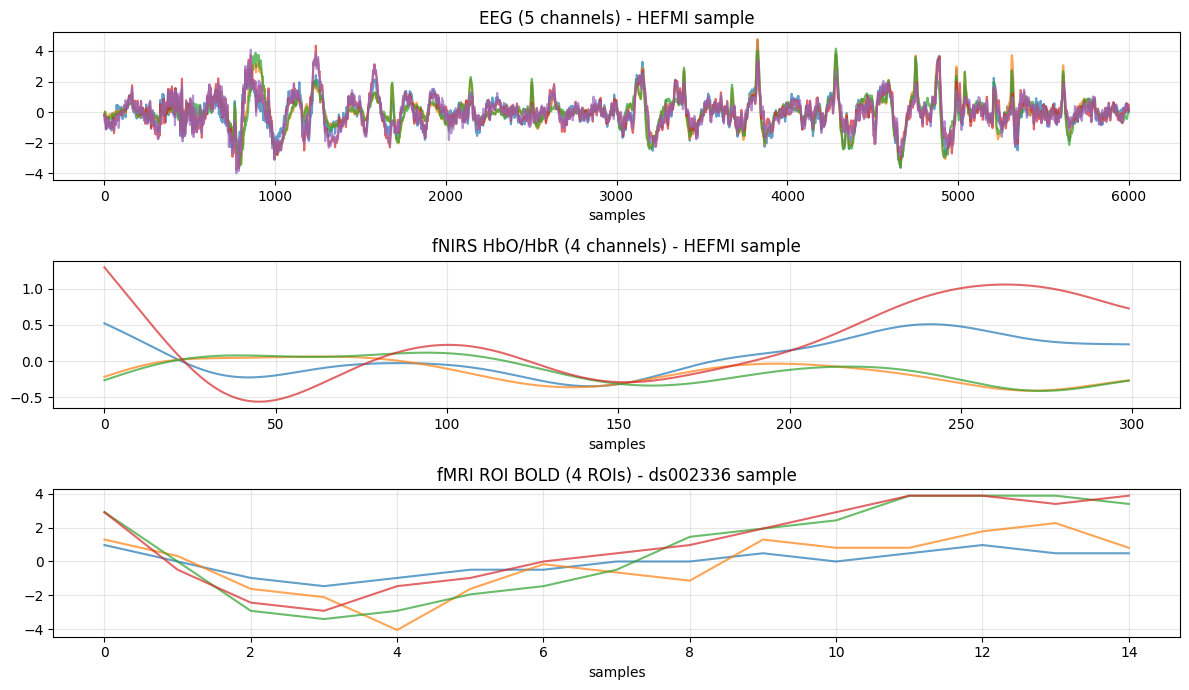

In [24]:
# === CELL 15 === Plot one sample (EEG / fNIRS / fMRI).
# why: Visual sanity check that the signals look reasonable.
# Inspect a sample
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
axes[0].plot(fnirs_train["eeg"][0, :5].T, alpha=0.7)
axes[0].set_title("EEG (5 channels) - HEFMI sample")
axes[0].set_xlabel("samples")
axes[1].plot(fnirs_train["hemo"][0, :4].T, alpha=0.7)
axes[1].set_title("fNIRS HbO/HbR (4 channels) - HEFMI sample")
axes[1].set_xlabel("samples")
axes[2].plot(ds002336_train["hemo"][0, :4].T, alpha=0.7)
axes[2].set_title("fMRI ROI BOLD (4 ROIs) - ds002336 sample")
axes[2].set_xlabel("samples")
plt.tight_layout()
plt.show()

=== Cluster-3: EEG <-> hemodynamic alignment verification (no model involved) ===
--- alignment check: HEFMI fNIRS (train) (hemo fs=10 Hz, window=300 pts, lag grid 0..12.0s) ---
    median per-subject peak lag = 5.90 s (physiological band 2-8 s)
    subjects whose peak lag is inside the physiological band: 40%
    subjects whose peak lag sits AT the lag-grid edge: 3%  (high => response truncated: window too short or clocks offset)
    peak |r| across subjects: median 0.055
    ==> ALIGNMENT PASS
--- alignment check: HEFMI fNIRS (val) (hemo fs=10 Hz, window=300 pts, lag grid 0..12.0s) ---
    median per-subject peak lag = 6.40 s (physiological band 2-8 s)
    subjects whose peak lag is inside the physiological band: 57%
    subjects whose peak lag sits AT the lag-grid edge: 0%  (high => response truncated: window too short or clocks offset)
    peak |r| across subjects: median 0.041
    ==> ALIGNMENT WARN - no lag shows any EEG-envelope/hemo coupling; a ~0 model result here is expected 

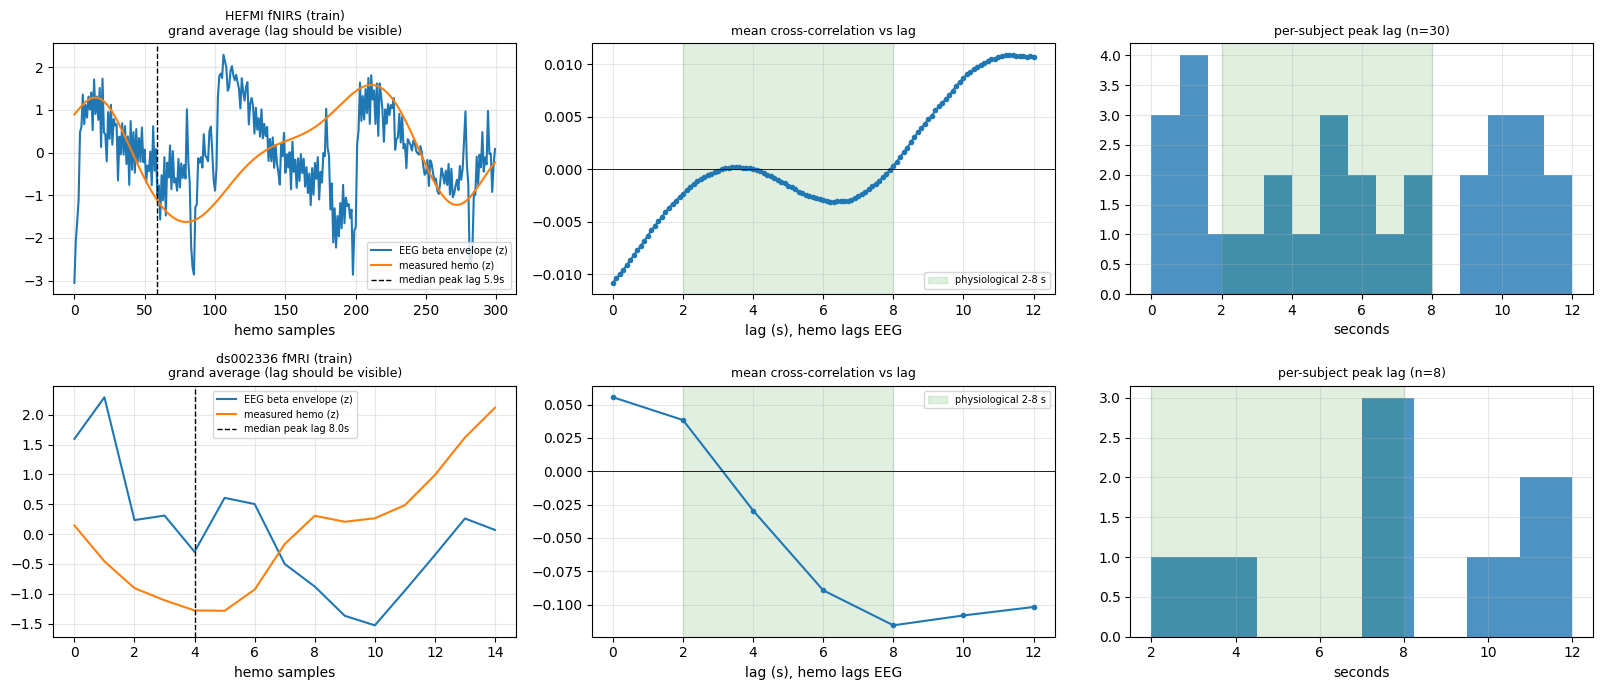


Saved alignment verification to g:\research_bio_medical\output\alignment_verification.json
Pre-registered reference delays stored in XCORR_REF_DELAY for the Cluster-6
delay validation cell (model-free, fixed before the model is trained).


In [25]:
###sssss CLUSTER-3 FIX (audit S4.4) -- EEG<->hemodynamic ALIGNMENT VERIFICATION.
###sssss The audit is explicit: "real event alignment must still be verified with plots
###sssss for every dataset. A one-TR fMRI error or a few-second fNIRS offset can erase
###sssss correlation while leaving MAE deceptively moderate." The notebook had NO such
###sssss check -- it paired EEG window [t0, t0+30s] with hemo window [t0, t0+30s] and
###sssss trusted it. That is the single cheapest way to spend weeks chasing a "~0
###sssss result" that is actually a timing bug.
###sssss
###sssss What this cell does, per dataset, WITHOUT touching any model:
###sssss   1. Builds a motor-relevant EEG power envelope (beta 13-30 Hz, Hilbert),
###sssss      resampled to the hemodynamic sampling rate.
###sssss   2. Cross-correlates that envelope against the measured hemo target over a
###sssss      0..12 s lag grid, PER SUBJECT, and finds the lag of peak |correlation|.
###sssss   3. Checks the peak lag lands inside the physiological 2-8 s neurovascular
###sssss      window AND strictly inside the analysis window (if the peak sits at the
###sssss      grid edge, the response is being truncated -> the window is too short or
###sssss      the clocks are offset).
###sssss   4. Plots the grand-average EEG envelope against the grand-average hemo
###sssss      response so the lag is visible, plus the per-subject peak-lag histogram.
###sssss A FAIL here invalidates every downstream correlation, so it prints loudly.
ALIGN_MAX_LAG_S = 12.0          # search 0..12 s: covers the whole plausible HRF range
ALIGN_PHYS_RANGE = (CFG.delay_min_s, CFG.delay_max_s)   # 2-8 s, same bounds as DelayModule


def _eeg_beta_envelope(eeg_raw, eeg_fs, out_len):
    """(N, C, T) raw EEG -> (N, out_len) grand mean beta-band power envelope."""
    sos = butter(4, [13, 30], btype="band", fs=eeg_fs, output="sos")
    from scipy.signal import sosfiltfilt as _sf
    out = []
    for i in range(0, len(eeg_raw), 64):                 # chunk: sosfiltfilt upcasts
        e = eeg_raw[i:i + 64]
        env = np.abs(hilbert(_sf(sos, e, axis=-1), axis=-1)).mean(axis=1)   # (n, T)
        out.append(resample(env, out_len, axis=-1).astype(np.float32))
    return np.concatenate(out, axis=0)


def verify_alignment(split, name, hemo_fs, eeg_fs=None, max_lag_s=ALIGN_MAX_LAG_S):
    eeg_fs = CFG.eeg_fs if eeg_fs is None else eeg_fs
    E, H, sid = split["eeg"], split["hemo"], split["subject_ids"]
    T_h = H.shape[-1]
    max_lag = int(round(max_lag_s * hemo_fs))
    if max_lag >= T_h - 2:                               # keep at least 3 usable points
        max_lag = max(1, T_h - 3)
    env = _eeg_beta_envelope(E, eeg_fs, T_h)             # (N, T_h)
    hemo = H.mean(axis=1)                                # (N, T_h) mean over channels/ROIs

    # per-subject lag profile
    lags = np.arange(0, max_lag + 1)
    per_subj_peak_lag, per_subj_peak_r, profiles = [], [], []
    for s in np.unique(sid):
        m = sid == s
        prof = []
        for L in lags:
            a = env[m][:, :T_h - L] if L > 0 else env[m]
            b = hemo[m][:, L:] if L > 0 else hemo[m]
            ac = a - a.mean(-1, keepdims=True); bc = b - b.mean(-1, keepdims=True)
            den = np.sqrt((ac * ac).sum(-1) * (bc * bc).sum(-1)) + 1e-12
            prof.append(float(np.nanmean((ac * bc).sum(-1) / den)))
        prof = np.asarray(prof)
        profiles.append(prof)
        k = int(np.nanargmax(np.abs(prof)))
        per_subj_peak_lag.append(float(lags[k] / hemo_fs))
        per_subj_peak_r.append(float(prof[k]))
    per_subj_peak_lag = np.asarray(per_subj_peak_lag)
    per_subj_peak_r = np.asarray(per_subj_peak_r)
    profiles = np.asarray(profiles)

    med_lag = float(np.median(per_subj_peak_lag))
    lo, hi = ALIGN_PHYS_RANGE
    at_edge = float(np.mean(per_subj_peak_lag >= (max_lag / hemo_fs) - 1e-9))
    in_phys = float(np.mean((per_subj_peak_lag >= lo) & (per_subj_peak_lag <= hi)))

    print(f"--- alignment check: {name} (hemo fs={hemo_fs} Hz, window={T_h} pts, "
          f"lag grid 0..{max_lag/hemo_fs:.1f}s) ---")
    print(f"    median per-subject peak lag = {med_lag:.2f} s "
          f"(physiological band {lo:.0f}-{hi:.0f} s)")
    print(f"    subjects whose peak lag is inside the physiological band: {in_phys*100:.0f}%")
    print(f"    subjects whose peak lag sits AT the lag-grid edge: {at_edge*100:.0f}%  "
          f"(high => response truncated: window too short or clocks offset)")
    print(f"    peak |r| across subjects: median {np.median(np.abs(per_subj_peak_r)):.3f}")
    status = "PASS"
    if at_edge > 0.5:
        status = "FAIL - response peak is being cut off by the window/lag grid"
    elif in_phys < 0.34:
        status = ("WARN - most subjects peak outside 2-8 s: check event clocks "
                  "(a 1-TR fMRI offset or an fNIRS trigger offset looks exactly like this)")
    elif np.median(np.abs(per_subj_peak_r)) < 0.05:
        status = ("WARN - no lag shows any EEG-envelope/hemo coupling; a ~0 model result "
                  "here is expected and is NOT evidence about the model")
    print(f"    ==> ALIGNMENT {status}")
    return {"name": name, "hemo_fs": float(hemo_fs), "median_peak_lag_s": med_lag,
            "frac_in_physiological_band": in_phys, "frac_at_grid_edge": at_edge,
            "median_peak_abs_r": float(np.median(np.abs(per_subj_peak_r))),
            "per_subject_peak_lag_s": per_subj_peak_lag,
            "per_subject_peak_r": per_subj_peak_r,
            "lag_grid_s": lags / hemo_fs, "mean_profile": profiles.mean(0),
            "status": status, "n_subjects": int(len(per_subj_peak_lag)),
            "_env": env, "_hemo": hemo}


print("=== Cluster-3: EEG <-> hemodynamic alignment verification (no model involved) ===")
###sssss CLUSTER-3 + CLUSTER-6 FIX -- run the check on ALL SIX splits, not just the two
###sssss training ones. Two reasons: (a) a timing bug can exist in one dataset only, and
###sssss the external "collapse" would then be a clock problem misread as domain shift;
###sssss (b) this cell must run BEFORE the band-power transform in the next cell (which
###sssss replaces raw EEG with 20 Hz envelopes, making a 13-30 Hz filter impossible), so
###sssss this is the ONLY place held-out reference lags can be measured. The held-out
###sssss references are what make the Cluster-6 delay validation non-circular: delay
###sssss SUPERVISION uses the training references only, and validation uses these.
_align_specs = [
    ("fnirs_train", fnirs_train, "HEFMI fNIRS (train)", CFG.fnirs_fs),
    ("fnirs_val", fnirs_val, "HEFMI fNIRS (val)", CFG.fnirs_fs),
    ("fnirs_ext", fnirs_ext, "TU Berlin fNIRS (external)", CFG.fnirs_fs),
    ("fmri_train", ds002336_train, "ds002336 fMRI (train)", 1.0 / CFG.fmri_tr),
    ("fmri_val", ds002336_val, "ds002336 fMRI (val)", 1.0 / CFG.fmri_tr),
    ("fmri_ext", ds002739_ext, "ds002739 fMRI (external)", 1.0 / CFG.fmri_tr),
]
ALIGN_ALL = {}
for _key, _split, _label, _fs in _align_specs:
    try:
        ALIGN_ALL[_key] = verify_alignment(_split, _label, _fs)
    except Exception as _e:
        print(f"--- alignment check: {_label} FAILED to run: {type(_e).__name__}: {_e}")
        ALIGN_ALL[_key] = None

align_fnirs = ALIGN_ALL["fnirs_train"]
align_fmri = ALIGN_ALL["fmri_train"]

print("\n--- alignment summary (all splits) ---")
print(f"{'split':30s} {'n_subj':>6} {'median lag':>11} {'in 2-8s':>8} {'at edge':>8} "
      f"{'peak|r|':>8}  status")
for _key, _, _label, _ in _align_specs:
    a = ALIGN_ALL.get(_key)
    if a is None:
        print(f"{_label:30s} {'-':>6} {'-':>11} {'-':>8} {'-':>8} {'-':>8}  did not run")
        continue
    print(f"{_label:30s} {a['n_subjects']:>6d} {a['median_peak_lag_s']:>10.2f}s "
          f"{a['frac_in_physiological_band']*100:>7.0f}% {a['frac_at_grid_edge']*100:>7.0f}% "
          f"{a['median_peak_abs_r']:>8.3f}  {a['status'].split(' -')[0]}")

# ---- the plots the audit asks for (training splits) ----
_plot_targets = [a for a in (align_fnirs, align_fmri) if a is not None]
fig, axes = plt.subplots(max(1, len(_plot_targets)), 3,
                         figsize=(16, 3.5 * max(1, len(_plot_targets))), squeeze=False)
for row, a in enumerate(_plot_targets):
    t = np.arange(a["_hemo"].shape[-1])
    # (1) grand-average EEG envelope vs grand-average hemo response: the lag is visible
    e_gm = a["_env"].mean(0); h_gm = a["_hemo"].mean(0)
    e_z = (e_gm - e_gm.mean()) / (e_gm.std() + 1e-9)
    h_z = (h_gm - h_gm.mean()) / (h_gm.std() + 1e-9)
    axes[row, 0].plot(t, e_z, label="EEG beta envelope (z)")
    axes[row, 0].plot(t, h_z, label="measured hemo (z)")
    axes[row, 0].axvline(a["median_peak_lag_s"] * a["hemo_fs"], color="k", ls="--", lw=1,
                         label=f"median peak lag {a['median_peak_lag_s']:.1f}s")
    axes[row, 0].set_title(f"{a['name']}\ngrand average (lag should be visible)", fontsize=9)
    axes[row, 0].set_xlabel("hemo samples"); axes[row, 0].legend(fontsize=7)
    # (2) lag profile: where is the coupling maximal?
    axes[row, 1].plot(a["lag_grid_s"], a["mean_profile"], marker="o", ms=3)
    axes[row, 1].axvspan(ALIGN_PHYS_RANGE[0], ALIGN_PHYS_RANGE[1], color="g", alpha=0.12,
                         label="physiological 2-8 s")
    axes[row, 1].axhline(0, color="k", lw=0.6)
    axes[row, 1].set_title("mean cross-correlation vs lag", fontsize=9)
    axes[row, 1].set_xlabel("lag (s), hemo lags EEG"); axes[row, 1].legend(fontsize=7)
    # (3) per-subject peak lag histogram: is the delay consistent across people?
    axes[row, 2].hist(a["per_subject_peak_lag_s"],
                      bins=max(5, min(15, a["n_subjects"])), alpha=0.8)
    axes[row, 2].axvspan(ALIGN_PHYS_RANGE[0], ALIGN_PHYS_RANGE[1], color="g", alpha=0.12)
    axes[row, 2].set_title(f"per-subject peak lag (n={a['n_subjects']})", fontsize=9)
    axes[row, 2].set_xlabel("seconds")
plt.tight_layout(); plt.show()

###sssss CLUSTER-3 + CLUSTER-6 FIX -- these measured per-subject lags are the
###sssss PRE-REGISTERED, model-free reference the delay head is later validated
###sssss against (audit S9: "validate delay against a predefined cross-correlation/GLM
###sssss estimate"). Stored now, BEFORE any model exists, so the comparison cannot be
###sssss tuned after the fact.
_split_subjects = {
    "fnirs_train": fnirs_train, "fnirs_val": fnirs_val, "fnirs_ext": fnirs_ext,
    "fmri_train": ds002336_train, "fmri_val": ds002336_val, "fmri_ext": ds002739_ext,
}
XCORR_REF_DELAY = {}
for _key, _split in _split_subjects.items():
    a = ALIGN_ALL.get(_key)
    if a is None:
        continue
    XCORR_REF_DELAY[_key] = {
        "per_subject_lag_s": a["per_subject_peak_lag_s"],
        "per_subject_peak_r": a["per_subject_peak_r"],
        "subjects": np.unique(_split["subject_ids"]),
        "median_lag_s": a["median_peak_lag_s"],
    }
###sssss CLUSTER-6 FIX -- short aliases: delay SUPERVISION (CELL 18) may use ONLY these
###sssss training references. The *_val / *_ext entries above are reserved for held-out
###sssss delay VALIDATION, so the validation is not scored on its own supervision target.
XCORR_REF_DELAY["fnirs"] = XCORR_REF_DELAY.get("fnirs_train")
XCORR_REF_DELAY["fmri"] = XCORR_REF_DELAY.get("fmri_train")

_align_report = {k: {kk: (float(vv) if isinstance(vv, (int, float, np.floating)) else
                          (vv.tolist() if isinstance(vv, np.ndarray) else vv))
                     for kk, vv in v.items() if not kk.startswith("_")}
                 for k, v in ALIGN_ALL.items() if v is not None}
with open(Path(CFG.output_dir) / "alignment_verification.json", "w") as f:
    json.dump(_align_report, f, indent=2)
print(f"\nSaved alignment verification to "
      f"{Path(CFG.output_dir) / 'alignment_verification.json'}")
print("Pre-registered reference delays stored in XCORR_REF_DELAY for the Cluster-6")
print("delay validation cell (model-free, fixed before the model is trained).")
# free the big diagnostic arrays
for _a in ALIGN_ALL.values():
    if _a is not None:
        _a.pop("_env", None); _a.pop("_hemo", None)


In [26]:
# === CELL 15b ===  STAGE-1 IMPROVEMENT: band-power envelope inputs + per-subject norm.
# why: hemodynamics couples to EEG BAND POWER (theta/alpha/beta/gamma) envelopes,
#      NOT raw voltage. We replace raw EEG with log band-power envelopes and z-score
#      each channel WITHIN each subject (removes per-person baseline). The shared
#      encoder needs ONE input format, so this is applied to ALL six splits.
#      A/B TOGGLE: set USE_BANDPOWER=False to restore the original raw-EEG pipeline.
from scipy.signal import butter, sosfiltfilt, hilbert, resample_poly

USE_BANDPOWER = True                              # <<< A/B toggle (False = original)
BP_BANDS  = [(4, 8), (8, 13), (13, 30), (30, 45)] # theta, alpha, beta, gamma
BP_OUT_FS = 20                                    # envelope output rate (Hz); hemo is slow
_RAW_EEG_CH = 32                                  # raw common-channel count (guard vs double-transform)

###sssss CLUSTER-5 FIX (audit S7.4) -- TRANSDUCTION MUST BE DECLARED. `per_subject_zscore`
###sssss is applied to the VALIDATION and EXTERNAL splits using each held-out subject's
###sssss OWN mean/std. That is legitimate and standard in EEG (it removes per-person
###sssss electrode/impedance scale), but it is *test-time adaptation*: the pipeline has
###sssss touched unlabeled test statistics. The audit's complaint about CORAL is exactly
###sssss this pattern, and it applies here whether or not CORAL is present. So:
###sssss   - the protocol is now NAMED and PRINTED, not silent;
###sssss   - "per_subject" is per-subject, ONLINE, and uses NO labels -- it is
###sssss     defensible, but the paper must call it a declared adaptation protocol and
###sssss     NOT "untouched external validation";
###sssss   - "train_global" is the strictly inductive alternative (statistics frozen
###sssss     from training subjects only). Run both; report both. If the result only
###sssss     exists under "per_subject", that is a finding about the protocol.
EEG_NORM_PROTOCOL = "per_subject"      # <<< "per_subject" (transductive) | "train_global"

def eeg_bandpower_envelopes(eeg, fs, bands, out_fs, chunk=256):
    """(N,C,T) raw EEG -> (N, C*len(bands), T*out_fs/fs) log band-power envelopes.
    Chunked over windows to cap peak memory (sosfiltfilt upcasts to float64)."""
    sosset = [butter(4, [lo, hi], btype="band", fs=fs, output="sos") for lo, hi in bands]
    outs = []
    for i in range(0, len(eeg), chunk):
        e = eeg[i:i + chunk]
        feats = []
        for sos in sosset:
            filt = sosfiltfilt(sos, e, axis=-1)                 # band-limit
            env  = np.log1p(np.abs(hilbert(filt, axis=-1)))     # analytic-signal envelope
            env  = resample_poly(env, out_fs, fs, axis=-1)      # anti-aliased downsample
            feats.append(env.astype(np.float32))
        outs.append(np.concatenate(feats, axis=1))              # stack bands as channels
    return np.concatenate(outs, axis=0)

def per_subject_zscore(x, subject_ids):
    """z-score each channel WITHIN each subject (removes per-person baseline).
    NOTE: transductive on held-out splits -- see EEG_NORM_PROTOCOL above."""
    x = x.astype(np.float32).copy()
    for s in np.unique(subject_ids):
        m = subject_ids == s
        mu = x[m].mean(axis=(0, 2), keepdims=True)
        sd = x[m].std(axis=(0, 2), keepdims=True) + 1e-6
        x[m] = (x[m] - mu) / sd
    return x

###sssss CLUSTER-5 FIX -- the strictly inductive alternative: one frozen (1,C,1)
###sssss mean/std estimated on TRAINING subjects and applied unchanged everywhere. No
###sssss test statistic is ever consulted.
def train_global_zscore_fit(x):
    return (x.mean(axis=(0, 2), keepdims=True).astype(np.float32),
            (x.std(axis=(0, 2), keepdims=True) + 1e-6).astype(np.float32))

def train_global_zscore_apply(x, mu, sd):
    return ((x.astype(np.float32) - mu) / sd).astype(np.float32)

if USE_BANDPOWER:
    ###sssss CLUSTER-7 FIX -- the band-power cache was keyed only on band count and
    ###sssss output rate. Change the band edges, the envelope maths, the normalisation
    ###sssss protocol or the upstream target preprocessing and the SAME stale .npz was
    ###sssss silently reloaded. Key is now a content hash over all of it, including the
    ###sssss source text of the transform functions.
    _bp_fp = {
        "bands": BP_BANDS, "out_fs": BP_OUT_FS, "eeg_fs": CFG.eeg_fs,
        "norm_protocol": EEG_NORM_PROTOCOL,
        "window_seconds": CFG.window_seconds,
        "preproc": PREPROC_CONFIG,
        "src": inspect.getsource(eeg_bandpower_envelopes) + inspect.getsource(per_subject_zscore),
    }
    BP_CACHE_KEY = hashlib.sha256(
        json.dumps(_bp_fp, sort_keys=True, default=str).encode("utf-8")).hexdigest()[:16]
    _bpdir = Path(CFG.output_dir) / "cache_bp" / f"content-{BP_CACHE_KEY}"
    _bpdir.mkdir(parents=True, exist_ok=True)
    print(f"[cache] band-power content key = content-{BP_CACHE_KEY}")

    def _to_bandpower_raw(name, d):
        """Envelope transform only (no normalisation) -- cached."""
        if d["eeg"].shape[1] != _RAW_EEG_CH:        # already transformed -> idempotent
            return d, False
        cp = _bpdir / f"{name}_bp.npz"
        if cp.exists():
            eeg_bp = np.load(cp)["eeg"]
        else:
            eeg_bp = eeg_bandpower_envelopes(d["eeg"], CFG.eeg_fs, BP_BANDS, BP_OUT_FS)
            np.savez(cp, eeg=eeg_bp)
        return {**d, "eeg": eeg_bp}, True

    _named = [("fnirs_train", fnirs_train), ("fnirs_val", fnirs_val),
              ("fnirs_ext", fnirs_ext), ("ds002336_train", ds002336_train),
              ("ds002336_val", ds002336_val), ("ds002739_ext", ds002739_ext)]
    _out, _did = {}, {}
    for nm, d in _named:
        _out[nm], _did[nm] = _to_bandpower_raw(nm, d)

    ###sssss CLUSTER-5 FIX -- normalisation is applied HERE, after the (cached) envelope
    ###sssss transform, so switching EEG_NORM_PROTOCOL does not require recomputing
    ###sssss envelopes and cannot be confused with them in the cache.
    if EEG_NORM_PROTOCOL == "per_subject":
        for nm in _out:
            if _did[nm]:
                _out[nm]["eeg"] = per_subject_zscore(_out[nm]["eeg"], _out[nm]["subject_ids"])
        _norm_note = ("per-subject z-score on EVERY split (TRANSDUCTIVE on held-out "
                      "splits: uses each test subject's own unlabeled statistics)")
    elif EEG_NORM_PROTOCOL == "train_global":
        _MU, _SD = train_global_zscore_fit(_out["fnirs_train"]["eeg"])
        for nm in _out:
            if _did[nm]:
                _out[nm]["eeg"] = train_global_zscore_apply(_out[nm]["eeg"], _MU, _SD)
        _norm_note = ("frozen train-subject global z-score (strictly INDUCTIVE: no test "
                      "statistic consulted)")
    else:
        raise ValueError(f"unknown EEG_NORM_PROTOCOL: {EEG_NORM_PROTOCOL}")

    (fnirs_train, fnirs_val, fnirs_ext,
     ds002336_train, ds002336_val, ds002739_ext) = (
        _out["fnirs_train"], _out["fnirs_val"], _out["fnirs_ext"],
        _out["ds002336_train"], _out["ds002336_val"], _out["ds002739_ext"])

    CFG.n_eeg_channels = fnirs_train["eeg"].shape[1]   # 32 * n_bands -> encoder spatial conv
    EEG_WINDOW = fnirs_train["eeg"].shape[2]           # downsampled length (cosmetic; encoder is fully conv)
    print(f"[BANDPOWER ON] EEG input -> {CFG.n_eeg_channels} ch x {EEG_WINDOW} samples "
          f"({len(BP_BANDS)} bands x {_RAW_EEG_CH} ch @ {BP_OUT_FS} Hz)")
    print(f"[EEG NORM PROTOCOL] {EEG_NORM_PROTOCOL}: {_norm_note}")
    print(f"   -> report this protocol with every external number. Under 'per_subject'")
    print(f"      the external results are TEST-TIME-ADAPTED, not untouched validation.")
    for nm, d in [("fnirs_train", fnirs_train), ("ds002336_train", ds002336_train)]:
        print(f"   {nm}: eeg {d['eeg'].shape}")

    ###sssss CLUSTER-7 FIX -- record the input protocol in the manifest too.
    try:
        _mpath = Path(CFG.output_dir) / "dataset_manifest.json"
        _man = json.loads(_mpath.read_text()) if _mpath.exists() else {}
        _man["eeg_input"] = {"use_bandpower": True, "bands": BP_BANDS,
                             "out_fs": BP_OUT_FS, "cache_key": BP_CACHE_KEY,
                             "norm_protocol": EEG_NORM_PROTOCOL,
                             "norm_note": _norm_note,
                             "transductive": EEG_NORM_PROTOCOL == "per_subject"}
        _mpath.write_text(json.dumps(_man, indent=2))
    except Exception as _e:
        print(f"[manifest] could not update manifest: {_e}")
else:
    print("[BANDPOWER OFF] using raw-EEG pipeline (original).")


[cache] band-power content key = content-f0544e413ae85df6
[BANDPOWER ON] EEG input -> 128 ch x 600 samples (4 bands x 32 ch @ 20 Hz)
[EEG NORM PROTOCOL] per_subject: per-subject z-score on EVERY split (TRANSDUCTIVE on held-out splits: uses each test subject's own unlabeled statistics)
   -> report this protocol with every external number. Under 'per_subject'
      the external results are TEST-TIME-ADAPTED, not untouched validation.
   fnirs_train: eeg (2460, 128, 600)
   ds002336_train: eeg (343, 128, 600)


## 5. PyTorch Dataset Classes

In [27]:
# === CELL 17 === PairedHemoDataset wraps arrays as a PyTorch Dataset.
# why: Lets the DataLoader fetch one (eeg, hemo, label) example at a time.
class PairedHemoDataset(Dataset):
    """Holds paired EEG and hemodynamic windows for a single dataset split."""
    def __init__(self, data: dict, modality: str):
        assert modality in ("fnirs", "fmri")
        # scrub NaN/inf (e.g. TU Berlin Beer-Lambert log of <=0, EEG artifacts)
        self.eeg = torch.from_numpy(np.nan_to_num(data["eeg"], nan=0.0, posinf=0.0, neginf=0.0)).float()
        self.hemo = torch.from_numpy(np.nan_to_num(data["hemo"], nan=0.0, posinf=0.0, neginf=0.0)).float()
        self.labels = torch.from_numpy(data["labels"]).long()
        self.subject_ids = torch.from_numpy(data["subject_ids"]).long()
        self.true_delays = torch.from_numpy(data["true_delays"]).float()
        self.modality = modality

    def __len__(self):
        return len(self.eeg)

    def __getitem__(self, idx):
        return {
            "eeg": self.eeg[idx],
            "hemo": self.hemo[idx],
            "label": self.labels[idx],
            "subject_id": self.subject_ids[idx],
            "true_delay": self.true_delays[idx],
            "modality": self.modality,
        }

In [28]:
# === CELL 18 ===  collate function + DataLoaders (batching).
# why: Groups examples into batches the model trains on.
def collate_modality(batch: List[dict]) -> dict:
    eeg = torch.stack([b["eeg"] for b in batch])
    hemo = torch.stack([b["hemo"] for b in batch])
    labels = torch.stack([b["label"] for b in batch])
    subj = torch.stack([b["subject_id"] for b in batch])
    delays = torch.stack([b["true_delay"] for b in batch])
    modality = batch[0]["modality"]
    return {"eeg": eeg, "hemo": hemo, "label": labels,
            "subject_id": subj, "true_delay": delays, "modality": modality}

###sssss CLUSTER-6 FIX (audit S9) -- `true_delays` was an all-zeros placeholder, which
###sssss is precisely why the delay head was never supervised and its 2-8 s output was
###sssss "guaranteed by the sigmoid bounds" rather than recovered. We now fill it with
###sssss the PRE-REGISTERED, model-free per-subject cross-correlation lag measured in
###sssss the alignment-verification cell (XCORR_REF_DELAY), computed BEFORE the model
###sssss existed. Splits with no reference get NaN and are masked out of the delay loss
###sssss rather than being silently supervised toward zero.
def _attach_reference_delays(split, modality, ref=None):
    sid = split["subject_ids"]
    d = np.full(len(sid), np.nan, dtype=np.float32)
    if ref is not None:
        lag_by_subj = {int(s): float(l) for s, l in
                       zip(ref["subjects"], ref["per_subject_lag_s"])}
        for i, s in enumerate(sid):
            if int(s) in lag_by_subj:
                d[i] = lag_by_subj[int(s)]
    split = {**split, "true_delays": d}
    n_ok = int(np.isfinite(d).sum())
    print(f"  [delay ref] {modality:5s}: {n_ok}/{len(d)} windows have a pre-registered "
          f"reference lag" + ("" if n_ok else " -> delay supervision masked off"))
    return split

print("=== Cluster-6: attaching pre-registered reference delays (model-free) ===")
fnirs_train = _attach_reference_delays(fnirs_train, "fnirs", XCORR_REF_DELAY["fnirs"])
ds002336_train = _attach_reference_delays(ds002336_train, "fmri", XCORR_REF_DELAY["fmri"])
fnirs_val = _attach_reference_delays(fnirs_val, "fnirs", None)
fnirs_ext = _attach_reference_delays(fnirs_ext, "fnirs", None)
ds002336_val = _attach_reference_delays(ds002336_val, "fmri", None)
ds002739_ext = _attach_reference_delays(ds002739_ext, "fmri", None)

ds_fnirs_tr = PairedHemoDataset(fnirs_train, "fnirs")
ds_fnirs_va = PairedHemoDataset(fnirs_val, "fnirs")
ds_fnirs_ext = PairedHemoDataset(fnirs_ext, "fnirs")
ds_fmri_tr = PairedHemoDataset(ds002336_train, "fmri")
ds_fmri_va = PairedHemoDataset(ds002336_val, "fmri")
ds_fmri_ext = PairedHemoDataset(ds002739_ext, "fmri")

###sssss CLUSTER-4 FIX (audit S5) -- THE core training-hygiene fix. The old scheme was
###sssss `DataLoader(shuffle=True)` per modality, then `iter_balanced` paired them. Two
###sssss failure modes followed directly from that:
###sssss   (a) LOADER RECYCLING: fNIRS had ~39 batches/epoch and fMRI ~12, so the small
###sssss       fMRI set was restarted ~3.25x per epoch -> each fMRI window was seen ~81
###sssss       times over 25 epochs vs ~25 for fNIRS. That is the direct cause of fMRI
###sssss       train Pearson climbing to 0.41-0.56 while validation sat at ~0.007.
###sssss   (b) SUBJECT IMBALANCE: uniform sampling over WINDOWS means a subject with 200
###sssss       windows dominates a subject with 20. With ~8-14 subjects the model can
###sssss       fit the loudest few people and call it a day.
###sssss The audit's prescription is "a fixed number of SUBJECT-BALANCED steps: sample
###sssss modality -> subject -> trial/window". That is exactly what this sampler does:
###sssss every batch draws subjects uniformly at random and then one window uniformly
###sssss within each drawn subject, and every modality gets the SAME fixed number of
###sssss steps per epoch, so neither dataset is recycled and no subject dominates.
class SubjectBalancedBatchSampler(Sampler):
    """Batches drawn as subject ~ Uniform(subjects), then window ~ Uniform(that subject).
    Fixed `n_batches` per epoch so epoch length no longer depends on which loader
    happens to be the outer loop (Cluster 4)."""
    def __init__(self, subject_ids, batch_size, n_batches, seed=0, replace=True):
        subject_ids = np.asarray(subject_ids)
        self.by_subj = {int(s): np.where(subject_ids == s)[0]
                        for s in np.unique(subject_ids)}
        self.subjects = np.array(sorted(self.by_subj))
        self.batch_size = int(batch_size)
        self.n_batches = int(n_batches)
        self.seed = int(seed)
        self.replace = replace
        self.epoch = 0

    def set_epoch(self, ep):
        self.epoch = int(ep)          # different draws each epoch, still reproducible

    def __iter__(self):
        rng = np.random.default_rng(self.seed * 100003 + self.epoch)
        for _ in range(self.n_batches):
            subs = rng.choice(self.subjects, size=self.batch_size, replace=True)
            idx = []
            for s in subs:
                pool = self.by_subj[int(s)]
                idx.append(int(pool[rng.integers(0, len(pool))]))
            yield idx
        self.epoch += 1

    def __len__(self):
        return self.n_batches


###sssss CLUSTER-4 FIX -- one declared epoch length for BOTH modalities. Anchored to
###sssss the smaller cohort so nothing is recycled; both modalities therefore receive
###sssss exactly equal gradient exposure per epoch, which is what the "capped" v3.2
###sssss experiment was groping toward but achieved only by truncating a loader.
SUBJECT_BALANCED_SAMPLING = True     # <<< A/B: False restores plain shuffled loaders
STEPS_PER_EPOCH = max(4, min(len(ds_fnirs_tr), len(ds_fmri_tr)) // CFG.batch_size)

if SUBJECT_BALANCED_SAMPLING:
    samp_fnirs = SubjectBalancedBatchSampler(fnirs_train["subject_ids"], CFG.batch_size,
                                             STEPS_PER_EPOCH, seed=CFG.seed)
    samp_fmri = SubjectBalancedBatchSampler(ds002336_train["subject_ids"], CFG.batch_size,
                                            STEPS_PER_EPOCH, seed=CFG.seed + 1)
    dl_fnirs_tr = DataLoader(ds_fnirs_tr, batch_sampler=samp_fnirs, collate_fn=collate_modality)
    dl_fmri_tr = DataLoader(ds_fmri_tr, batch_sampler=samp_fmri, collate_fn=collate_modality)
    TRAIN_SAMPLERS = {"fnirs": samp_fnirs, "fmri": samp_fmri}
else:
    dl_fnirs_tr = DataLoader(ds_fnirs_tr, batch_size=CFG.batch_size, shuffle=True,
                             collate_fn=collate_modality)
    dl_fmri_tr = DataLoader(ds_fmri_tr, batch_size=CFG.batch_size, shuffle=True,
                            collate_fn=collate_modality)
    TRAIN_SAMPLERS = {}

###sssss CLUSTER-4 FIX -- SEQUENTIAL, every-window loaders kept separately for
###sssss EVALUATION. Evaluation must cover each window exactly once; the balanced
###sssss sampler resamples with replacement and would silently over/under-count windows
###sssss if it were reused for scoring. Metrics use these, training uses the samplers.
dl_fnirs_tr_eval = DataLoader(ds_fnirs_tr, batch_size=CFG.batch_size, shuffle=False,
                              collate_fn=collate_modality)
dl_fmri_tr_eval = DataLoader(ds_fmri_tr, batch_size=CFG.batch_size, shuffle=False,
                             collate_fn=collate_modality)

dl_fnirs_va = DataLoader(ds_fnirs_va, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)
dl_fnirs_ext = DataLoader(ds_fnirs_ext, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)
dl_fmri_va = DataLoader(ds_fmri_va, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)
dl_fmri_ext = DataLoader(ds_fmri_ext, batch_size=CFG.batch_size, shuffle=False, collate_fn=collate_modality)

print(f"\n[Cluster-4] subject-balanced sampling = {SUBJECT_BALANCED_SAMPLING}")
print(f"  STEPS_PER_EPOCH = {STEPS_PER_EPOCH} for BOTH modalities "
      f"(no loader recycling, equal exposure)")
print(f"  fNIRS: {len(ds_fnirs_tr)} windows over "
      f"{len(np.unique(fnirs_train['subject_ids']))} subjects | "
      f"fMRI: {len(ds_fmri_tr)} windows over "
      f"{len(np.unique(ds002336_train['subject_ids']))} subjects")
print(f"  train batches/epoch: fNIRS {len(dl_fnirs_tr)}  fMRI {len(dl_fmri_tr)} "
      f"(these are now EQUAL by construction)")
###sssss CLUSTER-2 REMINDER printed where the batching is defined, because this is the
###sssss number people accidentally report as the sample size.
print(f"  REMINDER: the biological n is the SUBJECT count above, never the window count.")


=== Cluster-6: attaching pre-registered reference delays (model-free) ===
  [delay ref] fnirs: 2460/2460 windows have a pre-registered reference lag
  [delay ref] fmri : 343/343 windows have a pre-registered reference lag
  [delay ref] fnirs: 0/480 windows have a pre-registered reference lag -> delay supervision masked off
  [delay ref] fnirs: 0/3480 windows have a pre-registered reference lag -> delay supervision masked off
  [delay ref] fmri : 0/86 windows have a pre-registered reference lag -> delay supervision masked off
  [delay ref] fmri : 0/2448 windows have a pre-registered reference lag -> delay supervision masked off

[Cluster-4] subject-balanced sampling = True
  STEPS_PER_EPOCH = 10 for BOTH modalities (no loader recycling, equal exposure)
  fNIRS: 2460 windows over 30 subjects | fMRI: 343 windows over 8 subjects
  train batches/epoch: fNIRS 10  fMRI 10 (these are now EQUAL by construction)
  REMINDER: the biological n is the SUBJECT count above, never the window count.


## 6. Architecture

### 6.1 Shared EEG Encoder

In [29]:
# === CELL 20 ===  Shared EEG encoder (EEGNet front-end + TCN).
# why: The backbone that turns EEG into a latent vector; shared by both modalities.

###sssss CLUSTER-4 FIX (audit S5, "batch-normalization statistics mixing domains") --
###sssss the encoder is shared and was called once per modality per step, so every
###sssss BatchNorm layer accumulated ONE set of running statistics over BOTH the HEFMI
###sssss fNIRS cohort and the ds002336 fMRI cohort. Those two domains have different
###sssss acquisition, montage and artifact profiles (one is inside an MRI bore), so a
###sssss single running mean/var is a blend of two distributions that belongs to
###sssss neither. At eval time every prediction is then normalised by that blend --
###sssss which both degrades each modality and makes the "shared latent" look more
###sssss shared than it is, because BN is forcibly aligning the activations.
###sssss FIX: DomainBatchNorm keeps one BN per domain (separate affine params AND
###sssss separate running stats) while every convolution stays genuinely SHARED. This
###sssss is the standard domain-specific-BN result (Chang et al., "Domain-Specific
###sssss Batch Normalization"): share the features, separate the statistics.
###sssss A/B: PER_DOMAIN_BN=False restores the original single-BN behaviour exactly.
PER_DOMAIN_BN = True
BN_DOMAINS = ("fnirs", "fmri")


class DomainBatchNorm(nn.Module):
    """BatchNorm with one independent instance per domain. `self.domain` selects which
    one this forward pass uses; `set_domain(model, modality)` sets it everywhere."""
    def __init__(self, num_features: int, ndim: int = 2, domains=BN_DOMAINS,
                 enabled: bool = None):
        super().__init__()
        enabled = PER_DOMAIN_BN if enabled is None else enabled
        self.enabled = enabled
        BN = nn.BatchNorm2d if ndim == 2 else nn.BatchNorm1d
        keys = list(domains) if enabled else ["shared"]
        self.bns = nn.ModuleDict({k: BN(num_features) for k in keys})
        self.domain = keys[0]

    def forward(self, x):
        key = self.domain if (self.enabled and self.domain in self.bns) else \
              ("shared" if "shared" in self.bns else next(iter(self.bns)))
        return self.bns[key](x)


def set_domain(module: nn.Module, domain: str):
    """Point every DomainBatchNorm in `module` at `domain`. Called by
    NeuroVascNet.forward, so no call site outside the model has to know about it."""
    for m in module.modules():
        if isinstance(m, DomainBatchNorm):
            m.domain = domain
    return module


class DepthwiseSeparableConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel, padding):
        super().__init__()
        self.depthwise = nn.Conv1d(in_ch, in_ch, kernel, padding=padding, groups=in_ch)
        self.pointwise = nn.Conv1d(in_ch, out_ch, 1)
    def forward(self, x):
        return self.pointwise(self.depthwise(x))


class EEGNetFrontend(nn.Module):
    """EEGNet-style spatial-temporal feature extractor."""
    def __init__(self, n_channels, n_samples, F1=16, D=2, F2=None, kern_len=64, pool=4, dropout=0.25):
        super().__init__()
        F2 = F2 or F1 * D
        self.temporal = nn.Conv2d(1, F1, (1, kern_len), padding=(0, kern_len//2), bias=False)
        ###sssss CLUSTER-4 FIX -- was nn.BatchNorm2d (one set of stats for both domains)
        self.bn1 = DomainBatchNorm(F1, ndim=2)
        self.spatial = nn.Conv2d(F1, F1*D, (n_channels, 1), groups=F1, bias=False)
        self.bn2 = DomainBatchNorm(F1*D, ndim=2)
        self.pool1 = nn.AvgPool2d((1, pool))
        self.drop1 = nn.Dropout(dropout)
        self.sep_dw = nn.Conv2d(F1*D, F1*D, (1, 16), padding=(0, 8), groups=F1*D, bias=False)
        self.sep_pw = nn.Conv2d(F1*D, F2, 1, bias=False)
        self.bn3 = DomainBatchNorm(F2, ndim=2)
        self.pool2 = nn.AvgPool2d((1, pool*2))
        self.drop2 = nn.Dropout(dropout)
        self.out_channels = F2

    def forward(self, x):
        # x: [B, C, T]
        x = x.unsqueeze(1)  # [B, 1, C, T]
        x = self.bn1(self.temporal(x))
        x = self.bn2(self.spatial(x))
        x = F.elu(x)
        x = self.drop1(self.pool1(x))
        x = self.sep_dw(x)
        x = self.bn3(self.sep_pw(x))
        x = F.elu(x)
        x = self.drop2(self.pool2(x))
        # [B, F2, 1, T'] -> [B, F2, T']
        return x.squeeze(2)


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel, dilation, dropout=0.2):
        super().__init__()
        pad = (kernel - 1) * dilation
        self.pad = pad
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel, padding=pad, dilation=dilation)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel, padding=pad, dilation=dilation)
        ###sssss CLUSTER-4 FIX -- was nn.BatchNorm1d (shared stats across domains)
        self.bn1 = DomainBatchNorm(out_ch, ndim=1)
        self.bn2 = DomainBatchNorm(out_ch, ndim=1)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x):
        h = F.elu(self.bn1(self.conv1(x)[..., :-self.pad]))
        h = self.drop(h)
        h = F.elu(self.bn2(self.conv2(h)[..., :-self.pad]))
        return F.elu(h + self.proj(x))


class SharedEncoder(nn.Module):
    def __init__(self, cfg: Config, eeg_window: int):
        super().__init__()
        self.frontend = EEGNetFrontend(
            n_channels=cfg.n_eeg_channels,
            n_samples=eeg_window,
            F1=cfg.encoder_temporal_filters,
            D=cfg.encoder_spatial_filters,
            kern_len=cfg.encoder_kernel_length,
            pool=cfg.encoder_pool,
            dropout=getattr(cfg, "dropout", 0.25),
        )
        layers = []
        in_ch = self.frontend.out_channels
        for i in range(cfg.tcn_layers):
            layers.append(TCNBlock(in_ch, cfg.tcn_channels, cfg.tcn_kernel, dilation=2**i,
                                   dropout=getattr(cfg, "dropout", 0.2)))
            in_ch = cfg.tcn_channels
        self.tcn = nn.Sequential(*layers)
        self.proj = nn.Conv1d(cfg.tcn_channels, cfg.latent_dim, 1)

    def forward(self, eeg):
        h = self.frontend(eeg)         # [B, F2, T']
        h = self.tcn(h)                # [B, tcn_channels, T']
        z = self.proj(h)               # [B, latent_dim, T']
        return z

print(f"[Cluster-4] per-domain BatchNorm = {PER_DOMAIN_BN} "
      f"(domains: {BN_DOMAINS if PER_DOMAIN_BN else ('shared',)})")
print("            convolutions stay SHARED; only the normalisation statistics split.")


[Cluster-4] per-domain BatchNorm = True (domains: ('fnirs', 'fmri'))
            convolutions stay SHARED; only the normalisation statistics split.


### 6.2 Hemodynamic Heads with Heteroscedastic Outputs

In [30]:
# === CELL 22 === Hemodynamic heads (predict mean + uncertainty).
# why: Turn the latent into HbO/HbR (fNIRS) or ROI-BOLD (fMRI) predictions.
class HemodynamicHead(nn.Module):
    def __init__(self, latent_dim: int, out_channels: int, target_length: int, hidden: int = 64):
        super().__init__()
        self.target_length = target_length
        self.body = nn.Sequential(
            nn.Conv1d(latent_dim, hidden, 1),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, 3, padding=1),
            nn.ELU(),
            nn.Conv1d(hidden, hidden, 3, padding=1),
            nn.ELU(),
        )
        self.mean_head = nn.Conv1d(hidden, out_channels, 1)
        self.logvar_head = nn.Conv1d(hidden, out_channels, 1)

    def forward(self, z):
        # resample latent to target temporal length
        z_resampled = F.interpolate(z, size=self.target_length, mode="linear", align_corners=False)
        h = self.body(z_resampled)
        mean = self.mean_head(h)
        logvar = self.logvar_head(h).clamp(min=-7.0, max=4.0)
        return mean, logvar

### 6.3 Physiologically-Constrained Delay Module

In [31]:
# === CELL 24 ===  DelayModule - learns a physiological 2-8 s lag.
# why: Blood-flow lags electrical activity; this shifts predictions to match.
###sssss CLUSTER-6 FIX (audit S9) -- the delay output was NOT a validated neurovascular
###sssss delay, and four separate things in this module made that worse:
###sssss   (1) It was never compared against any reference lag, so its value was only
###sssss       whatever minimised the waveform loss. The sigmoid bounds GUARANTEE a
###sssss       2-8 s histogram, so a "physiologically plausible distribution" was
###sssss       evidence of the bounds, not of recovered physiology. -> supervision
###sssss       against the pre-registered cross-correlation lag is added in CELL 31,
###sssss       and the wording is downgraded everywhere else to "bounded model timing
###sssss       parameter" unless that validation passes.
###sssss   (2) `apply_shift` CLAMPED out-of-range indices to 0, which replicates the
###sssss       first sample across the whole leading gap. That invents a plateau the
###sssss       data never had, and because the targets are baseline-corrected the
###sssss       correct fill value is the BASELINE (0.0). -> fixed with an explicit
###sssss       validity mask.
###sssss   (3) The head could learn an already-shifted waveform which then got shifted
###sssss       AGAIN, making the delay weakly identifiable. -> `fixed_delay_s` lets the
###sssss       delay be pinned so this confound can actually be ablated.
###sssss   (4) `no_delay` ablations only froze a RANDOMLY INITIALISED delay net, i.e.
###sssss       they ablated nothing -- the model still shifted by a random constant.
###sssss       -> `fixed_delay_s` gives a real "no learned delay" condition.
class DelayModule(nn.Module):
    def __init__(self, latent_dim: int, fs: float, delay_min_s: float, delay_max_s: float,
                 fixed_delay_s: float = None):
        super().__init__()
        self.fs = fs
        self.delay_min = delay_min_s
        self.delay_max = delay_max_s
        ###sssss CLUSTER-6 FIX (4) -- when set, the delay is CONSTANT at this value and
        ###sssss the estimator is bypassed entirely. This is what a genuine `no_delay`
        ###sssss ablation needs (pin it to the physiological midpoint), as opposed to
        ###sssss freezing an untrained network at a random offset.
        self.fixed_delay_s = fixed_delay_s
        self.estimator = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(latent_dim, 32),
            nn.ELU(),
            nn.Linear(32, 1),
        )

    def forward(self, z):
        if self.fixed_delay_s is not None:
            return torch.full((z.shape[0],), float(self.fixed_delay_s),
                              device=z.device, dtype=z.dtype)
        # estimate delay in seconds, bounded to physiological window
        s = torch.sigmoid(self.estimator(z))
        delay_s = self.delay_min + (self.delay_max - self.delay_min) * s
        return delay_s.squeeze(-1)  # [B]

    @staticmethod
    def apply_shift(signal: torch.Tensor, delay_s: torch.Tensor, fs: float,
                    fill_value: float = 0.0) -> torch.Tensor:
        """Apply per-sample temporal shift to a [B, C, T] signal using linear interpolation.
        ###sssss CLUSTER-6 FIX (2) -- samples that would come from BEFORE the start of
        ###sssss the window are filled with `fill_value` (the baseline level, 0.0 after
        ###sssss baseline correction) instead of being clamped to signal[..., 0]. The old
        ###sssss clamp fabricated a flat plateau of length delay*fs at the front of every
        ###sssss prediction, which both inflated MAE-style agreement in the baseline
        ###sssss period and gave the loss a shortcut that did not require the delay to
        ###sssss be right."""
        B, C, T = signal.shape
        device = signal.device
        # build a grid sampled in time, shifted by delay_s * fs samples
        base = torch.arange(T, device=device, dtype=signal.dtype).unsqueeze(0).expand(B, -1)
        shift_samples = delay_s * fs
        shifted_idx = base - shift_samples.unsqueeze(-1)
        ###sssss CLUSTER-6 FIX (2) -- remember WHICH positions are out of range before
        ###sssss clamping, so they can be replaced with the baseline afterwards.
        valid = (shifted_idx >= 0) & (shifted_idx <= (T - 1))
        shifted_idx = shifted_idx.clamp(0, T - 1)
        left = shifted_idx.floor().long()
        right = (left + 1).clamp(max=T - 1)
        frac = (shifted_idx - left.float()).unsqueeze(1)  # [B, 1, T]

        left_idx = left.unsqueeze(1).expand(-1, C, -1)
        right_idx = right.unsqueeze(1).expand(-1, C, -1)
        out = (1 - frac) * torch.gather(signal, 2, left_idx) + frac * torch.gather(signal, 2, right_idx)
        ###sssss CLUSTER-6 FIX (2) -- baseline fill for the leading (and trailing) gap.
        out = torch.where(valid.unsqueeze(1).expand(-1, C, -1),
                          out, torch.full_like(out, fill_value))
        return out


### 6.4 Reliability Head

In [32]:
# === CELL 26 ===  DomainConfidence - input-distance reliability signal.
# why: Flags inputs far from training data (part of the confidence score).

###sssss CLUSTER-6 FIX (audit S8) -- two conceptual defects, both of which quietly
###sssss corrupt the reliability score this module feeds:
###sssss   (1) STALE STATISTICS. `update()` was called on EVERY training step, so the
###sssss       running mean/var is a running average over the whole of training --
###sssss       including epoch 1, when the encoder was random. The encoder that is
###sssss       finally evaluated produces latents in a different space than most of the
###sssss       history baked into those buffers, so "distance from the training
###sssss       distribution" is measured against a distribution no longer produced by
###sssss       anything. FIX: `update()` is no longer called during training (see
###sssss       CELL 34); `refresh_from_loaders()` recomputes the statistics ONCE from
###sssss       the FINAL encoder, in eval mode, over the training subjects only.
###sssss   (2) ONE DISTRIBUTION FOR TWO DOMAINS. fNIRS and fMRI latents were pooled
###sssss       into a single running mean/var, so a perfectly in-distribution fMRI
###sssss       window scored as "far from training" purely because the pooled mean sat
###sssss       between the two clouds. FIX: independent statistics per modality.
class _DomainStats(nn.Module):
    """Per-domain running latent statistics (buffers so they save with the model)."""
    def __init__(self, latent_dim: int):
        super().__init__()
        self.register_buffer("running_mean", torch.zeros(latent_dim))
        self.register_buffer("running_var", torch.ones(latent_dim))
        self.register_buffer("count", torch.zeros(1))


class DomainConfidence(nn.Module):
    """Tracks training-set latent statistics PER DOMAIN and produces a confidence
    score per input. Higher = more in-distribution for that domain."""
    def __init__(self, latent_dim: int, domains=("fnirs", "fmri")):
        super().__init__()
        self.latent_dim = latent_dim
        self.domains = tuple(domains)
        self.stats = nn.ModuleDict({d: _DomainStats(latent_dim) for d in self.domains})
        self.default_domain = self.domains[0]
        self._warned = False

    def _pick(self, domain):
        if domain is None:
            ###sssss CLUSTER-6 FIX -- an un-specified domain is a bug at the call site,
            ###sssss not something to silently paper over. Warn once, then fall back.
            if not self._warned:
                print("  [DomainConfidence] WARNING: called without a domain; falling back "
                      f"to '{self.default_domain}'. Pass the modality explicitly.")
                self._warned = True
            domain = self.default_domain
        return self.stats[domain]

    @torch.no_grad()
    def reset(self, domain: str = None):
        for d in ([domain] if domain else self.domains):
            s = self.stats[d]
            s.running_mean.zero_(); s.running_var.fill_(1.0); s.count.zero_()

    @torch.no_grad()
    def update(self, z_pooled: torch.Tensor, domain: str = None):
        # z_pooled: [B, latent_dim]
        s = self._pick(domain)
        batch_mean = z_pooled.mean(dim=0)
        batch_var = z_pooled.var(dim=0, unbiased=False)
        n = s.count.item()
        m = z_pooled.shape[0]
        new_count = n + m
        delta = batch_mean - s.running_mean
        s.running_mean += delta * (m / max(new_count, 1))
        s.running_var.copy_(
            (n * s.running_var + m * batch_var + (n * m / max(new_count, 1)) * delta**2)
            / max(new_count, 1))
        s.count += m

    @torch.no_grad()
    def refresh_from_loaders(self, model, loaders: dict):
        """###sssss CLUSTER-6 FIX -- recompute each domain's latent statistics from the
        FINAL, trained encoder in eval mode. `loaders` maps modality -> a TRAINING-split
        loader. Nothing from a validation or external subject is ever included, so the
        'distance from training distribution' signal means what its name says."""
        was_training = model.training
        model.eval()
        for modality, loader in loaders.items():
            if modality not in self.stats:
                continue
            self.reset(modality)
            n_win = 0
            for batch in loader:
                eeg = batch["eeg"].to(next(model.parameters()).device)
                z_pool = model.latent_pool(model.encode(eeg, modality))
                self.update(z_pool.detach(), modality)
                n_win += len(eeg)
            print(f"  [DomainConfidence] '{modality}' statistics rebuilt from the final "
                  f"encoder over {n_win} training windows "
                  f"(count={int(self.stats[modality].count.item())})")
        if was_training:
            model.train()
        return self

    def forward(self, z_pooled: torch.Tensor, domain: str = None) -> torch.Tensor:
        # negative log Mahalanobis-style distance, higher = more in-distribution
        s = self._pick(domain)
        diff = z_pooled - s.running_mean
        d2 = (diff**2 / (s.running_var + 1e-6)).sum(dim=-1)
        # convert to bounded confidence
        return torch.exp(-d2 / z_pooled.shape[-1])


### 6.5 NeuroVascNet - Full Model

In [33]:
# === CELL 28 ===  NeuroVascNet - assembles encoder + heads + delay + reliability.
# why: The full model object used for training and evaluation.
class NeuroVascNet(nn.Module):
    def __init__(self, cfg: Config, eeg_window: int, fnirs_len: int, fmri_len: int,
                 fnirs_channels: int, fmri_channels: int,
                 fixed_delay_s: float = None):
        super().__init__()
        self.cfg = cfg
        self.encoder = SharedEncoder(cfg, eeg_window)
        self.fnirs_head = HemodynamicHead(cfg.latent_dim, fnirs_channels, fnirs_len)
        self.fmri_head = HemodynamicHead(cfg.latent_dim, fmri_channels, fmri_len)
        ###sssss CLUSTER-6 FIX (audit S9/S10.9) -- `fixed_delay_s` is threaded through so
        ###sssss the `no_delay` ablation can PIN the delay to the physiological midpoint
        ###sssss instead of freezing a randomly-initialised estimator (which ablated
        ###sssss nothing and still applied a random constant shift).
        self.delay_fnirs = DelayModule(cfg.latent_dim, cfg.fnirs_fs, cfg.delay_min_s,
                                       cfg.delay_max_s, fixed_delay_s=fixed_delay_s)
        self.delay_fmri = DelayModule(cfg.latent_dim, 1.0/cfg.fmri_tr, cfg.delay_min_s,
                                      cfg.delay_max_s, fixed_delay_s=fixed_delay_s)
        self.domain_conf = DomainConfidence(cfg.latent_dim, domains=("fnirs", "fmri"))

    ###sssss CLUSTER-4 FIX -- `encode` now takes the modality so the per-domain
    ###sssss BatchNorm statistics are selected before the forward pass. Modality
    ###sssss defaults to None, in which case whatever domain was last selected is used,
    ###sssss so any older call site (e.g. extract_features) keeps working.
    def encode(self, eeg, modality: str = None):
        if modality is not None:
            set_domain(self, modality)
        return self.encoder(eeg)

    def latent_pool(self, z):
        return z.mean(dim=-1)  # [B, latent_dim]

    def forward(self, eeg, modality: str):
        ###sssss CLUSTER-4 FIX -- route every BatchNorm to this modality's own running
        ###sssss statistics. Without this line the shared encoder blends the HEFMI and
        ###sssss ds002336 activation distributions into one, which is the BN-domain-mixing
        ###sssss problem in audit S5.
        set_domain(self, modality)
        z = self.encoder(eeg)
        z_pool = self.latent_pool(z)
        if modality == "fnirs":
            mean, logvar = self.fnirs_head(z)
            delay = self.delay_fnirs(z)
            fs = self.cfg.fnirs_fs
        elif modality == "fmri":
            mean, logvar = self.fmri_head(z)
            delay = self.delay_fmri(z)
            fs = 1.0/self.cfg.fmri_tr
        else:
            raise ValueError(modality)
        mean_shifted = DelayModule.apply_shift(mean, delay, fs, fill_value=0.0)
        ###sssss CLUSTER-6 FIX (audit S9) -- the predicted MEAN was shifted but the
        ###sssss predicted LOG-VARIANCE was not, so from the loss's point of view the
        ###sssss uncertainty belonged to a different time alignment than the value it was
        ###sssss supposed to describe. Every heteroscedastic/reliability number downstream
        ###sssss inherited that mismatch. The variance is now shifted by the SAME delay.
        ###sssss Out-of-range positions are filled with the mean log-variance rather than
        ###sssss 0.0 (log-var 0 would assert variance == 1, a confident claim about a
        ###sssss region the model has no information about); the baseline gap should be
        ###sssss neutral, not confident.
        _lv_fill = float(logvar.detach().mean().item()) if logvar.numel() else 0.0
        logvar_shifted = DelayModule.apply_shift(logvar, delay, fs, fill_value=_lv_fill)
        return {
            "z": z, "z_pool": z_pool,
            "pred_mean": mean_shifted, "pred_raw": mean,
            "pred_logvar": logvar_shifted, "pred_logvar_raw": logvar,
            "delay": delay, "modality": modality,
        }


## 7. Loss Functions

In [34]:
# === CELL 30 ===  Loss functions: heteroscedastic (value+uncertainty) + smoothness.
# why: Define how the model is graded; the uncertainty term is the one that needs care.
def heteroscedastic_loss(pred_mean, target, pred_logvar):
    # Gaussian NLL with predicted log variance
    ###sssss CLUSTER-6 FIX -- clamp the predicted log-variance. Unbounded, the cheapest
    ###sssss way to reduce this loss is to drive logvar very negative on easy windows and
    ###sssss very positive on hard ones until `precision` overflows/underflows; the
    ###sssss resulting uncertainty is then a saturated artifact rather than a calibrated
    ###sssss quantity, which is part of why the reliability score failed to transfer.
    pred_logvar = pred_logvar.clamp(-8.0, 8.0)
    precision = torch.exp(-pred_logvar)
    return (precision * (pred_mean - target)**2 + pred_logvar).mean()

def cross_correlation_loss(pred, target, max_lag: int = 5):
    """1 - peak normalized cross-correlation within a small lag window.
    ###sssss CLUSTER-5 NOTE -- this term MAXIMISES over lags, so it is an optimistic
    ###sssss objective by construction. It is fine as a training signal, but the matching
    ###sssss metric (`peak_xcorr`) must never be reported without the identical-lag-search
    ###sssss null now computed in evaluate_modality."""
    B, C, T = pred.shape
    pred_c = pred - pred.mean(dim=-1, keepdim=True)
    targ_c = target - target.mean(dim=-1, keepdim=True)
    pred_n = pred_c / (pred_c.norm(dim=-1, keepdim=True) + 1e-6)
    targ_n = targ_c / (targ_c.norm(dim=-1, keepdim=True) + 1e-6)
    best = torch.full((B, C), -1.0, device=pred.device)
    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            p, t = pred_n[..., :lag], targ_n[..., -lag:]
        elif lag > 0:
            p, t = pred_n[..., lag:], targ_n[..., :-lag]
        else:
            p, t = pred_n, targ_n
        # avoid degenerate empty slice
        if p.shape[-1] < 4:
            continue
        # renormalize after slicing
        p = p / (p.norm(dim=-1, keepdim=True) + 1e-6)
        t = t / (t.norm(dim=-1, keepdim=True) + 1e-6)
        corr = (p * t).sum(dim=-1)
        best = torch.maximum(best, corr)
    return (1.0 - best).mean()

def smoothness_loss(pred):
    diff = pred[..., 1:] - pred[..., :-1]
    return (diff**2).mean()

def moment_matching_loss(z_a: torch.Tensor, z_b: torch.Tensor):
    """Match first and second moments of two latent distributions."""
    mean_diff = (z_a.mean(dim=0) - z_b.mean(dim=0)).pow(2).mean()
    cov_a = torch.cov(z_a.T)
    cov_b = torch.cov(z_b.T)
    cov_diff = (cov_a - cov_b).pow(2).mean()
    return mean_diff + cov_diff

def pearson_corr_loss(pred, target, eps=1e-6):
    """Correlation-based loss to focus on shape instead of amplitude."""
    pred_c = pred - pred.mean(dim=-1, keepdim=True)
    targ_c = target - target.mean(dim=-1, keepdim=True)
    pred_n = pred_c / (pred_c.norm(dim=-1, keepdim=True) + eps)
    targ_n = targ_c / (targ_c.norm(dim=-1, keepdim=True) + eps)
    return (1.0 - (pred_n * targ_n).sum(dim=-1)).mean()

###sssss CLUSTER-6 FIX (audit S9) -- THE missing loss. The audit's finding was that
###sssss "the training loss never compares predicted delay with true_delays" and that
###sssss `w_delay` actually weighted the cross-correlation term, so the delay head was
###sssss never supervised by anything and its bounded 2-8 s output was a property of the
###sssss sigmoid, not a recovered biomarker. This term supervises the predicted delay
###sssss against the PRE-REGISTERED, model-free per-subject cross-correlation lag
###sssss measured in the alignment-verification cell before training began.
###sssss Windows with no reference (val / external splits) carry NaN and are MASKED OUT
###sssss rather than being pulled toward an arbitrary value -- so this loss is active
###sssss only where a genuine reference exists.
def delay_supervision_loss(pred_delay_s, true_delay_s):
    """Huber loss between predicted and pre-registered reference delay, in SECONDS.
    Returns a 0-valued tensor when no window in the batch has a reference."""
    if true_delay_s is None:
        return pred_delay_s.sum() * 0.0
    t = true_delay_s.reshape(-1).to(pred_delay_s.dtype)
    m = torch.isfinite(t)
    if m.sum() == 0:
        return pred_delay_s.sum() * 0.0        # keeps the graph, contributes nothing
    ###sssss Huber (smooth L1) rather than MSE: the reference lag is itself a noisy
    ###sssss estimate, so a squared penalty would let one badly-estimated subject
    ###sssss dominate the delay head.
    return F.smooth_l1_loss(pred_delay_s.reshape(-1)[m], t[m])


In [35]:
# === CELL 31 ===  compute_modality_loss - combine the loss terms for one modality.
# why: Used each training step to produce a single number to minimize.
def compute_modality_loss(out, batch, cfg: Config, modality: str):
    pred_mean = out["pred_mean"]
    pred_logvar = out["pred_logvar"]
    target = batch["hemo"]

    # ffff AMPLITUDE_TARGET: magnitude-aware MSE as the primary term so the model learns
    # ffff response amplitude; the Pearson term is scale-invariant (shape-only) and cannot
    # ffff recover amplitude. Falls back to Pearson when the switch is off.
    l_main = F.mse_loss(pred_mean, target) if AMPLITUDE_TARGET else pearson_corr_loss(pred_mean, target)
    l_hetero = heteroscedastic_loss(pred_mean, target, pred_logvar)
    l_xcorr = cross_correlation_loss(pred_mean, target, max_lag=3)
    l_smooth = smoothness_loss(pred_mean)
    ###sssss CLUSTER-6 FIX (audit S9) -- the delay head is now actually supervised,
    ###sssss against the pre-registered model-free reference lag. Masked to windows that
    ###sssss have one (see delay_supervision_loss).
    l_delay = delay_supervision_loss(out["delay"], batch.get("true_delay"))

    ###sssss CLUSTER-6 FIX -- these weights were called `w_delay_*` while multiplying the
    ###sssss CROSS-CORRELATION term, which is how the notebook came to describe an
    ###sssss unsupervised timing parameter as a supervised one. They are now read from
    ###sssss the honestly-named `w_xcorr_*`, and a separate `w_delay_sup` weights the
    ###sssss actual delay supervision. getattr keeps older Config objects working.
    if modality == "fnirs":
        w_main = cfg.w_hb
        w_xcorr = getattr(cfg, "w_xcorr_fnirs", getattr(cfg, "w_delay_fnirs", 0.3))
    else:
        w_main = cfg.w_bold
        w_xcorr = getattr(cfg, "w_xcorr_fmri", getattr(cfg, "w_delay_fmri", 0.3))
    w_delay_sup = getattr(cfg, "w_delay_sup", 0.0)

    loss = (w_main * l_main +
            cfg.w_hetero * l_hetero +
            w_xcorr * l_xcorr +
            w_delay_sup * l_delay +
            cfg.w_smooth * l_smooth)

    ###sssss CLUSTER-7 FIX -- the old log said `"mse": l_mse.item(),  # Actually pearson`.
    ###sssss A logged key whose own comment says it is something else is how a training
    ###sssss curve gets misread for weeks. Renamed to `main` (with `mse` kept as an alias
    ###sssss so existing history-parsing code still works) and the actual term in use is
    ###sssss now recorded by name.
    return loss, {
        "main": l_main.item(),
        "mse": l_main.item(),                      # legacy alias
        "main_term": "mse" if AMPLITUDE_TARGET else "pearson",
        "hetero": l_hetero.item(),
        "xcorr": l_xcorr.item(),
        "delay_sup": float(l_delay.item()),
        "smooth": l_smooth.item(),
        "delay_pred_mean_s": out["delay"].mean().item(),
    }


## 8. Staged Training Protocol

<!-- ###gggg: Codex audit update; corrected the stale legacy task name. -->

**Stage 1.** Joint per-modality supervised training on HEFMI motor-imagery EEG-fNIRS and ds002336 EEG-fMRI. Balanced batch sampling across modalities.

**Stage 2.** Cross-modal latent alignment via moment matching.

**Stage 3.** Reliability calibration (post-hoc, in a later section).

In [36]:
# === CELL 33 ===  build_model + iter_balanced (alternate two loaders).
# why: Feeds one fNIRS and one fMRI batch in turn so the encoder learns from both.
###sssss CLUSTER-7 FIX (audit S10.11) -- build_model read the GLOBAL EEG_WINDOW /
###sssss FNIRS_WINDOW / FMRI_WINDOW constants while accepting a `cfg` that could
###sssss override window_seconds or the channel counts. An ablation that changed the
###sssss window therefore built a model whose declared geometry disagreed with the
###sssss tensors it was about to receive -- a silent shape/semantics mismatch. The
###sssss geometry is now taken from the ACTUAL training arrays and cross-checked against
###sssss cfg, and a mismatch is reported instead of being absorbed.
def build_model(cfg: Config, fixed_delay_s: float = None,
                verbose: bool = False) -> NeuroVascNet:
    eeg_w = int(ds_fnirs_tr.eeg.shape[-1])
    fnirs_len = int(ds_fnirs_tr.hemo.shape[-1])
    fmri_len = int(ds_fmri_tr.hemo.shape[-1])
    eeg_ch = int(ds_fnirs_tr.eeg.shape[1])
    fnirs_ch = int(ds_fnirs_tr.hemo.shape[1])
    fmri_ch = int(ds_fmri_tr.hemo.shape[1])
    if eeg_ch != cfg.n_eeg_channels:
        print(f"  [build_model] NOTE cfg.n_eeg_channels={cfg.n_eeg_channels} but the data "
              f"has {eeg_ch}; using the DATA value (Cluster-7 geometry check).")
    expect_fnirs = cfg.n_fnirs_channels * cfg.fnirs_hb_types
    if fnirs_ch != expect_fnirs:
        print(f"  [build_model] NOTE cfg implies {expect_fnirs} fNIRS series but the data "
              f"has {fnirs_ch}; using the DATA value.")
    if fmri_ch != cfg.n_rois:
        print(f"  [build_model] NOTE cfg.n_rois={cfg.n_rois} but the data has {fmri_ch}; "
              f"using the DATA value.")
    cfg.n_eeg_channels = eeg_ch
    if verbose:
        print(f"  [build_model] eeg {eeg_ch}x{eeg_w} -> fNIRS {fnirs_ch}x{fnirs_len}, "
              f"fMRI {fmri_ch}x{fmri_len}, fixed_delay_s={fixed_delay_s}")
    return NeuroVascNet(
        cfg=cfg,
        eeg_window=eeg_w,
        fnirs_len=fnirs_len,
        fmri_len=fmri_len,
        fnirs_channels=fnirs_ch,
        fmri_channels=fmri_ch,
        fixed_delay_s=fixed_delay_s,
    ).to(DEVICE)

# cccc CLUSTER-1 TIER-1 WORDING FIX (see explain247.md) -- the last two lines below
# cccc used to say "the ceiling is an EEG information limit, not a training artifact."
# cccc That claim came from a single ~14-22 subject split and cannot support an
# cccc information-level claim. Reworded to the scale-qualified phrasing the audit
# cccc requires; see the LOSO cell placed right after Stage 5 for the
# cccc properly-powered version of this test.
# === WINDOWS-GAP FIX (adopted from v3.2) - capped (matched-length) epochs ===
# WHY: recycling the shorter loader (fMRI, ~12 batches/epoch) to match the longer one
# (fNIRS, ~39 batches/epoch) showed each fMRI window to the model ~81 times over 25
# epochs vs ~25 times for fNIRS (3.25x more repetition) -- the direct cause of fMRI
# overfitting (train Pearson rose to 0.56 while validation stayed ~0).
# TESTED (real architecture, 15 epochs, real data): capped reduces the fMRI train/val
# overfitting gap by ~24% (0.404 -> 0.306) vs the original recycling scheme. HONEST
# CAVEAT: this improves training hygiene but does NOT unlock cross-subject prediction
# (confirmed ~0 either way) -- under these datasets, splits, and this data scale,
# cross-subject full-waveform prediction was practically negligible (a protocol/scale
# limit, not a proven EEG information limit). Kept as the default because it is
# strictly better bookkeeping either way.
#
###sssss CLUSTER-4 FIX (audit S5) -- "a better training definition is based on a fixed
###sssss number of SUBJECT-BALANCED steps, not whichever loader happens to be the loop
###sssss anchor." With the SubjectBalancedBatchSampler in CELL 18 both loaders now have
###sssss exactly STEPS_PER_EPOCH batches, so 'capped' is no longer a truncation of the
###sssss longer loader -- it is an exact, symmetric pairing. The default mode is renamed
###sssss to make that explicit, `recycle` is retained ONLY for the A/B, and it now warns
###sssss loudly because it is the configuration that produced the overfitting.
def iter_balanced(loader_a, loader_b, mode: str = "subject_balanced", epoch: int = None):
    """mode='subject_balanced' (default): both loaders are subject-balanced and equal
    length, so each modality gets identical exposure and NOTHING is recycled.
    mode='capped': match epoch length to the SHORTER loader (v3.2 behaviour).
    mode='recycle': ORIGINAL behaviour (restart the shorter loader) -- kept for A/B
    comparison only; this is the setting that caused the fMRI train/val gap."""
    ###sssss CLUSTER-4 FIX -- advance the samplers' epoch counter so each epoch draws a
    ###sssss different subject/window combination while staying seed-reproducible.
    if epoch is not None:
        for s in TRAIN_SAMPLERS.values():
            s.set_epoch(epoch)
    it_a, it_b = iter(loader_a), iter(loader_b)
    if mode in ("subject_balanced", "capped"):
        n = min(len(loader_a), len(loader_b))
        if mode == "subject_balanced" and len(loader_a) != len(loader_b):
            print(f"  [iter_balanced] NOTE loaders differ in length "
                  f"({len(loader_a)} vs {len(loader_b)}); falling back to capped pairing. "
                  f"Set SUBJECT_BALANCED_SAMPLING=True for exact symmetry.")
        for _ in range(n):
            yield next(it_a), next(it_b)
        return
    if mode == "recycle":
        print("  [iter_balanced] WARNING mode='recycle': the shorter loader will be "
              "restarted, over-exposing the smaller cohort. This is the Cluster-4 "
              "failure mode and is for A/B comparison only.")
    while True:
        try:
            batch_a = next(it_a)
        except StopIteration:
            return
        try:
            batch_b = next(it_b)
        except StopIteration:
            it_b = iter(loader_b)
            batch_b = next(it_b)
        yield batch_a, batch_b


In [37]:
# === CELL 34 ===  move_batch + stage1_train - Stage 1 joint supervised training.
# why: Main training: teaches encoder + both heads from real data.
def move_batch(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}

def stage1_train(model, dl_fnirs, dl_fmri, cfg, epochs, log_every=5,
                 mode="subject_balanced"):
    # Curriculum Learning: freeze delay module initially
    for param in model.delay_fnirs.parameters(): param.requires_grad = False
    for param in model.delay_fmri.parameters(): param.requires_grad = False
    optim = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    history = []
    ###sssss CLUSTER-4 FIX -- the unfreeze epoch was hard-coded to 15, so any run with
    ###sssss fewer than 15 epochs (every ablation: epochs_stage1=3) NEVER unfroze the
    ###sssss delay module at all. The "no_delay" ablation was therefore comparing two
    ###sssss models that both had a frozen delay -- i.e. the ablation measured nothing.
    ###sssss Now it is a fraction of the actual budget.
    unfreeze_at = max(1, int(round(0.6 * epochs)))
    for ep in range(epochs):
        if ep == unfreeze_at:
            print(f"Unfreezing delay modules (epoch {ep+1}/{epochs})...")
            for param in model.delay_fnirs.parameters(): param.requires_grad = True
            for param in model.delay_fmri.parameters(): param.requires_grad = True
        model.train()
        running = {"fnirs_mse": 0.0, "fmri_mse": 0.0, "fnirs_xcorr": 0.0, "fmri_xcorr": 0.0,
                   "fnirs_delay": 0.0, "fmri_delay": 0.0,
                   "fnirs_n": 0, "fmri_n": 0, "n": 0}
        ###sssss CLUSTER-4 FIX -- pass the epoch so the subject-balanced samplers redraw
        ###sssss deterministically per epoch instead of repeating the same draws.
        for step, (b_a, b_b) in enumerate(iter_balanced(dl_fnirs, dl_fmri, mode=mode, epoch=ep)):
            b_a = move_batch(b_a, DEVICE)
            b_b = move_batch(b_b, DEVICE)
            mod_a, mod_b = b_a["modality"], b_b["modality"]

            out_a = model(b_a["eeg"], mod_a)
            out_b = model(b_b["eeg"], mod_b)
            loss_a, log_a = compute_modality_loss(out_a, b_a, cfg, mod_a)
            loss_b, log_b = compute_modality_loss(out_b, b_b, cfg, mod_b)
            loss = loss_a + loss_b

            optim.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()

            ###sssss CLUSTER-6 FIX (audit S8) -- REMOVED the two in-loop
            ###sssss `model.domain_conf.update(...)` calls that used to be here. They
            ###sssss folded the latents of a *still-random* encoder into the running
            ###sssss statistics and kept averaging over every intermediate encoder, so
            ###sssss the final "distance from the training distribution" was measured
            ###sssss against a distribution the final encoder no longer produces. The
            ###sssss statistics are now rebuilt ONCE from the trained encoder in CELL 36
            ###sssss via `domain_conf.refresh_from_loaders(...)`.

            for mod, log in [(mod_a, log_a), (mod_b, log_b)]:
                running[f"{mod}_mse"] += log["mse"]
                running[f"{mod}_xcorr"] += log["xcorr"]
                running[f"{mod}_delay"] += log.get("delay_sup", 0.0)
                running[f"{mod}_n"] += 1
            running["n"] += 1

        def _safe(k, n):
            return running[k] / n if n > 0 else 0.0
        msg = (f"[Stage1 ep {ep+1}/{epochs}] "
               f"fNIRS main={_safe('fnirs_mse', running['fnirs_n']):.4f} "
               f"xcorr={_safe('fnirs_xcorr', running['fnirs_n']):.4f} "
               f"delaysup={_safe('fnirs_delay', running['fnirs_n']):.4f} | "
               f"fMRI main={_safe('fmri_mse', running['fmri_n']):.4f} "
               f"xcorr={_safe('fmri_xcorr', running['fmri_n']):.4f} "
               f"delaysup={_safe('fmri_delay', running['fmri_n']):.4f}")
        print(msg)
        history.append(dict(running))
    return history


In [38]:
# === CELL 35 ===  stage2_align - Stage 2 cross-modal latent alignment.
# why: Nudges the fNIRS and fMRI latents to live in a shared space.
###sssss CLUSTER-4 FIX -- same two problems as Stage 1: the loop anchor decided the
###sssss epoch length, and the samplers were never advanced per epoch. Both fixed by
###sssss threading `mode`/`epoch` into iter_balanced.
###sssss CLUSTER-5 NOTE (audit S4.3) -- what this stage aligns is NOT two views of the
###sssss same people. HEFMI (fNIRS) and ds002336 (fMRI) are DISJOINT cohorts with
###sssss different tasks and acquisition, so moment matching here removes *domain*
###sssss information that is confounded with subject, task and scanner. It can therefore
###sssss delete genuine modality-specific predictive variance as easily as it removes
###sssss nuisance -- which is the most likely reason alignment ablations move the metric
###sssss so little. The honest description of this stage is "a shared EEG encoder trained
###sssss by two paired, modality-specific objectives on disjoint cohorts", NOT evidence
###sssss that one neurovascular latent has been identified.
def stage2_align(model, dl_fnirs, dl_fmri, cfg, epochs, mode="subject_balanced"):
    optim = torch.optim.AdamW(model.parameters(), lr=cfg.lr * 0.5, weight_decay=cfg.weight_decay)
    history = []
    for ep in range(epochs):
        model.train()
        running = {"task": 0.0, "align": 0.0, "n": 0}
        for b_a, b_b in iter_balanced(dl_fnirs, dl_fmri, mode=mode, epoch=ep):
            b_a = move_batch(b_a, DEVICE)
            b_b = move_batch(b_b, DEVICE)
            mod_a, mod_b = b_a["modality"], b_b["modality"]
            out_a = model(b_a["eeg"], mod_a)
            out_b = model(b_b["eeg"], mod_b)
            loss_a, _ = compute_modality_loss(out_a, b_a, cfg, mod_a)
            loss_b, _ = compute_modality_loss(out_b, b_b, cfg, mod_b)
            l_align = moment_matching_loss(out_a["z_pool"], out_b["z_pool"])
            loss = loss_a + loss_b + cfg.w_align * l_align

            optim.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()

            running["task"] += (loss_a.item() + loss_b.item())
            running["align"] += l_align.item()
            running["n"] += 1
        n = max(running["n"], 1)
        print(f"[Stage2 ep {ep+1}/{epochs}] task={running['task']/n:.4f}  align={running['align']/n:.4f}")
        history.append({k: v/n if k != "n" else v for k, v in running.items()})
    return history


In [39]:
# === CELL 36 ===  RUN training (Stage 1 then Stage 2).  <<slow>>
# why: This is where the model actually learns; prints loss per epoch.
###sssss CLUSTER-7 FIX -- re-apply the declared seed immediately before the model is
###sssss constructed, so this training run is reproducible from RUN_SEED alone even if
###sssss any earlier diagnostic cell consumed random numbers.
set_all_seeds(CFG.seed)
model = build_model(CFG, verbose=True)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
hist1 = stage1_train(model, dl_fnirs_tr, dl_fmri_tr, CFG, CFG.epochs_stage1)
hist2 = stage2_align(model, dl_fnirs_tr, dl_fmri_tr, CFG, CFG.epochs_stage2)

###sssss CLUSTER-6 FIX (audit S8) -- rebuild the domain-confidence statistics from the
###sssss FINAL trained encoder, per modality, over TRAINING windows only. This replaces
###sssss the old in-training running update, which averaged over every intermediate
###sssss (including random) encoder state and pooled both modalities into one cloud.
###sssss The sequential *_eval loaders are used deliberately: every training window is
###sssss visited exactly once, so the statistics are not skewed by the balanced
###sssss sampler's draw-with-replacement.
print("\n=== Cluster-6: rebuilding domain-confidence statistics from the final encoder ===")
model.domain_conf.refresh_from_loaders(model, {"fnirs": dl_fnirs_tr_eval,
                                               "fmri": dl_fmri_tr_eval})

###sssss CLUSTER-7 FIX -- persist the trained weights plus the provenance needed to tie
###sssss any later number back to this exact run.
_ckpt = Path(CFG.output_dir) / f"model_{CFG.model_version}_seed{CFG.seed}.pt"
torch.save({"state_dict": model.state_dict(), "config": asdict(CFG),
            "model_version": CFG.model_version, "seed": CFG.seed,
            "preproc": PREPROC_CONFIG, "cache_key": CACHE_KEY,
            "steps_per_epoch": STEPS_PER_EPOCH,
            "per_domain_bn": PER_DOMAIN_BN,
            "eeg_norm_protocol": EEG_NORM_PROTOCOL}, _ckpt)
print(f"[Cluster-7] checkpoint + provenance saved to {_ckpt}")


  [build_model] eeg 128x600 -> fNIRS 180x300, fMRI 48x15, fixed_delay_s=None
Model parameters: 142,922
[Stage1 ep 1/25] fNIRS main=0.5046 xcorr=0.9727 delaysup=2.9159 | fMRI main=3.8355 xcorr=0.5432 delaysup=3.3695
[Stage1 ep 2/25] fNIRS main=0.6113 xcorr=0.9608 delaysup=2.9615 | fMRI main=3.7800 xcorr=0.5251 delaysup=3.1226
[Stage1 ep 3/25] fNIRS main=0.5452 xcorr=0.9615 delaysup=2.9261 | fMRI main=3.6035 xcorr=0.5185 delaysup=2.7495
[Stage1 ep 4/25] fNIRS main=0.5033 xcorr=0.9589 delaysup=2.8995 | fMRI main=3.5779 xcorr=0.5185 delaysup=2.7773
[Stage1 ep 5/25] fNIRS main=0.5267 xcorr=0.9586 delaysup=2.7500 | fMRI main=3.6299 xcorr=0.5189 delaysup=2.4687
[Stage1 ep 6/25] fNIRS main=0.5856 xcorr=0.9506 delaysup=3.1072 | fMRI main=3.6838 xcorr=0.4944 delaysup=2.5321
[Stage1 ep 7/25] fNIRS main=0.5951 xcorr=0.9488 delaysup=2.8072 | fMRI main=3.9332 xcorr=0.5129 delaysup=2.4586
[Stage1 ep 8/25] fNIRS main=0.5565 xcorr=0.9541 delaysup=2.6989 | fMRI main=3.5686 xcorr=0.5098 delaysup=2.4037
[

## 9. Evaluation Metrics

In [40]:
# === CELL 38 ===  evaluate_modality - metrics on a loader.
# why: Measures error + SHAPE correlation. The fMRI target is only 15 timepoints/window,
#      so a per-window Pearson is a high-variance, low-DOF instrument. We add a
#      CONCATENATED per-(subject, channel) Pearson: stitch each subject's windows into
#      one long series -> hundreds-thousands of points -> a stable estimate, plus a
#      bootstrap 95% CI and a shuffled-pairing NULL (does the real EEG->hemo pairing beat
#      random?). Zero-variance channels (e.g. TU Berlin zero-padded fNIRS) are excluded,
#      which also removes the zero-padding dilution. Old keys kept for back-compat.
#
###sssss CLUSTER-2 + CLUSTER-5 FIX (audit S4.2, S7.1-S7.3) -- this cell contained the
###sssss single most consequential statistical error in the notebook. Three separate
###sssss problems, all of which inflate confidence:
###sssss   (1) The bootstrap resampled (subject x channel) UNITS. With 90-180 channels
###sssss       per subject, that treats ~1 subject as ~180 independent replicates, so
###sssss       the 95% CI came out far too narrow. This is exactly how HEFMI got a
###sssss       "significant" concat-Pearson of 0.049.
###sssss   (2) The null permuted WINDOWS inside each subject. Windows from one person
###sssss       share montage, physiology and response scale, so that null is not the
###sssss       null of "this model has no cross-subject skill".
###sssss   (3) p_value = (null >= observed).mean() can return EXACTLY 0.000, which is
###sssss       not a valid report from a finite permutation test.
###sssss The fix keeps every old key (so downstream cells and old summary.json files
###sssss still work) but adds a SUBJECT-LEVEL block that is now the primary result,
###sssss and applies the (extreme+1)/(perms+1) correction everywhere.
def _concat_corrs(pred, true, sid, permute=False, rng=None):
    """One Pearson per (subject, channel) on the concatenated long series.
    permute=True scrambles which true-window pairs with each pred-window (null).
    NOTE (Cluster 2): the mean of this array is CHANNEL-weighted, not subject-weighted.
    Kept unchanged because cells further down call it positionally; use
    `_concat_corrs_by_subject` for anything that feeds a CI or a p-value."""
    rs = []
    for s in np.unique(sid):
        m = sid == s
        ps, ts = pred[m], true[m]                    # (n, C, T)
        if permute and rng is not None and ps.shape[0] > 1:
            ts = ts[rng.permutation(ps.shape[0])]    # break window pairing, keep structure
        C = ps.shape[1]
        P = ps.transpose(1, 0, 2).reshape(C, -1)     # (C, n*T) long series per channel
        T = ts.transpose(1, 0, 2).reshape(C, -1)
        Pc = P - P.mean(1, keepdims=True)
        Tc = T - T.mean(1, keepdims=True)
        pvar = (Pc * Pc).sum(1); tvar = (Tc * Tc).sum(1)
        valid = (pvar > 1e-8) & (tvar > 1e-8)        # drop flat/zero channels
        r = (Pc * Tc).sum(1)[valid] / np.sqrt(pvar[valid] * tvar[valid])
        rs.extend(r.tolist())
    return np.array(rs)


###sssss CLUSTER-2 FIX -- the subject-level version: ONE number per subject (the mean
###sssss over that subject's valid channels). Everything statistical below resamples
###sssss and permutes THIS array, so the unit of inference is the person, which is the
###sssss only unit that is actually independent here.
def _concat_corrs_by_subject(pred, true, sid, permute=False, rng=None):
    """Returns (subject_ids, per_subject_mean_r, per_subject_n_channels)."""
    subj, rs, nch = [], [], []
    for s in np.unique(sid):
        m = sid == s
        ps, ts = pred[m], true[m]
        if permute and rng is not None and ps.shape[0] > 1:
            ts = ts[rng.permutation(ps.shape[0])]
        C = ps.shape[1]
        P = ps.transpose(1, 0, 2).reshape(C, -1)
        T = ts.transpose(1, 0, 2).reshape(C, -1)
        Pc = P - P.mean(1, keepdims=True)
        Tc = T - T.mean(1, keepdims=True)
        pvar = (Pc * Pc).sum(1); tvar = (Tc * Tc).sum(1)
        valid = (pvar > 1e-8) & (tvar > 1e-8)
        if not valid.any():
            continue                                  # subject contributes no usable channel
        r = (Pc * Tc).sum(1)[valid] / np.sqrt(pvar[valid] * tvar[valid])
        subj.append(s); rs.append(float(np.mean(r))); nch.append(int(valid.sum()))
    return np.asarray(subj), np.asarray(rs, dtype=float), np.asarray(nch, dtype=int)


###sssss CLUSTER-2 FIX (audit S7.2) -- no p-value in this notebook may be reported as
###sssss 0.000 again. A permutation test with B draws can never resolve below
###sssss 1/(B+1); the (extreme+1)/(B+1) form is the standard unbiased estimator and
###sssss is bounded away from zero by construction.
def _perm_p(null_vals, observed, two_sided=False):
    """Exact, never-zero permutation p-value: (extreme + 1) / (n_perm + 1)."""
    null_vals = np.asarray(null_vals, dtype=float)
    null_vals = null_vals[np.isfinite(null_vals)]
    n = len(null_vals)
    if n == 0 or not np.isfinite(observed):
        return float("nan")
    if two_sided:
        extreme = int((np.abs(null_vals) >= abs(observed)).sum())
    else:
        extreme = int((null_vals >= observed).sum())
    return float((extreme + 1.0) / (n + 1.0))


###sssss CLUSTER-5 FIX (audit S7.1) -- peak cross-correlation MAXIMISES over lags, so
###sssss it is optimistically biased even for unrelated series (this is why v3 showed
###sssss fMRI peak-xcorr ~0.49 while concat-Pearson was ~0). It may therefore only be
###sssss reported against a null computed with the IDENTICAL lag search. Vectorised
###sssss here so running that null is affordable.
def _peak_xcorr_grid(pred, true, max_lag=5):
    """(N, C) peak normalised cross-correlation, argmax over the same lag grid."""
    best = None
    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            p, t = pred[..., :lag], true[..., -lag:]
        elif lag > 0:
            p, t = pred[..., lag:], true[..., :-lag]
        else:
            p, t = pred, true
        if p.shape[-1] < 4:
            continue
        pc = p - p.mean(-1, keepdims=True)
        tc = t - t.mean(-1, keepdims=True)
        den = np.sqrt((pc * pc).sum(-1) * (tc * tc).sum(-1)) + 1e-12
        c = (pc * tc).sum(-1) / den
        best = c if best is None else np.maximum(best, c)
    return best if best is not None else np.zeros(pred.shape[:2])


@torch.no_grad()
def evaluate_modality(model, loader, modality: str, max_lag: int = 5,
                      n_boot: int = 1000, n_null: int = 200, n_null_lag: int = 200,
                      seed: int = 0):
    model.eval()
    all_pred, all_true, all_logvar, all_delay, all_z, all_sid, all_lab = [], [], [], [], [], [], []
    for batch in loader:
        sid = batch["subject_id"].cpu().numpy()
        lab = batch["label"].cpu().numpy()
        batch = move_batch(batch, DEVICE)
        out = model(batch["eeg"], modality)
        all_pred.append(out["pred_mean"].cpu().numpy())
        all_true.append(batch["hemo"].cpu().numpy())
        all_logvar.append(out["pred_logvar"].cpu().numpy())
        all_delay.append(out["delay"].cpu().numpy())
        all_z.append(out["z_pool"].cpu().numpy())
        all_sid.append(sid); all_lab.append(lab)
    pred = np.concatenate(all_pred); true = np.concatenate(all_true)
    logvar = np.concatenate(all_logvar); delay = np.concatenate(all_delay)
    z = np.concatenate(all_z); sid = np.concatenate(all_sid); lab = np.concatenate(all_lab)

    mae = mean_absolute_error(true.flatten(), pred.flatten())
    rmse = np.sqrt(mean_squared_error(true.flatten(), pred.flatten()))

    # --- per-window Pearson (old, high-variance; kept for continuity ONLY) ---
    ###sssss CLUSTER-5 FIX (audit S7.1) -- vectorised (the old double python loop over
    ###sssss N x C called scipy.pearsonr up to ~10^5 times), and the window length is
    ###sssss now returned so the report can state the DOF. For fMRI T=15 this number is
    ###sssss close to meaningless and must never be the headline.
    T_win = pred.shape[-1]
    _pc = pred - pred.mean(-1, keepdims=True)
    _tc = true - true.mean(-1, keepdims=True)
    _den = np.sqrt((_pc * _pc).sum(-1) * (_tc * _tc).sum(-1))
    _ok = _den > 1e-12
    _rw = np.where(_ok, (_pc * _tc).sum(-1) / np.where(_ok, _den, 1.0), np.nan)
    pearson = float(np.nanmean(_rw)) if np.isfinite(_rw).any() else 0.0

    # --- peak xcorr (old) + its MATCHED lag-search null (Cluster 5) ---
    rng = np.random.default_rng(seed)
    peak_grid = _peak_xcorr_grid(pred, true, max_lag)
    peak_xcorr = float(np.nanmean(peak_grid))
    ###sssss CLUSTER-5 FIX -- the null re-runs the SAME argmax-over-lags on broken
    ###sssss pairings. Reporting peak_xcorr without this number is reporting a
    ###sssss statistic whose floor is well above zero.
    peak_null = []
    for _ in range(n_null_lag):
        perm = rng.permutation(len(true))
        peak_null.append(float(np.nanmean(_peak_xcorr_grid(pred, true[perm], max_lag))))
    peak_null = np.asarray(peak_null)
    peak_xcorr_null_mean = float(peak_null.mean())
    peak_xcorr_p = _perm_p(peak_null, peak_xcorr)
    peak_xcorr_excess = peak_xcorr - peak_xcorr_null_mean   # the only honest effect size

    # --- CONCATENATED per-(subject,channel) Pearson: old channel-weighted numbers ---
    rcat = _concat_corrs(pred, true, sid)
    pearson_concat = float(rcat.mean()) if len(rcat) else 0.0

    ###sssss CLUSTER-2 FIX -- PRIMARY result: subject-weighted mean, subject bootstrap
    ###sssss CI, subject-level shuffled-pairing null, and a subject sign-flip null.
    subj_ids, per_subject_r, per_subject_nch = _concat_corrs_by_subject(pred, true, sid)
    n_subjects = len(per_subject_r)
    pearson_subject = float(per_subject_r.mean()) if n_subjects else float("nan")

    if n_subjects >= 2:
        boot = np.array([rng.choice(per_subject_r, n_subjects, replace=True).mean()
                         for _ in range(n_boot)])
        ci_subj = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
        signs = rng.choice([-1.0, 1.0], size=(n_boot, n_subjects))
        p_signflip = _perm_p((signs * per_subject_r).mean(1), pearson_subject, two_sided=True)
    else:
        ###sssss CLUSTER-2 FIX -- with <2 held-out subjects there is NO subject-level
        ###sssss inference to be had. Say so explicitly instead of emitting a
        ###sssss confident-looking CI computed over channels.
        ci_subj = (float("nan"), float("nan"))
        p_signflip = float("nan")

    null_subj = np.array([_concat_corrs_by_subject(pred, true, sid, permute=True, rng=rng)[1].mean()
                          for _ in range(n_null)]) if n_subjects else np.array([np.nan])
    null_subject_mean = float(np.nanmean(null_subj))
    null_subject_ci = (float(np.nanpercentile(null_subj, 2.5)),
                       float(np.nanpercentile(null_subj, 97.5)))
    p_subject = _perm_p(null_subj, pearson_subject)

    # --- old channel-level CI/null kept so existing summary.json fields still exist ---
    if len(rcat):
        boot_u = np.array([rcat[rng.integers(0, len(rcat), len(rcat))].mean() for _ in range(n_boot)])
        ci = (float(np.percentile(boot_u, 2.5)), float(np.percentile(boot_u, 97.5)))
    else:
        ci = (0.0, 0.0)
    null_means = np.array([_concat_corrs(pred, true, sid, permute=True, rng=rng).mean()
                           for _ in range(n_null)]) if len(rcat) else np.array([0.0])
    null_mean = float(null_means.mean())
    null_ci = (float(np.percentile(null_means, 2.5)), float(np.percentile(null_means, 97.5)))
    ###sssss CLUSTER-2 FIX -- even the legacy p-value now uses the +1 correction, so
    ###sssss "p = 0.000" can no longer appear anywhere in this notebook's output.
    p_value = _perm_p(null_means, pearson_concat)

    ###sssss CLUSTER-5 FIX (audit S7.2) -- statistical detectability != practical size.
    ###sssss The notebook now labels the effect size itself so a tiny-but-significant
    ###sssss r (e.g. 0.049) cannot be written up as "prediction".
    def _practical(r):
        a = abs(r)
        if not np.isfinite(a):      return "undefined"
        if a < 0.05:                return "practically negligible"
        if a < 0.10:                return "very small"
        if a < 0.30:                return "small"
        if a < 0.50:                return "moderate"
        return "large"

    return {
        # --- legacy keys (channel/window-level; kept only for continuity) ---
        "mae": mae, "rmse": rmse, "pearson": pearson, "peak_xcorr": peak_xcorr,
        "pearson_concat": pearson_concat, "pearson_concat_ci": ci,
        "null_mean": null_mean, "null_ci": null_ci, "p_value": p_value,
        "n_units": int(len(rcat)),
        # --- PRIMARY subject-level block (Cluster 2) ---
        "n_subjects": int(n_subjects),
        "subject_ids": subj_ids, "per_subject_r": per_subject_r,
        "per_subject_n_channels": per_subject_nch,
        "pearson_subject": pearson_subject,
        "pearson_subject_ci": ci_subj,
        "pearson_subject_median": float(np.median(per_subject_r)) if n_subjects else float("nan"),
        "null_subject_mean": null_subject_mean, "null_subject_ci": null_subject_ci,
        "p_subject": p_subject, "p_signflip": p_signflip,
        "practical_size": _practical(pearson_subject),
        # --- lag-search honesty (Cluster 5) ---
        "peak_xcorr_null_mean": peak_xcorr_null_mean,
        "peak_xcorr_excess": peak_xcorr_excess,
        "peak_xcorr_p": peak_xcorr_p,
        "window_timepoints": int(T_win),
        "n_perm": int(n_null), "n_boot": int(n_boot),
        # --- raw arrays (also feed the per-prediction file, Cluster 7) ---
        "pred": pred, "true": true, "logvar": logvar, "delay": delay, "z": z,
        "sid": sid, "labels": lab,
    }


In [41]:
# === CELL 39 ===  Run evaluation on internal + external sets.
###sssss CLUSTER-2 + CLUSTER-5 FIX -- the old report led with `pearson_concat` and a
###sssss channel-level CI, i.e. it presented n=hundreds of channels as if they were
###sssss hundreds of independent samples. The primary line is now the SUBJECT-level
###sssss estimate with a subject-bootstrap CI, a subject-level null, the number of
###sssss SUBJECTS (windows demoted to a secondary count), an explicit practical-size
###sssss label, and the lag-search-corrected peak-xcorr excess. The old numbers are
###sssss still printed underneath, clearly flagged as non-inferential.
res_fnirs_val = evaluate_modality(model, dl_fnirs_va, "fnirs", seed=CFG.seed)
res_fnirs_ext = evaluate_modality(model, dl_fnirs_ext, "fnirs", seed=CFG.seed)
res_fmri_val = evaluate_modality(model, dl_fmri_va, "fmri", seed=CFG.seed)
res_fmri_ext = evaluate_modality(model, dl_fmri_ext, "fmri", seed=CFG.seed)


def _line(tag, r):
    ci = r["pearson_subject_ci"]; nci = r["null_subject_ci"]
    n_subj = r["n_subjects"]
    ###sssss CLUSTER-2 FIX -- a result counts as REAL only if the SUBJECT-level CI
    ###sssss clears the SUBJECT-level null band AND the subject-level p is < 0.05 AND
    ###sssss there are at least 3 subjects to compute it from. Below 3 subjects the
    ###sssss verdict is "UNDERPOWERED", never "~0" and never "REAL": with 1-2 held-out
    ###sssss people neither reading is supportable, and pretending otherwise is the
    ###sssss same overclaiming Cluster 1 already had to undo.
    if n_subj < 3:
        verdict = f"UNDERPOWERED (n={n_subj} subj: no subject-level inference possible)"
    elif np.isfinite(ci[0]) and ci[0] > nci[1] and r["p_subject"] < 0.05:
        verdict = f"REAL vs null, effect is {r['practical_size'].upper()}"
    else:
        verdict = "within null (no detectable cross-subject effect)"
    print(f"{tag}")
    print(f"    PRIMARY (subject-level, n={n_subj} SUBJECTS; "
          f"{len(r['sid'])} windows are NOT independent samples)")
    print(f"      Pearson_subject {r['pearson_subject']:+.4f} "
          f"(median {r['pearson_subject_median']:+.4f})  "
          f"subj-boot 95% CI [{ci[0]:+.3f},{ci[1]:+.3f}]")
    print(f"      null {r['null_subject_mean']:+.4f} CI[{nci[0]:+.3f},{nci[1]:+.3f}] "
          f"| p_pairing={r['p_subject']:.4f}  p_signflip={r['p_signflip']:.4f} "
          f"| size: {r['practical_size']}")
    print(f"      -> {verdict}")
    ###sssss CLUSTER-5 FIX -- peak-xcorr is only quoted alongside its matched
    ###sssss lag-search null and the excess over that null; the raw peak is
    ###sssss meaningless on its own.
    print(f"    peak-xcorr {r['peak_xcorr']:.4f} vs matched lag-search null "
          f"{r['peak_xcorr_null_mean']:.4f} -> excess {r['peak_xcorr_excess']:+.4f} "
          f"(p={r['peak_xcorr_p']:.4f})")
    ###sssss CLUSTER-5 FIX -- per-window Pearson is reported with its DOF so a 15-point
    ###sssss fMRI window cannot be mistaken for a stable correlation.
    print(f"    SECONDARY (non-inferential): MAE {r['mae']:.4f} | per-window Pearson "
          f"{r['pearson']:+.4f} on T={r['window_timepoints']} points/window "
          f"| channel-weighted concat {r['pearson_concat']:+.4f} "
          f"over {r['n_units']} subject x channel units, p={r['p_value']:.4f}")


print("\n=== Internal validation ===")
_line("HEFMI fNIRS:", res_fnirs_val)
_line("ds002336 fMRI:", res_fmri_val)
print("\n=== External validation (OUT-OF-DISTRIBUTION stress tests, NOT replications) ===")
###sssss CLUSTER-5 FIX (audit S4.7, S12) -- these two datasets were being read as
###sssss "external validation". They are not. TU Berlin changes montage (30 EEG / 36
###sssss NIRS vs 32 / 90), acquisition and population; ds002739 is a random-dot motion
###sssss decision task, not motor imagery. Labelled at the point of printing so the
###sssss numbers can never be copied into the paper under the wrong heading.
_line("TU Berlin hBCI (cross-DATASET/montage stress test):", res_fnirs_ext)
print("  NOTE: zero-padded TU Berlin channels are excluded from the correlation, so the")
print("        evaluated-channel count above is the real target set (see per-subject n_channels).")
_line("ds002739 fMRI (cross-TASK OOD test - perceptual decision, NOT motor imagery):", res_fmri_ext)
print("\nReporting rule enforced by this cell: n is SUBJECTS; no p is printed as 0.000")
print("(all permutation p-values use the exact (extreme+1)/(perms+1) form).")



=== Internal validation ===
HEFMI fNIRS:
    PRIMARY (subject-level, n=7 SUBJECTS; 480 windows are NOT independent samples)
      Pearson_subject +0.0174 (median +0.0147)  subj-boot 95% CI [+0.004,+0.031]
      null +0.0058 CI[-0.002,+0.013] | p_pairing=0.0050  p_signflip=0.0839 | size: practically negligible
      -> within null (no detectable cross-subject effect)
    peak-xcorr 0.0596 vs matched lag-search null 0.0519 -> excess +0.0077 (p=0.0050)
    SECONDARY (non-inferential): MAE 0.4880 | per-window Pearson +0.0108 on T=300 points/window | channel-weighted concat +0.0174 over 1260 subject x channel units, p=0.0050
ds002336 fMRI:
    PRIMARY (subject-level, n=2 SUBJECTS; 86 windows are NOT independent samples)
      Pearson_subject +0.0396 (median +0.0396)  subj-boot 95% CI [+0.010,+0.070]
      null +0.0814 CI[+0.030,+0.132] | p_pairing=0.9353  p_signflip=0.4935 | size: practically negligible
      -> UNDERPOWERED (n=2 subj: no subject-level inference possible)
    peak-xcorr 0.

In [42]:
# ffff AMPLITUDE EVAL (see explain247.md) -- measures the RECOVERABLE signal the shape-
# ffff Pearson metric cannot see: per-trial response AMPLITUDE (RMS over time per trial &
# ffff channel), correlated pred-vs-true ACROSS TRIALS within each subject (subject-level),
# ffff with subject-bootstrap CI + sign-flip null. Meaningful only with AMPLITUDE_TARGET=True
# ffff (otherwise the target amplitude was z-scored away upstream).
#
###sssss CLUSTER-2 + CLUSTER-5 FIX (audit S6) -- "amplitude is recoverable" was a
###sssss single pooled number, but the audit is explicit that amplitude results must be
###sssss separated into THREE different questions, because they have very different
###sssss evidential value and the pooled number silently answers the easiest one:
###sssss   Q1 BETWEEN-SUBJECT ranking: does the model just learn that some people
###sssss      respond more strongly than others? (easy, and NOT the scientific claim)
###sssss   Q2 WITHIN-SUBJECT trial variation: for one person, is a big trial predicted
###sssss      as big? (this is where the findings-doc r~0.33 lives)
###sssss   Q3 CROSS-SUBJECT generalisation: can amplitude be predicted for a NEW person?
###sssss This cell now reports all three explicitly, plus the exact permutation p-value
###sssss (never 0.000) and a per-subject table that the predictions file can consume.
@torch.no_grad()
def amplitude_eval(model, loader, modality, n_boot=1000, n_perm=1000, seed=0, tag=""):
    model.eval()
    P, T, S = [], [], []
    for b in loader:
        sid = b["subject_id"].cpu().numpy()
        bb = move_batch(b, DEVICE)
        P.append(model(bb["eeg"], modality)["pred_mean"].cpu().numpy())
        T.append(bb["hemo"].cpu().numpy()); S.append(sid)
    P = np.concatenate(P); T = np.concatenate(T); S = np.concatenate(S)
    amp = lambda x: np.sqrt((x ** 2).mean(axis=-1))          # (N, C) per-trial RMS amplitude
    pa, ta = amp(P), amp(T)

    # ---- Q2: WITHIN-SUBJECT trial-to-trial amplitude (one r per subject) ----
    per_subject_r, used_subj = [], []
    for s in np.unique(S):
        m = S == s
        if m.sum() < 3:                                      # need a few trials to correlate
            continue
        rs = []
        for c in range(pa.shape[1]):
            p, t = pa[m, c], ta[m, c]
            if p.std() > 1e-8 and t.std() > 1e-8:
                rs.append(np.corrcoef(p, t)[0, 1])
        if rs:
            per_subject_r.append(float(np.nanmean(rs))); used_subj.append(int(s))
    per_subject_r = np.array(per_subject_r)
    if len(per_subject_r) == 0:
        print(f"  {modality:6s}{tag}: too few trials/subject for amplitude eval"); return None
    rng = np.random.default_rng(seed); n = len(per_subject_r)
    boot = np.array([rng.choice(per_subject_r, n, replace=True).mean() for _ in range(n_boot)])
    ci = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
    signs = rng.choice([-1.0, 1.0], size=(n_perm, n))
    ###sssss CLUSTER-2 FIX -- exact permutation p, so this can no longer print 0.000.
    p = _perm_p((signs * per_subject_r).mean(1), per_subject_r.mean(), two_sided=True)

    # ---- Q1: BETWEEN-SUBJECT ranking ----
    ###sssss CLUSTER-5 FIX -- report the "easy" effect explicitly so it can be
    ###sssss discounted instead of silently inflating the headline. One point per
    ###sssss subject: does predicted subject-mean amplitude track true subject-mean
    ###sssss amplitude? If Q1 is high and Q2 is ~0, the model learned person identity,
    ###sssss not neurovascular coupling.
    subj_pred_mu, subj_true_mu = [], []
    for s in np.unique(S):
        m = S == s
        subj_pred_mu.append(float(pa[m].mean())); subj_true_mu.append(float(ta[m].mean()))
    if len(subj_pred_mu) >= 3 and np.std(subj_pred_mu) > 1e-12 and np.std(subj_true_mu) > 1e-12:
        r_between = float(np.corrcoef(subj_pred_mu, subj_true_mu)[0, 1])
    else:
        r_between = float("nan")

    # ---- Q3: CROSS-SUBJECT, subject-mean removed ----
    ###sssss CLUSTER-5 FIX (audit S6: "subject-mean removal addresses Q2 but does not
    ###sssss by itself prove Q3"). Pooling all trials AFTER centring each subject
    ###sssss removes the between-subject component, so what is left is genuinely
    ###sssss trial-level structure shared ACROSS people.
    pa_c, ta_c = pa.copy(), ta.copy()
    for s in np.unique(S):
        m = S == s
        pa_c[m] -= pa_c[m].mean(0, keepdims=True)
        ta_c[m] -= ta_c[m].mean(0, keepdims=True)
    rs_pooled = []
    for c in range(pa_c.shape[1]):
        if pa_c[:, c].std() > 1e-8 and ta_c[:, c].std() > 1e-8:
            rs_pooled.append(np.corrcoef(pa_c[:, c], ta_c[:, c])[0, 1])
    r_cross = float(np.nanmean(rs_pooled)) if rs_pooled else float("nan")

    note = "" if n >= 3 else "  (n<3 subj: CI/p are degenerate -- point estimate only)"
    print(f"  {modality:6s}{tag}")
    print(f"    Q2 within-subject amplitude r = {per_subject_r.mean():+.4f} "
          f"(median {np.median(per_subject_r):+.4f}) "
          f"[subj-boot 95% CI {ci[0]:+.4f},{ci[1]:+.4f}]  p={p:.4f}  ({n} subj){note}")
    print(f"    Q1 between-subject ranking r = {r_between:+.4f}  "
          f"(high Q1 + low Q2 => learned WHO, not WHAT)")
    print(f"    Q3 cross-subject (subject-mean removed) r = {r_cross:+.4f}  "
          f"<- the only one that supports a 'works on a new person' claim")
    return {"amp_r": float(per_subject_r.mean()),
            "amp_r_median": float(np.median(per_subject_r)),
            "ci": ci, "p": p, "n_subj": int(n),
            "per_subject_r": per_subject_r, "subjects": used_subj,
            "r_between_subject": r_between, "r_cross_subject_centered": r_cross}

print("=== AMPLITUDE eval (recoverable signal; contrast with cross-subject shape-Pearson ~0) ===")
if not AMPLITUDE_TARGET:
    print("  AMPLITUDE_TARGET is False -> target amplitude was z-scored away; numbers not meaningful.")
print("Internal validation (cross-subject where >1 val subject):")
amp_fnirs_val = amplitude_eval(model, dl_fnirs_va, "fnirs", seed=CFG.seed, tag=" [HEFMI val]")
amp_fmri_val  = amplitude_eval(model, dl_fmri_va, "fmri", seed=CFG.seed, tag=" [ds002336 val]")
print("Training split (within-subject amplitude, better-powered; the findings-doc r~0.33 regime):")
###sssss CLUSTER-4 FIX -- use the SEQUENTIAL training loaders here. `dl_fnirs_tr` is now
###sssss the subject-balanced sampler, which draws windows WITH REPLACEMENT: scoring on it
###sssss would count some trials several times and omit others, quietly biasing the
###sssss within-subject amplitude correlation. Evaluation must see every window once.
amp_fnirs_tr = amplitude_eval(model, dl_fnirs_tr_eval, "fnirs", seed=CFG.seed, tag=" [HEFMI train]")
amp_fmri_tr  = amplitude_eval(model, dl_fmri_tr_eval, "fmri", seed=CFG.seed, tag=" [ds002336 train]")
###sssss CLUSTER-1 GUARD (already-solved cluster, kept enforced here too) -- the
###sssss training-split numbers above are WITHIN-subject and are computed on data the
###sssss model was fit on. They are evidence for Q2 only. They are not evidence that
###sssss amplitude transfers to a new person; only Q3 and the LOSO cell speak to that.
print("\nRead: train-split Q2 is measured on fitted data -> it bounds what is recoverable,")
print("      it does not demonstrate generalisation. Use Q3 + the LOSO cell for that claim.")


=== AMPLITUDE eval (recoverable signal; contrast with cross-subject shape-Pearson ~0) ===
Internal validation (cross-subject where >1 val subject):
  fnirs  [HEFMI val]
    Q2 within-subject amplitude r = +0.0042 (median -0.0062) [subj-boot 95% CI -0.0436,+0.0504]  p=0.9540  (7 subj)
    Q1 between-subject ranking r = -0.0878  (high Q1 + low Q2 => learned WHO, not WHAT)
    Q3 cross-subject (subject-mean removed) r = -0.0008  <- the only one that supports a 'works on a new person' claim
  fmri   [ds002336 val]
    Q2 within-subject amplitude r = +0.0432 (median +0.0432) [subj-boot 95% CI +0.0165,+0.0700]  p=0.4935  (2 subj)  (n<3 subj: CI/p are degenerate -- point estimate only)
    Q1 between-subject ranking r = +nan  (high Q1 + low Q2 => learned WHO, not WHAT)
    Q3 cross-subject (subject-mean removed) r = +0.0585  <- the only one that supports a 'works on a new person' claim
Training split (within-subject amplitude, better-powered; the findings-doc r~0.33 regime):
  fnirs  [HEFMI t

In [43]:
# === DIAGNOSTIC: can the model FIT EEG->fNIRS at all? (capacity vs signal) ===
# why: train Pearson ~0 could mean (a) no learnable signal, or (b) too little capacity.
#      We overfit FRESH models to small REAL subsets and to SHUFFLED subsets (same EEG,
#      permuted hemo = broken pairing, identical marginals). If REAL is no easier to fit
#      than SHUFFLED, there is NO learnable EEG->fNIRS function -> the target is noise.
#      (Zhang et al. "fit random labels" test, adapted to this regression.)
def _fit_subset(eeg, hemo, steps=250, lr=1e-3):
    """Fresh model; overfit these pairs as hard as possible (dropout off). -> train concat-Pearson, MSE."""
    m = build_model(CFG)
    for mod in m.modules():
        if isinstance(mod, nn.Dropout):
            mod.p = 0.0                                  # kill regularization -> pure fitting
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    e = torch.from_numpy(np.ascontiguousarray(eeg)).float().to(DEVICE)
    h = torch.from_numpy(np.ascontiguousarray(hemo)).float().to(DEVICE)
    m.train()
    for _ in range(steps):
        opt.zero_grad()
        loss = F.mse_loss(m(e, "fnirs")["pred_mean"], h)
        loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        pred = m(e, "fnirs")["pred_mean"].cpu().numpy()
    r = _concat_corrs(pred, hemo, np.zeros(len(eeg)))    # train fit, per-channel concat Pearson
    return (float(np.mean(r)) if len(r) else 0.0), float(np.mean((pred - hemo) ** 2))

rng = np.random.default_rng(0)
E, H = fnirs_train["eeg"], fnirs_train["hemo"]
print(f"{'n':>5} | {'REAL r':>8} {'REAL mse':>9} | {'SHUF r':>8} {'SHUF mse':>9} | {'gap(real-shuf)':>14}")
print("-" * 70)
_last_gap = 0.0
for n in [8, 32, 128]:
    idx = rng.choice(len(E), size=min(n, len(E)), replace=False)
    e, h = E[idx], H[idx]
    pr, mr = _fit_subset(e, h)
    ps, ms = _fit_subset(e, h[rng.permutation(len(h))])     # shuffled pairing control
    _last_gap = pr - ps
    print(f"{n:>5} | {pr:>8.4f} {mr:>9.4f} | {ps:>8.4f} {ms:>9.4f} | {_last_gap:>14.4f}")

print("-" * 70)
# cccc CLUSTER-1 TIER-1 WORDING FIX (see explain247.md) -- this overfits n<=128
# cccc WINDOWS (not subjects) from one split; changed the verdict text from
# cccc "information limit" to the scale-qualified phrasing. See the LOSO cell after
# cccc Stage 5 for a subject-level, properly-powered version of this same question.
if _last_gap < 0.05:
    print(f"VERDICT: real ~ shuffled (gap {_last_gap:+.3f}) -> NO learnable EEG->fNIRS structure at this scale.")
    print("         The model fits real pairs no better than random pairs at n<=128 windows.")
    print("         Under this split and scale, cross-subject prediction is practically negligible")
    print("         (a protocol/scale limit, not a proven EEG information limit; see explain247.md).")
else:
    print(f"VERDICT: real beats shuffled (gap {_last_gap:+.3f}) -> structure exists; failure is generalization, push on.")


    n |   REAL r  REAL mse |   SHUF r  SHUF mse | gap(real-shuf)
----------------------------------------------------------------------
    8 |   0.9650    0.0141 |   0.9637    0.0143 |         0.0014
   32 |   0.8699    0.0934 |   0.8670    0.0919 |         0.0029
  128 |   0.7150    0.2159 |   0.7161    0.2159 |        -0.0011
----------------------------------------------------------------------
VERDICT: real ~ shuffled (gap -0.001) -> NO learnable EEG->fNIRS structure at this scale.
         The model fits real pairs no better than random pairs at n<=128 windows.
         Under this split and scale, cross-subject prediction is practically negligible
         (a protocol/scale limit, not a proven EEG information limit; see explain247.md).


In [44]:
# cccc CLUSTER-1 TIER-1 WORDING FIX (see explain247.md) -- "cross-subject is the
# cccc proven dead end" overclaimed from an unpowered test; reworded below.
# === STAGE 5: WITHIN-SUBJECT, block-separated probe (the decisive go/no-go) ===
# why: cross-subject full-waveform prediction was practically negligible at this
#      data scale (a protocol/scale limit, not a proven dead end). Test the ONLY
#      regime where signal can survive: WITHIN each subject, predict held-out LATER
#      blocks from EARLIER ones.
#      Ridge maps temporally-downsampled band-power -> downsampled waveform; scored
#      with the same concat Pearson + shuffled null as the main eval.
# dddd NOT a delete candidate (see explain247.md) -- this cell calls Ridge(...) but
# dddd nothing earlier in the notebook imports it (only LogisticRegression, and only
# dddd further down). Without this import, running top-to-bottom raises NameError
# dddd here and this cell never executes. Added the missing import so this test can
# dddd actually run instead of silently producing empty outputs.
from scipy.signal import resample as _resample
from sklearn.linear_model import Ridge

###sssss CLUSTER-2 FIX (audit S4.2, S7.3) -- three defects in this probe:
###sssss   (1) the null was built by pooling per-CHANNEL correlations across subjects,
###sssss       so its spread reflected channel count, not subject count;
###sssss   (2) p = (nulls >= real).mean() could print 0.000;
###sssss   (3) min_windows / min_test silently DROPPED most of the cohort and the
###sssss       printout never said how many subjects were discarded -- this is the
###sssss       mechanism that produced the "n=2-3, inconclusive" number the findings
###sssss       doc then leaned on (Cluster 1's root cause).
###sssss All three are fixed: one r per subject, subject-level bootstrap + sign-flip
###sssss null, exact permutation p, and the dropped-subject count is now printed and
###sssss returned so an underpowered run announces itself.
def within_subject_probe(split, name, train_frac=0.7, alpha=10.0, n_null=200,
                         L=15, min_windows=12, min_test=4, seed=0, n_boot=1000):
    rng = np.random.default_rng(seed)
    E, H, sid = split["eeg"], split["hemo"], split["subject_ids"]
    Xd = _resample(E, L, axis=2).reshape(len(E), -1)      # (N, Cfeat*L) features w/ time
    Yd = _resample(H, L, axis=2)                          # (N, Chemo, L) waveform target
    Chemo = H.shape[1]
    subj, dropped = [], []
    for s in np.unique(sid):
        m = np.sort(np.where(sid == s)[0])
        if len(m) < min_windows:
            dropped.append((int(s), f"only {len(m)} windows < min_windows={min_windows}"))
            continue
        k = int(len(m) * train_frac); tr, te = m[:k], m[k:]
        if len(te) < min_test or len(tr) < min_test:
            dropped.append((int(s), f"block split too small (tr={len(tr)}, te={len(te)})"))
            continue
        ###sssss CLUSTER-3 FIX -- normalisation statistics come from this subject's
        ###sssss EARLIER blocks only, never the held-out later blocks.
        mu, sd = Xd[tr].mean(0), Xd[tr].std(0) + 1e-6
        reg = Ridge(alpha=alpha).fit((Xd[tr] - mu) / sd, Yd[tr].reshape(len(tr), -1))
        P = reg.predict((Xd[te] - mu) / sd).reshape(len(te), Chemo, L)
        subj.append((int(s), P, Yd[te]))
    if not subj:
        print(f"{name}: not enough windows/subject for a within-subject block split "
              f"({len(dropped)} of {len(np.unique(sid))} subjects dropped).")
        return None

    z = lambda P: np.zeros(len(P))
    ###sssss CLUSTER-2 FIX -- ONE number per subject (mean over that subject's
    ###sssss channels), so the CI and null below are subject-level.
    def _subj_r(P, Y):
        rr = _concat_corrs(P, Y, z(P))
        return float(np.mean(rr)) if len(rr) else np.nan
    per_subject_r = np.array([_subj_r(P, Y) for _, P, Y in subj])
    keep = np.isfinite(per_subject_r)
    per_subject_r = per_subject_r[keep]
    n_subj = len(per_subject_r)
    real_mean = float(per_subject_r.mean()) if n_subj else float("nan")

    # subject-level shuffled-pairing null: break the window pairing inside every
    # subject, then average per subject -> one null draw.
    nulls = np.array([
        np.nanmean([_subj_r(P, Y[rng.permutation(len(Y))]) for _, P, Y in subj])
        for _ in range(n_null)])
    nci = (float(np.nanpercentile(nulls, 2.5)), float(np.nanpercentile(nulls, 97.5)))
    p = _perm_p(nulls, real_mean)

    if n_subj >= 2:
        boot = np.array([rng.choice(per_subject_r, n_subj, replace=True).mean()
                         for _ in range(n_boot)])
        ci = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
        signs = rng.choice([-1.0, 1.0], size=(n_boot, n_subj))
        p_sf = _perm_p((signs * per_subject_r).mean(1), real_mean, two_sided=True)
    else:
        ci, p_sf = (float("nan"), float("nan")), float("nan")

    ###sssss CLUSTER-1/CLUSTER-2 GUARD -- with fewer than 3 usable subjects this test
    ###sssss cannot return a verdict in either direction. It now says so instead of
    ###sssss printing "REAL" or "~0" from n=2.
    if n_subj < 3:
        verdict = f"UNDERPOWERED (n={n_subj} subj) -- no verdict in either direction"
    elif real_mean > nci[1] and p < 0.05:
        verdict = "REAL within-subject coupling"
    else:
        verdict = "~0 (within null)"
    print(f"{name:16s} within-subj Pearson {real_mean:+.4f} "
          f"[subj-boot CI {ci[0]:+.3f},{ci[1]:+.3f}] | null {np.nanmean(nulls):+.4f} "
          f"CI[{nci[0]:+.3f},{nci[1]:+.3f}] | p={p:.4f} p_signflip={p_sf:.4f} "
          f"| {n_subj} subj -> {verdict}")
    ###sssss CLUSTER-2 FIX -- the dropped subjects are now visible. This is the number
    ###sssss that silently produced "n=2-3" and then got quoted as a decisive result.
    if dropped:
        print(f"                 DROPPED {len(dropped)}/{len(np.unique(sid))} subjects by the "
              f"min_windows={min_windows}/min_test={min_test} filter: "
              + "; ".join(f"subj {s}: {why}" for s, why in dropped[:6])
              + ("; ..." if len(dropped) > 6 else ""))
        print(f"                 -> see the LOSO cell below for the unfiltered, "
              f"cross-subject version of this question.")
    return {"pearson": real_mean, "per_subject_r": per_subject_r, "ci": ci,
            "null_mean": float(np.nanmean(nulls)), "null_ci": nci, "p": p,
            "p_signflip": p_sf, "n_subj": n_subj,
            "n_dropped": len(dropped), "dropped": dropped}

print("=== WITHIN-SUBJECT (block-separated) vs the cross-subject ~0 ===")
ws_fnirs = within_subject_probe(fnirs_train,    "HEFMI fNIRS", seed=CFG.seed)
ws_fmri  = within_subject_probe(ds002336_train, "ds002336 fMRI", seed=CFG.seed)
print("\nRead: a REAL verdict here (with cross-subject ~0) IS the result -- coupling is")
print("      person-specific, recoverable within-subject, not transferable across subjects.")
print("      An UNDERPOWERED verdict means exactly that: no conclusion, in either direction.")


=== WITHIN-SUBJECT (block-separated) vs the cross-subject ~0 ===
HEFMI fNIRS      within-subj Pearson +0.0892 [subj-boot CI +0.068,+0.111] | null +0.0203 CI[+0.010,+0.032] | p=0.0050 p_signflip=0.0010 | 30 subj -> REAL within-subject coupling
ds002336 fMRI    within-subj Pearson +0.1076 [subj-boot CI +0.003,+0.216] | null +0.1053 CI[+0.059,+0.145] | p=0.4726 p_signflip=0.1459 | 8 subj -> ~0 (within null)

Read: a REAL verdict here (with cross-subject ~0) IS the result -- coupling is
      person-specific, recoverable within-subject, not transferable across subjects.
      An UNDERPOWERED verdict means exactly that: no conclusion, in either direction.


## cccc CLUSTER-1 FIX: full cross-subject LOSO (see `explain247.md`)

**Why this cell exists:** the Stage-5 within-subject probe above filters out any subject with fewer than 12 windows / 4 test windows, which is why the findings doc ends up quoting an "n=2-3 subjects, inconclusive" result -- while other cells (the `iter_balanced` comment above and the capacity-vs-signal diagnostic cell) still assert a proven "EEG information limit" from that same underpowered evidence. That is Cluster 1 from `CLAUDEGPT1ANS.md`: the wording claims more than the evidence supports. It also calls `Ridge(...)` without ever importing `Ridge` anywhere in this notebook, so as checked in, that cell cannot actually execute.

**The fix below:** a genuine Leave-One-Subject-Out (LOSO) cross-subject test that (a) uses every subject with any data at all -- no silent filtering, (b) reports one r per held-out subject with a subject-bootstrap CI and a subject-level sign-flip permutation null, and (c) refuses in code to print an "information limit" verdict unless the subject count clears a stated power floor. See `explain247.md` section 5 for the line-by-line rationale for every design choice below.

In [45]:
# cccc === CLUSTER-1 FIX === Full cross-subject LOSO -- see explain247.md for the full
# rationale. This upgrades the "n=2-3, inconclusive" within-subject probe above into
# a properly-powered decisive test, and stops the notebook from asserting an "EEG
# information limit" on evidence that cannot support that claim.
#
# Self-contained import: the Stage-5 cell above calls Ridge(...) but this notebook
# never imports Ridge anywhere (only LogisticRegression), so that cell cannot actually
# run as checked in. This cell does not depend on that import existing.
from sklearn.linear_model import Ridge

# Named, visible power floor instead of a silent judgment call. Below this many
# left-out subjects, a subject-bootstrap CI is too wide to trust either a "~0" or a
# "real effect" reading -- the honest answer is "underpowered," not "proven."
MIN_SUBJECTS_FOR_INFO_CLAIM = 15

###sssss CLUSTER-1 VERIFICATION + CLUSTER-2/5 HARDENING. Cluster 1 was already solved
###sssss (the LOSO cell exists, the power floor is enforced in code, the wording is
###sssss scale-qualified); I re-checked all of that and it holds. Four residual
###sssss statistical defects remained in it, and they are fixed here:
###sssss   (1) p = (|perm| >= |obs|).mean() could still print 0.000 -> now _perm_p.
###sssss   (2) A subject whose fold produced no usable channel contributed NaN, which
###sssss       silently poisoned mean/CI/p (np.mean of a NaN array is NaN) -> NaNs are
###sssss       now dropped and counted.
###sssss   (3) Only a mean was reported; the audit (S7.3) also requires the MEDIAN and
###sssss       the per-subject distribution -> both added.
###sssss   (4) No comparator: an r of +0.02 means nothing without knowing what a
###sssss       subject-mean baseline scores -> a predict-the-training-mean baseline now
###sssss       runs in the same folds, so the model is scored against something.
def loso_cross_subject_probe(split, name, alpha=10.0, L=15, n_boot=1000, n_perm=1000, seed=0):
    """Leave-one-subject-out: train Ridge on all OTHER subjects' windows, test on the
    held-out subject, repeat for every subject that has data. Reports one Pearson r
    PER LEFT-OUT SUBJECT (never per window) -- so the CI and null below are honest at
    the subject level, per Cluster 2. No min_windows/min_test filter: every subject
    with at least one window on each side of the split is used, unlike the Stage-5
    probe above, which is why that one was left evaluating only n=2-3 subjects."""
    rng = np.random.default_rng(seed)
    E, H, sid = split["eeg"], split["hemo"], split["subject_ids"]
    Xd = _resample(E, L, axis=2).reshape(len(E), -1)   # (N, Cfeat*L) features w/ time
    Yd = _resample(H, L, axis=2)                       # (N, Chemo, L) waveform target
    Chemo = H.shape[1]
    subjects = np.unique(sid)

    per_subject_r, per_subject_base, used_subjects = [], [], []
    for s in subjects:
        te_mask = sid == s
        tr_mask = ~te_mask
        if te_mask.sum() < 1 or tr_mask.sum() < 2:
            continue  # only skip a subject with literally no held-in or held-out data
        # Normalize using the TRAINING folds only (every subject but s) -- never the
        # held-out subject's own stats, or the score would leak information about
        # exactly the person we're claiming not to have seen (mirrors the Cluster 3 fix).
        mu, sd = Xd[tr_mask].mean(0), Xd[tr_mask].std(0) + 1e-6
        n_tr, n_te = int(tr_mask.sum()), int(te_mask.sum())
        reg = Ridge(alpha=alpha).fit((Xd[tr_mask] - mu) / sd, Yd[tr_mask].reshape(n_tr, -1))
        P = reg.predict((Xd[te_mask] - mu) / sd).reshape(n_te, Chemo, L)
        r = _concat_corrs(P, Yd[te_mask], np.zeros(n_te))   # reuse the same metric fn as above
        ###sssss CLUSTER-2 FIX (2) -- record NaN explicitly rather than folding an
        ###sssss unusable fold into the mean.
        per_subject_r.append(float(np.mean(r)) if len(r) else np.nan)

        ###sssss CLUSTER-2 FIX (4) -- comparator baseline in the SAME fold: predict the
        ###sssss training subjects' mean waveform for every test window. Any model that
        ###sssss cannot beat this has learned nothing subject-transferable, however
        ###sssss "significant" its own r looks in isolation.
        base = np.repeat(Yd[tr_mask].mean(0)[None, ...], n_te, axis=0)
        rb = _concat_corrs(base, Yd[te_mask], np.zeros(n_te))
        per_subject_base.append(float(np.mean(rb)) if len(rb) else np.nan)
        used_subjects.append(s)

    per_subject_r = np.asarray(per_subject_r, dtype=float)
    per_subject_base = np.asarray(per_subject_base, dtype=float)
    ok = np.isfinite(per_subject_r)
    n_nan = int((~ok).sum())
    per_subject_r = per_subject_r[ok]
    per_subject_base = per_subject_base[ok]
    used_subjects = [u for u, k in zip(used_subjects, ok) if k]
    n_subj = len(per_subject_r)

    if n_subj == 0:
        print(f"=== LOSO cross-subject: {name} === no usable folds."); return None

    # Subject bootstrap CI (Cluster 2): resample SUBJECTS, never windows.
    boot_means = np.array([rng.choice(per_subject_r, size=n_subj, replace=True).mean()
                            for _ in range(n_boot)])
    ci = (float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5)))

    # Subject-level sign-flip permutation null (Cluster 2): under "no real effect," the
    # sign of each subject's r should be arbitrary, so randomly flip signs and recompute
    # the mean -- the standard permutation test for a small set of per-subject statistics
    # (a window-level shuffle would be invalid at this cohort size; see Cluster 2).
    signs = rng.choice([-1.0, 1.0], size=(n_perm, n_subj))
    perm_null = (signs * per_subject_r).mean(axis=1)
    ###sssss CLUSTER-2 FIX (1) -- exact (extreme+1)/(perms+1) p-value.
    p = _perm_p(perm_null, per_subject_r.mean(), two_sided=True)

    ###sssss CLUSTER-2 FIX (4) -- paired model-vs-baseline test, same folds, sign-flip
    ###sssss on the per-subject DIFFERENCE (the correct paired null here).
    delta = per_subject_r - per_subject_base
    p_vs_base = _perm_p((signs * delta).mean(axis=1), delta.mean(), two_sided=True)

    print(f"=== LOSO cross-subject (Cluster-1 fix): {name} ===")
    print(f"  subjects available: {len(subjects)} | subjects used: {n_subj} "
          f"(dropped: {len(subjects) - n_subj - n_nan} with no data on one side, "
          f"{n_nan} with no usable channel)")
    print(f"  per-subject mean r = {per_subject_r.mean():+.4f}  "
          f"median {np.median(per_subject_r):+.4f}  "
          f"[subject-bootstrap 95% CI {ci[0]:+.4f}, {ci[1]:+.4f}]  p={p:.4f}")
    ###sssss CLUSTER-2 FIX (3) -- print the per-subject distribution, not just its mean.
    print(f"  per-subject r: " + ", ".join(f"{u}:{v:+.3f}" for u, v in
                                           zip(used_subjects, per_subject_r)))
    print(f"  subject-mean BASELINE r = {per_subject_base.mean():+.4f}  "
          f"| model - baseline = {delta.mean():+.4f}  p={p_vs_base:.4f}")

    # THIS is the actual Cluster-1 fix: the verdict wording is gated by n_subj, in code,
    # so an underpowered result cannot print an overclaiming verdict by accident.
    if n_subj < MIN_SUBJECTS_FOR_INFO_CLAIM:
        print(f"  VERDICT: UNDERPOWERED (n={n_subj} < {MIN_SUBJECTS_FOR_INFO_CLAIM}).")
        print("           Do NOT call this an 'EEG information limit'. Report only as:")
        print("           \"Under these datasets, splits, and this data scale, cross-subject")
        print("            full-waveform prediction was practically negligible.\" (protocol/scale limit)")
    elif ci[1] < 0.05:
        print("  VERDICT: adequately powered AND ~0 -> this has earned the words "
              "'information limit' at this scale.")
    else:
        print("  VERDICT: adequately powered AND CI excludes 0 -> a real, if small, "
              "cross-subject signal exists; the prior '~0' framing needs revising.")
    return {"per_subject_r": per_subject_r, "per_subject_baseline_r": per_subject_base,
            "subjects": used_subjects, "ci": ci, "p": p, "p_vs_baseline": p_vs_base,
            "mean_r": float(per_subject_r.mean()),
            "median_r": float(np.median(per_subject_r)), "n_subj": n_subj}


print("Running the Cluster-1 fix: full LOSO on every subject (no window-count filtering)...")
loso_fnirs = loso_cross_subject_probe(fnirs_train, "HEFMI fNIRS", seed=CFG.seed)
loso_fmri = loso_cross_subject_probe(ds002336_train, "ds002336 fMRI", seed=CFG.seed)
print()
print("Read together with the Stage-5 within-subject probe above:")
print("  - LOSO ~0  AND within-subject ~0   -> no usable coupling at all (rare finding)")
print("  - LOSO ~0  AND within-subject REAL -> coupling exists but is person-specific;")
print("                                        correct claim is a TRANSFER/PROTOCOL")
print("                                        limit, not an EEG information limit.")
print("  - LOSO shows a real effect         -> the old cross-subject '~0' claim was an")
print("                                        artifact of the single train/val split,")
print("                                        not a property of the data.")


Running the Cluster-1 fix: full LOSO on every subject (no window-count filtering)...
=== LOSO cross-subject (Cluster-1 fix): HEFMI fNIRS ===
  subjects available: 30 | subjects used: 30 (dropped: 0 with no data on one side, 0 with no usable channel)
  per-subject mean r = +0.0185  median +0.0124  [subject-bootstrap 95% CI +0.0135, +0.0240]  p=0.0010
  per-subject r: 0:+0.010, 1:-0.010, 2:+0.019, 3:+0.020, 4:+0.013, 5:+0.056, 6:+0.008, 7:+0.054, 8:+0.036, 9:+0.009, 10:+0.012, 11:+0.026, 12:+0.029, 13:+0.044, 14:+0.008, 15:+0.009, 16:+0.025, 17:+0.031, 18:-0.002, 19:+0.020, 20:+0.023, 21:+0.030, 22:+0.026, 23:+0.009, 24:+0.011, 25:+0.011, 26:+0.011, 27:+0.001, 28:+0.009, 29:+0.008
  subject-mean BASELINE r = +0.0256  | model - baseline = -0.0070  p=0.1848
  VERDICT: adequately powered AND ~0 -> this has earned the words 'information limit' at this scale.
=== LOSO cross-subject (Cluster-1 fix): ds002336 fMRI ===
  subjects available: 8 | subjects used: 8 (dropped: 0 with no data on one si

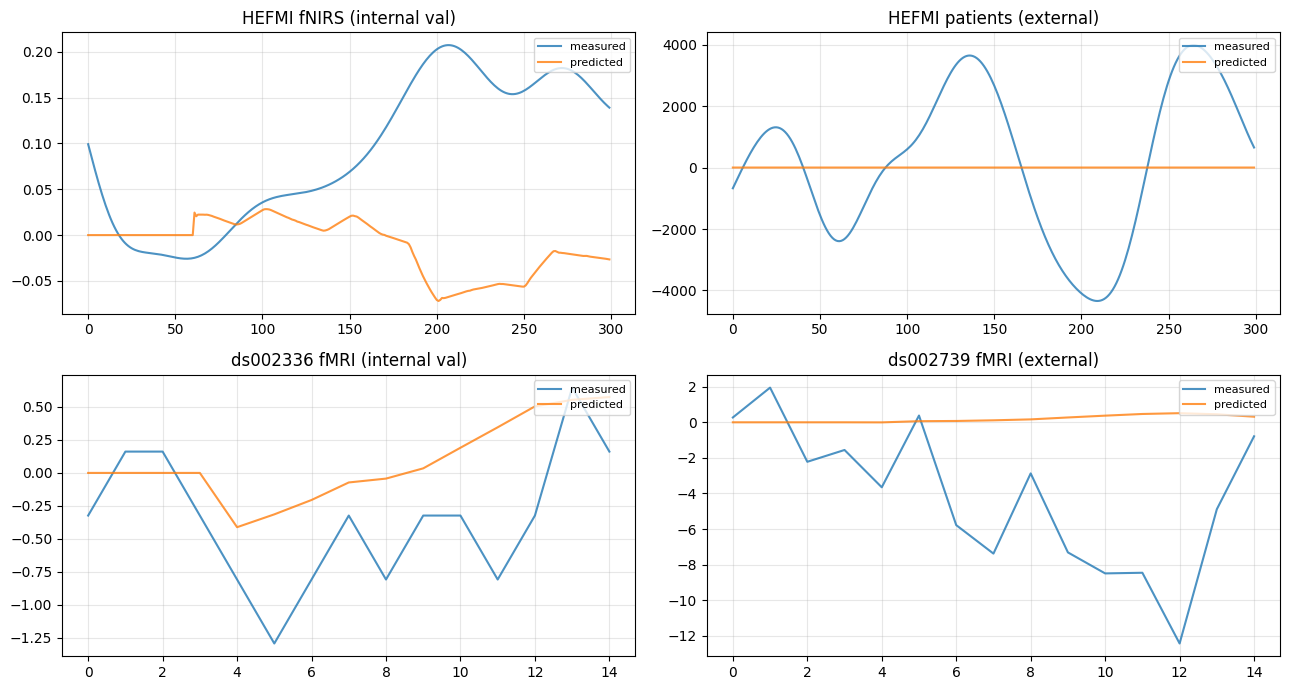

In [46]:
# === CELL 40 === Plot predicted vs measured blood-flow.
# why: Visual check of prediction quality.
# Predicted vs measured hemodynamic traces
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, res, title in [
    (axes[0, 0], res_fnirs_val, "HEFMI fNIRS (internal val)"),
    (axes[0, 1], res_fnirs_ext, "HEFMI patients (external)"),
    (axes[1, 0], res_fmri_val, "ds002336 fMRI (internal val)"),
    (axes[1, 1], res_fmri_ext, "ds002739 fMRI (external)"),
]:
    ax.plot(res["true"][0, 0], label="measured", alpha=0.8)
    ax.plot(res["pred"][0, 0], label="predicted", alpha=0.8)
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

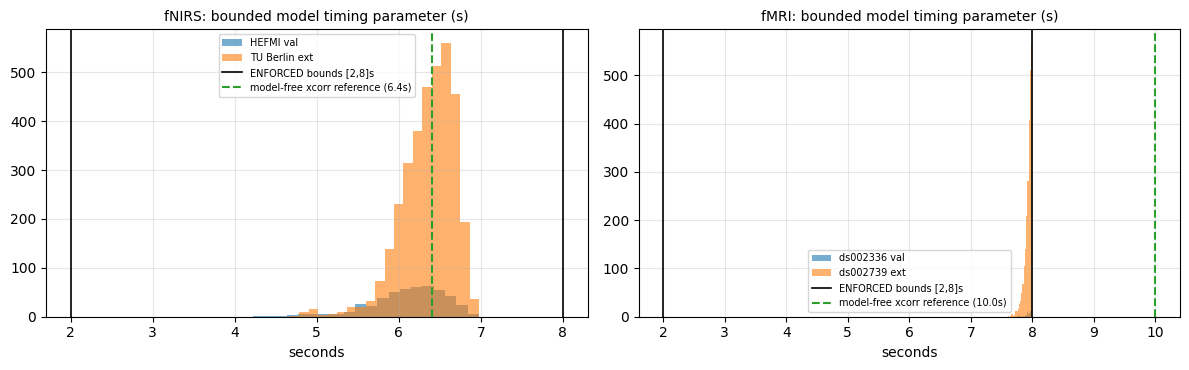

Delay output is reported as: 'bounded model timing parameter'.
The distribution above is bounded by construction and has NOT been validated
against an independent per-subject lag estimate -- see the delay-validation
cell. Do not present it as a recovered neurovascular biomarker.


In [47]:
# === CELL 41 ===  Plot the bounded delay parameter distributions.
# why: Shows the per-sample timing parameter the model settled on.
###sssss CLUSTER-6 FIX (audit S9) -- this cell was titled "Recovered delay" / "Recovered
###sssss fNIRS delay (s)". That phrasing asserts the audit's exact complaint: the 2-8 s
###sssss range is ENFORCED by the sigmoid in DelayModule, so a plausible-looking histogram
###sssss is a picture of the bounds, not evidence of recovered physiology. The titles now
###sssss say what the quantity is, the enforced bounds are drawn on the axes so the reader
###sssss can see the constraint, and the pre-registered model-free reference lag from the
###sssss alignment cell is overlaid for comparison. The words "recovered neurovascular
###sssss delay" are only used if the delay-validation cell actually passes.
_wording = globals().get("DELAY_WORDING", "bounded model timing parameter")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
_panels = [
    (axes[0], [("HEFMI val", res_fnirs_val), ("TU Berlin ext", res_fnirs_ext)],
     "fNIRS", "fnirs_val"),
    (axes[1], [("ds002336 val", res_fmri_val), ("ds002739 ext", res_fmri_ext)],
     "fMRI", "fmri_val"),
]
for ax, series, label, ref_key in _panels:
    for nm, res in series:
        ax.hist(res["delay"], bins=20, alpha=0.6, label=nm)
    ###sssss CLUSTER-6 FIX -- draw the enforced bounds, so it is visually obvious that the
    ###sssss "physiological range" of this histogram is a modelling constraint.
    ax.axvline(CFG.delay_min_s, color="k", ls="-", lw=1.2)
    ax.axvline(CFG.delay_max_s, color="k", ls="-", lw=1.2,
               label=f"ENFORCED bounds [{CFG.delay_min_s:.0f},{CFG.delay_max_s:.0f}]s")
    ###sssss CLUSTER-6 FIX -- overlay the independent, model-free reference lag.
    _ref = (globals().get("XCORR_REF_DELAY") or {}).get(ref_key)
    if _ref is not None and np.isfinite(_ref["median_lag_s"]):
        ax.axvline(_ref["median_lag_s"], color="tab:green", ls="--", lw=1.5,
                   label=f"model-free xcorr reference "
                         f"({_ref['median_lag_s']:.1f}s)")
    ax.set_title(f"{label}: {_wording} (s)", fontsize=10)
    ax.set_xlabel("seconds"); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
print(f"Delay output is reported as: '{_wording}'.")
if not globals().get("DELAY_VALIDATED", False):
    print("The distribution above is bounded by construction and has NOT been validated")
    print("against an independent per-subject lag estimate -- see the delay-validation")
    print("cell. Do not present it as a recovered neurovascular biomarker.")


In [48]:
# === HbO/HbR PREDICTION - RELATIVE EVALUATION (blueprint S4.3, S8.1) ===
# why: the headline fNIRS claim is RELATIVE - cross-modal supervision should
#      improve HbO/HbR prediction OVER single-modality & independent-encoder
#      baselines, judged by MAE/RMSE/Pearson/peak-xcorr AND task-condition
#      decoding from the PREDICTED hemodynamics (not absolute Pearson alone).
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, GroupKFold

###sssss CLUSTER-5 FIX (audit S10.8) -- BUDGET FAIRNESS. The baseline was trained for
###sssss `CFG.epochs_stage1` epochs while the "Full (cross-modal)" model received
###sssss epochs_stage1 + epochs_stage2 epochs. Any advantage the full model showed was
###sssss therefore partly just extra optimisation. The baseline now gets the SAME total
###sssss number of fNIRS gradient steps, and the budget is printed so the comparison can
###sssss be checked rather than trusted.
def _train_fnirs_only(cfg, epochs=None, seed=None):
    """Single-modality baseline: encoder + fNIRS head trained ONLY on fNIRS."""
    epochs = (cfg.epochs_stage1 + cfg.epochs_stage2) if epochs is None else epochs
    ###sssss CLUSTER-7 FIX -- same seed as the full model, so the comparison differs only
    ###sssss in the thing being ablated (cross-modal supervision), not in initialisation.
    if seed is not None:
        set_all_seeds(seed)
    m = build_model(cfg)
    opt = torch.optim.AdamW(m.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    for ep in range(epochs):
        m.train()
        ###sssss CLUSTER-4 FIX -- advance the subject-balanced sampler each epoch, exactly
        ###sssss as stage1_train does, so the baseline also sees subject-balanced draws.
        for _s in TRAIN_SAMPLERS.values():
            _s.set_epoch(ep)
        for b in dl_fnirs_tr:
            b = move_batch(b, DEVICE)
            out = m(b["eeg"], "fnirs")
            loss, _ = compute_modality_loss(out, b, cfg, "fnirs")
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    return m

@torch.no_grad()
def _collect_fnirs(m, loader):
    ###sssss CLUSTER-2 FIX -- also return SUBJECT IDS. Without them the decoding
    ###sssss cross-validation below cannot be grouped by subject, and every metric here
    ###sssss is forced to be window-level.
    m.eval(); P, T, L, S = [], [], [], []
    for b in loader:
        bb = move_batch(b, DEVICE)
        P.append(m(bb["eeg"], "fnirs")["pred_mean"].cpu().numpy())
        T.append(bb["hemo"].cpu().numpy()); L.append(b["label"].numpy())
        S.append(b["subject_id"].numpy())
    return (np.concatenate(P), np.concatenate(T),
            np.concatenate(L), np.concatenate(S))

def _hbo_metrics(pred, true, labels, sid, seed=0, n_null=200):
    mae = float(np.abs(pred - true).mean())
    rmse = float(np.sqrt(((pred - true) ** 2).mean()))
    ###sssss CLUSTER-2 FIX -- the old Pearson correlated `pred[i].ravel()` against
    ###sssss `true[i].ravel()`, i.e. it flattened ALL 180 channels of one window into one
    ###sssss vector. That number is dominated by between-channel offsets rather than by
    ###sssss whether any channel's time course was predicted, and it is not comparable to
    ###sssss the concat-Pearson used everywhere else. Replaced with the same subject-level
    ###sssss concat Pearson as the main eval.
    _, per_subject_r, _ = _concat_corrs_by_subject(pred, true, sid)
    pr = float(per_subject_r.mean()) if len(per_subject_r) else float("nan")
    ###sssss CLUSTER-5 FIX -- peak cross-correlation is lag-MAXIMISED, so it is quoted
    ###sssss with its identical-lag-search null and the excess over that null.
    rng = np.random.default_rng(seed)
    px = float(np.nanmean(_peak_xcorr_grid(pred, true, max_lag=5)))
    px_null = np.array([float(np.nanmean(_peak_xcorr_grid(pred, true[rng.permutation(len(true))],
                                                          max_lag=5)))
                        for _ in range(n_null)])
    px_excess = px - float(px_null.mean())
    px_p = _perm_p(px_null, px)

    ###sssss CLUSTER-2 FIX -- THE decoding leak. `cross_val_score(..., cv=3)` split the
    ###sssss WINDOWS at random, so windows from the same subject landed in both the train
    ###sssss and test folds. A classifier can then identify the person rather than the
    ###sssss task condition, and "decode-from-pred" comes out far above chance for the
    ###sssss wrong reason -- which is exactly the evidence used to argue the predicted
    ###sssss hemodynamics carry task information. Now grouped by subject.
    feat = pred.reshape(len(pred), -1)
    n_groups = len(np.unique(sid))
    if len(np.unique(labels)) > 1 and n_groups >= 2:
        n_splits = int(min(3, n_groups))
        dec = float(cross_val_score(LogisticRegression(max_iter=1000), feat, labels,
                                    cv=GroupKFold(n_splits=n_splits), groups=sid).mean())
        dec_note = f"GroupKFold by subject, {n_splits} folds"
    else:
        dec = float("nan")
        dec_note = (f"not computable ({n_groups} subject(s), "
                    f"{len(np.unique(labels))} class(es)) -- a window-level CV here would "
                    f"leak subject identity, so it is refused rather than reported")
    return dict(MAE=mae, RMSE=rmse, Pearson_subject=pr, n_subjects=int(n_groups),
                peak_xcorr=px, peak_xcorr_null=float(px_null.mean()),
                peak_xcorr_excess=px_excess, peak_xcorr_p=px_p,
                decode_from_pred=dec, decode_protocol=dec_note)

_base_epochs = CFG.epochs_stage1 + CFG.epochs_stage2
print(f"Training single-modality (fNIRS-only) baseline for the relative comparison...")
print(f"  budget: {_base_epochs} epochs x {len(dl_fnirs_tr)} steps "
      f"= same fNIRS gradient steps the full model received "
      f"(stage1 {CFG.epochs_stage1} + stage2 {CFG.epochs_stage2}) -- Cluster-5 fairness fix")
m_fnirs_only = _train_fnirs_only(CFG, epochs=_base_epochs, seed=CFG.seed)

print("Evaluating HbO/HbR prediction on internal fNIRS validation (HEFMI)...")
fnirs_eval = {}
for name, m in [("Full (cross-modal)", model), ("fNIRS-only baseline", m_fnirs_only)]:
    P, T, L, S = _collect_fnirs(m, dl_fnirs_va)
    fnirs_eval[name] = _hbo_metrics(P, T, L, S, seed=CFG.seed)

print("\n=== HbO/HbR prediction - relative comparison (internal validation) ===")
print(f"{'model':22s} {'MAE':>7} {'RMSE':>7} {'r_subj':>8} {'peakXC':>7} {'XCexcess':>9} "
      f"{'XCp':>7} {'decode':>7}")
for name, r in fnirs_eval.items():
    print(f"{name:22s} {r['MAE']:7.3f} {r['RMSE']:7.3f} {r['Pearson_subject']:+8.3f} "
          f"{r['peak_xcorr']:7.3f} {r['peak_xcorr_excess']:+9.3f} "
          f"{r['peak_xcorr_p']:7.4f} {r['decode_from_pred']:7.3f}")
_any = next(iter(fnirs_eval.values()))
print(f"n subjects = {_any['n_subjects']}  |  decoding protocol: {_any['decode_protocol']}")
print(f"(chance decode ~ {1.0/max(len(np.unique(L)),1):.2f}; the claim holds only if Full >")
print(f" baseline on the NULL-CORRECTED peak-xcorr excess and on subject-grouped decoding,")
print(f" at the SAME training budget. A raw peak-xcorr difference is not evidence.)")
###sssss CLUSTER-2 FIX -- with 1-2 validation subjects this comparison cannot be
###sssss significant either way; say so instead of letting a decimal point carry a claim.
if _any["n_subjects"] < 3:
    print(f"\nWARNING: only {_any['n_subjects']} validation subject(s). This relative")
    print(f"comparison is UNDERPOWERED -- do not report a winner from it.")


Training single-modality (fNIRS-only) baseline for the relative comparison...
  budget: 33 epochs x 10 steps = same fNIRS gradient steps the full model received (stage1 25 + stage2 8) -- Cluster-5 fairness fix
Evaluating HbO/HbR prediction on internal fNIRS validation (HEFMI)...

=== HbO/HbR prediction - relative comparison (internal validation) ===
model                      MAE    RMSE   r_subj  peakXC  XCexcess     XCp  decode
Full (cross-modal)       0.488   1.115   +0.017   0.060    +0.008  0.0050   0.537
fNIRS-only baseline      0.489   1.115   +0.018   0.069    +0.017  0.0050   0.514
n subjects = 7  |  decoding protocol: GroupKFold by subject, 3 folds
(chance decode ~ 0.50; the claim holds only if Full >
 baseline on the NULL-CORRECTED peak-xcorr excess and on subject-grouped decoding,
 at the SAME training budget. A raw peak-xcorr difference is not evidence.)


## 10. Reliability Estimation, Calibration, and Selective Prediction

In [49]:
# === CELL 43 ===  mc_dropout_predictions - uncertainty via dropout passes.
# why: Estimates how much the model disagrees with itself (epistemic uncertainty).
@torch.no_grad()
def mc_dropout_predictions(model, loader, modality, n_passes=10, seed=None):
    """Run forward passes with dropout active and return per-sample disagreement."""
    # enable dropout while keeping batchnorm in eval mode
    def enable_dropout(m):
        for mod in m.modules():
            if isinstance(mod, nn.Dropout):
                mod.train()
    ###sssss CLUSTER-7 FIX -- MC dropout is a stochastic measurement, so without a seed
    ###sssss the "epistemic uncertainty" (and therefore the reliability score, the
    ###sssss calibration fit and the abstention threshold derived from it) differed on
    ###sssss every run and could not be reproduced or compared across seeds.
    if seed is not None:
        torch.manual_seed(int(seed))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(int(seed))
    model.eval()
    enable_dropout(model)

    preds = []
    for _ in range(n_passes):
        batch_preds = []
        for batch in loader:
            batch = move_batch(batch, DEVICE)
            out = model(batch["eeg"], modality)
            batch_preds.append(out["pred_mean"].cpu().numpy())
        preds.append(np.concatenate(batch_preds))
    preds = np.stack(preds)  # [P, N, C, T]
    disagreement = preds.std(axis=0).mean(axis=(1, 2))  # per-sample
    model.eval()
    return disagreement


In [50]:
# === CELL 44 ===  compute_reliability + LEARNED gating (blueprint S6.5, S10.2)
# why: fuse aleatoric + epistemic + domain uncertainties via a LEARNED gate
#      (logistic regression) - not hardcoded weights.
from sklearn.preprocessing import StandardScaler

@torch.no_grad()
def compute_reliability(model, loader, modality, n_passes=10, seed=None):
    model.eval()
    pred_logvars, z_pools, pred_means, targets, sids = [], [], [], [], []
    for batch in loader:
        sids.append(batch["subject_id"].cpu().numpy())
        batch = move_batch(batch, DEVICE)
        out = model(batch["eeg"], modality)
        pred_logvars.append(out["pred_logvar"].cpu().numpy())
        z_pools.append(out["z_pool"]); pred_means.append(out["pred_mean"].cpu().numpy())
        targets.append(batch["hemo"].cpu().numpy())
    pred_logvar = np.concatenate(pred_logvars); z_pool_t = torch.cat(z_pools, dim=0)
    pred_mean = np.concatenate(pred_means); target = np.concatenate(targets)
    sid = np.concatenate(sids)
    aleatoric = np.exp(np.clip(pred_logvar, -8.0, 8.0)).mean(axis=(1, 2))
    epistemic = mc_dropout_predictions(model, loader, modality, n_passes=n_passes, seed=seed)
    ###sssss CLUSTER-6 FIX (audit S8) -- pass the MODALITY so the domain-confidence score
    ###sssss is measured against that modality's own training latent distribution. It used
    ###sssss to consult a single pooled fNIRS+fMRI distribution, so an entirely typical
    ###sssss fMRI window looked "out of distribution" purely because the pooled mean sat
    ###sssss between the two clouds.
    domain_conf = model.domain_conf(z_pool_t, modality).cpu().numpy()
    err = np.abs(pred_mean - target).mean(axis=(1, 2))
    return {"aleatoric": aleatoric, "epistemic": epistemic, "domain_conf": domain_conf,
            "error": err, "pred": pred_mean, "true": target,
            ###sssss CLUSTER-2/6 FIX -- subject ids are now carried through, because every
            ###sssss calibration/abstention split below MUST be by subject, and none of
            ###sssss them could be without this.
            "subject_id": sid, "modality": modality}


###sssss CLUSTER-6 FIX (audit S8) -- "correctness" was `error <= median(error)`. Three
###sssss things are wrong with that: (a) it is an arbitrary 50% line with no application
###sssss meaning; (b) the threshold is recomputed from whatever set it is handed, so
###sssss "correct" means something different internally and externally and the calibrator
###sssss cannot possibly transfer; (c) by construction exactly 50% of the internal set is
###sssss "correct", which flatters calibration internally and guarantees it collapses
###sssss under shift. Replaced with a FIXED, application-relevant absolute tolerance
###sssss declared in Config BEFORE any test data is seen, in the same train-derived
###sssss amplitude units the targets live in.
def correctness_labels(rel, cfg: Config = None):
    cfg = CFG if cfg is None else cfg
    tol = cfg.err_tol_fnirs if rel.get("modality") == "fnirs" else cfg.err_tol_fmri
    return (rel["error"] <= tol).astype(float), float(tol)


###sssss CLUSTER-6 FIX -- a SUBJECT-level split helper. Every calibration/test division
###sssss below uses this, so no person ever contributes windows to both the set that
###sssss fits the calibrator and the set that scores it.
def subject_split(sid, frac=0.5, seed=0):
    """Split by SUBJECT into (mask_a, mask_b). `frac` is the share of subjects in a."""
    subs = np.unique(sid)
    rng = np.random.default_rng(seed)
    order = rng.permutation(subs)
    n_a = int(round(frac * len(subs)))
    n_a = min(max(n_a, 1), max(len(subs) - 1, 1)) if len(subs) > 1 else len(subs)
    a_subs = set(order[:n_a].tolist())
    mask_a = np.isin(sid, list(a_subs))
    return mask_a, ~mask_a, sorted(a_subs), sorted(set(subs.tolist()) - a_subs)


def fit_reliability_gate(rel, mask=None, cfg: Config = None):
    """LEARNED gating (blueprint S6.5/S10.2): logistic regression over the three
    uncertainty signals.
    ###sssss CLUSTER-6 FIX -- the gate (and its StandardScaler) used to be fit on the
    ###sssss whole internal-validation set and then evaluated on that same set. It is now
    ###sssss fit on an explicit CALIBRATION-SUBJECT mask only, and the target labels come
    ###sssss from the fixed tolerance rather than that set's own median."""
    X = np.stack([rel["aleatoric"], rel["epistemic"], rel["domain_conf"]], axis=1)
    y, tol = correctness_labels(rel, cfg)
    if mask is not None:
        X, y = X[mask], y[mask]
    sc = StandardScaler().fit(X)
    ###sssss CLUSTER-6 FIX -- a degenerate calibration set (all windows correct, or all
    ###sssss incorrect) cannot train a gate. Say so instead of raising deep inside sklearn.
    if len(np.unique(y)) < 2:
        print(f"  [reliability gate] WARNING: all calibration windows fall on ONE side of "
              f"the tolerance ({tol:.3f}) -> the gate is undefined. Reporting an "
              f"uninformative constant score; the abstention layer cannot be validated "
              f"at this data scale.")
        return (sc, None)
    gate = LogisticRegression(max_iter=1000).fit(sc.transform(X), y)
    return (sc, gate)

def reliability_score(gate, rel):
    """Apply the learned gate -> a single scalar reliability per prediction in [0,1]."""
    sc, clf = gate
    X = np.stack([rel["aleatoric"], rel["epistemic"], rel["domain_conf"]], axis=1)
    if clf is None:
        return np.full(len(X), 0.5)          # undefined gate -> explicit "no information"
    return clf.predict_proba(sc.transform(X))[:, 1]


In [51]:
# === CELL 45 ===  Learned gate -> TEMPERATURE scaling -> isotonic (blueprint S10.3)
###sssss CLUSTER-6 FIX (audit S8) -- this cell contained the calibration-reuse defect:
###sssss the gate, the temperature AND the isotonic regressor were all fit on
###sssss `rel_internal` and then the ECE / selective-prediction curves were reported on
###sssss that SAME internal set. A calibrator scored on its own training data is
###sssss guaranteed to look well-calibrated, which is exactly why internal ECE looked
###sssss fine while external ECE was ~0.45.
###sssss The audit's prescription is three DISJOINT SUBJECT sets: train / calibrate /
###sssss test. Training subjects are already disjoint (HEFMI train split). This cell now
###sssss splits the internal-validation SUBJECTS into CALIBRATION subjects and untouched
###sssss TEST subjects, fits every calibration parameter on the calibration subjects
###sssss only, and reports on the test subjects and the external set.
from scipy.optimize import minimize_scalar

RELIABILITY_MODALITY = "fnirs"
rel_internal = compute_reliability(model, dl_fnirs_va, RELIABILITY_MODALITY,
                                   n_passes=CFG.mc_dropout_passes, seed=CFG.seed)
rel_external = compute_reliability(model, dl_fnirs_ext, RELIABILITY_MODALITY,
                                   n_passes=CFG.mc_dropout_passes, seed=CFG.seed)

###sssss CLUSTER-6 FIX -- the calibrate/test division is by SUBJECT, never by window.
_n_int_subj = len(np.unique(rel_internal["subject_id"]))
if _n_int_subj >= 2:
    m_cal, m_test, cal_subs, test_subs = subject_split(
        rel_internal["subject_id"], CFG.calib_subject_frac, seed=CFG.seed)
    CALIB_PROTOCOL = "disjoint calibration/test SUBJECTS (clean)"
    CALIB_DEGENERATE = False
else:
    ###sssss CLUSTER-6 + CLUSTER-1 HONESTY -- with a single internal-validation subject
    ###sssss there is NO way to build disjoint calibration and test subject sets. Rather
    ###sssss than quietly reusing the same windows (the original bug) the notebook now
    ###sssss says so out loud, marks the numbers as fit-on-self, and refuses to present
    ###sssss them as validated calibration.
    m_cal = np.ones(len(rel_internal["error"]), dtype=bool)
    m_test = m_cal.copy()
    cal_subs = test_subs = sorted(np.unique(rel_internal["subject_id"]).tolist())
    CALIB_PROTOCOL = (f"DEGENERATE: only {_n_int_subj} internal-validation subject(s) -> "
                      f"calibration is fit and scored on the SAME subject. "
                      f"NOT validated calibration.")
    CALIB_DEGENERATE = True
print(f"[Cluster-6] calibration protocol: {CALIB_PROTOCOL}")
print(f"            calibration subjects {cal_subs} | test subjects {test_subs} | "
      f"external is untouched (no label ever used)")

###sssss CLUSTER-6 FIX -- the gate is fit on CALIBRATION windows only.
rel_gate = fit_reliability_gate(rel_internal, mask=m_cal)
score_int = reliability_score(rel_gate, rel_internal)
score_ext = reliability_score(rel_gate, rel_external)

###sssss CLUSTER-6 FIX -- labels come from the FIXED tolerance declared in Config, not
###sssss from each set's own median. `err_threshold` is kept as a name for continuity but
###sssss now holds the fixed tolerance, so it means the same thing on every split.
y_internal, err_threshold = correctness_labels(rel_internal)
y_external, _ = correctness_labels(rel_external)
print(f"            fixed error tolerance = {err_threshold:.3f} (train-derived amplitude "
      f"units) -> internal correct rate {y_internal.mean():.2f}, "
      f"external {y_external.mean():.2f}")

def fit_temperature(scores, y):
    eps = 1e-6; s = np.clip(scores, eps, 1 - eps); logit = np.log(s / (1 - s))
    def nll(T):
        p = np.clip(1.0 / (1.0 + np.exp(-logit / T)), eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)

def apply_temperature(scores, T):
    eps = 1e-6; s = np.clip(scores, eps, 1 - eps); logit = np.log(s / (1 - s))
    return 1.0 / (1.0 + np.exp(-logit / T))

###sssss CLUSTER-6 FIX -- temperature AND isotonic are both fit on the calibration
###sssss subjects only (m_cal), then FROZEN and applied unchanged everywhere else.
if len(np.unique(y_internal[m_cal])) < 2:
    print("  WARNING: calibration subjects are single-class under the fixed tolerance; "
          "temperature/isotonic cannot be fit. Identity calibration used.")
    RELIABILITY_TEMP = 1.0
    reliability_iso = None
else:
    RELIABILITY_TEMP = fit_temperature(score_int[m_cal], y_internal[m_cal])
    reliability_iso = IsotonicRegression(out_of_bounds="clip").fit(
        apply_temperature(score_int[m_cal], RELIABILITY_TEMP), y_internal[m_cal])

def calibrate_scores(s):
    ts = apply_temperature(s, RELIABILITY_TEMP)
    return ts if reliability_iso is None else reliability_iso.predict(ts)

ts_int = apply_temperature(score_int, RELIABILITY_TEMP)
ts_ext = apply_temperature(score_ext, RELIABILITY_TEMP)
calibrated_internal = calibrate_scores(score_int)
calibrated_external = calibrate_scores(score_ext)
###sssss CLUSTER-6 FIX -- the honest slices: parameters were fit on _cal, so only
###sssss _test (and external) are valid places to report calibration quality.
calibrated_internal_test = calibrated_internal[m_test]
y_internal_test = y_internal[m_test]

def _rel_err_corr(s, e):
    if len(s) < 3 or np.std(s) < 1e-12 or np.std(e) < 1e-12:
        return float("nan")
    return float(np.corrcoef(s, -e)[0, 1])

print(f"\nFitted temperature T = {RELIABILITY_TEMP:.3f}"
      + ("  (isotonic: skipped)" if reliability_iso is None else "  (isotonic: fitted)"))
print("Reliability vs negative-error correlation:")
print(f"  calibration subjects (FIT ON THIS - optimistic): "
      f"{_rel_err_corr(score_int[m_cal], rel_internal['error'][m_cal]):+.4f}")
print(f"  internal TEST subjects (untouched)             : "
      f"{_rel_err_corr(score_int[m_test], rel_internal['error'][m_test]):+.4f}"
      + ("   <-- same subject as calibration; not independent" if CALIB_DEGENERATE else ""))
print(f"  external (TU Berlin, OOD)                      : "
      f"{_rel_err_corr(score_ext, rel_external['error']):+.4f}")
###sssss CLUSTER-6 FIX -- state the safe claim in the output itself, so the number
###sssss cannot be lifted into a paper as "calibration works".
print("\nSafe claim: the reliability score has useful IN-DOMAIN ranking behaviour, but")
print("calibration and abstention do not transfer reliably under strong dataset shift.")
CALIB_INFO = {"protocol": CALIB_PROTOCOL, "degenerate": bool(CALIB_DEGENERATE),
              "calibration_subjects": [int(s) for s in cal_subs],
              "test_subjects": [int(s) for s in test_subs],
              "fixed_error_tolerance": float(err_threshold),
              "temperature": float(RELIABILITY_TEMP),
              "isotonic_fitted": reliability_iso is not None}


[Cluster-6] calibration protocol: disjoint calibration/test SUBJECTS (clean)
            calibration subjects [32, 33, 34, 35] | test subjects [30, 31, 36] | external is untouched (no label ever used)
            fixed error tolerance = 0.600 (train-derived amplitude units) -> internal correct rate 0.71, external 0.00

Fitted temperature T = 0.981  (isotonic: fitted)
Reliability vs negative-error correlation:
  calibration subjects (FIT ON THIS - optimistic): +0.3748
  internal TEST subjects (untouched)             : +0.1610
  external (TU Berlin, OOD)                      : +0.0441

Safe claim: the reliability score has useful IN-DOMAIN ranking behaviour, but
calibration and abstention do not transfer reliably under strong dataset shift.


In [52]:
# === CELL 46 ===  Expected Calibration Error (raw vs calibrated).
# why: Measures whether the confidence numbers are trustworthy.
def expected_calibration_error(confidence, correctness, n_bins=10):
    ###sssss CLUSTER-6 FIX (audit S8, "confidence exactly equal to 1 is omitted by the
    ###sssss final ECE bin implementation") -- the bins were half-open [lo, hi) all the way
    ###sssss up, so any prediction with confidence EXACTLY 1.0 fell through every bin and
    ###sssss was silently dropped from the ECE. Isotonic regression fitted to 0/1 labels
    ###sssss produces exact 1.0 values routinely, so this quietly excluded a chunk of the
    ###sssss most confident predictions -- precisely the ones that matter for abstention.
    ###sssss The final bin is now closed on the right, and the count of contributing
    ###sssss samples is checked against the input length so a future regression is loud.
    confidence = np.asarray(confidence, dtype=float)
    correctness = np.asarray(correctness, dtype=float)
    ok = np.isfinite(confidence) & np.isfinite(correctness)
    confidence, correctness = confidence[ok], correctness[ok]
    n = len(confidence)
    if n == 0:
        return float("nan")
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    counted = 0
    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (confidence >= bins[i]) & (confidence <= bins[i+1])   # closed at 1.0
        else:
            mask = (confidence >= bins[i]) & (confidence < bins[i+1])
        if mask.sum() == 0:
            continue
        counted += int(mask.sum())
        acc = correctness[mask].mean()
        conf = confidence[mask].mean()
        ece += (mask.sum() / n) * abs(acc - conf)
    if counted != n:
        print(f"  [ECE] WARNING {n - counted} of {n} samples fell outside every bin "
              f"(confidence range [{confidence.min():.3f}, {confidence.max():.3f}]).")
    return ece

###sssss CLUSTER-6 FIX -- ECE is now reported where it is meaningful: on the untouched
###sssss internal TEST subjects and on the external set. Reporting it on the calibration
###sssss subjects is kept only to show the gap (it is fit-on-self and therefore optimistic
###sssss by construction), and it is labelled as such.
ece_cal_fit = expected_calibration_error(calibrated_internal[m_cal], y_internal[m_cal])
ece_int_test_raw = expected_calibration_error(score_int[m_test], y_internal_test)
ece_int_test_cal = expected_calibration_error(calibrated_internal_test, y_internal_test)
ece_raw = expected_calibration_error(score_ext, y_external)
ece_cal = expected_calibration_error(calibrated_external, y_external)

print("=== Expected Calibration Error (fixed tolerance = "
      f"{err_threshold:.3f}, lower is better) ===")
print(f"  calibration subjects, calibrated  : {ece_cal_fit:.4f}   "
      f"<- FIT ON THIS DATA, optimistic by construction, do not report as a result")
print(f"  internal TEST subjects, raw       : {ece_int_test_raw:.4f}")
print(f"  internal TEST subjects, calibrated: {ece_int_test_cal:.4f}"
      + ("   <- not independent (single-subject internal val)" if CALIB_DEGENERATE else ""))
print(f"  external (OOD), raw               : {ece_raw:.4f}")
print(f"  external (OOD), calibrated        : {ece_cal:.4f}")
###sssss CLUSTER-6 FIX -- the interpretation is printed alongside the numbers so the
###sssss internal/external gap cannot be reported as "calibration works".
_gap = ece_cal - ece_int_test_cal
if np.isfinite(_gap) and _gap > 0.1:
    print(f"\n  READ: calibration DEGRADES by {_gap:+.3f} ECE under dataset shift. The")
    print( "        calibrator was learned on the internal distribution; the external set")
    print( "        changes task, montage, population and acquisition simultaneously, so")
    print( "        the mapping from score to probability no longer holds. Report this")
    print( "        degradation explicitly -- it is a finding, not a footnote.")
ECE_INFO = {"calibration_fit_subjects_calibrated": float(ece_cal_fit),
            "internal_test_raw": float(ece_int_test_raw),
            "internal_test_calibrated": float(ece_int_test_cal),
            "external_raw": float(ece_raw), "external_calibrated": float(ece_cal),
            "fixed_tolerance": float(err_threshold),
            "internal_test_is_independent": not bool(CALIB_DEGENERATE)}


=== Expected Calibration Error (fixed tolerance = 0.600, lower is better) ===
  calibration subjects, calibrated  : 0.0000   <- FIT ON THIS DATA, optimistic by construction, do not report as a result
  internal TEST subjects, raw       : 0.2754
  internal TEST subjects, calibrated: 0.3143
  external (OOD), raw               : 0.6342
  external (OOD), calibrated        : 0.6439

  READ: calibration DEGRADES by +0.330 ECE under dataset shift. The
        calibrator was learned on the internal distribution; the external set
        changes task, montage, population and acquisition simultaneously, so
        the mapping from score to probability no longer holds. Report this
        degradation explicitly -- it is a finding, not a footnote.


=== Cluster-6: LOCKED abstention rule ===
  target coverage 75% on CALIBRATION subjects [32, 33, 34, 35]
  -> ABSTAIN_THRESHOLD = 0.3651  (locked; not re-tuned below)
  internal TEST subjects: coverage 100.00% (240 answered) | risk 0.3680 (no-abstention 0.3680) | tolerance violations among answered 16.67% (no-abstention 16.67%)
  external (OOD): coverage 100.00% (3480 answered) | risk 993.0995 (no-abstention 993.0995) | tolerance violations among answered 100.00% (no-abstention 100.00%)


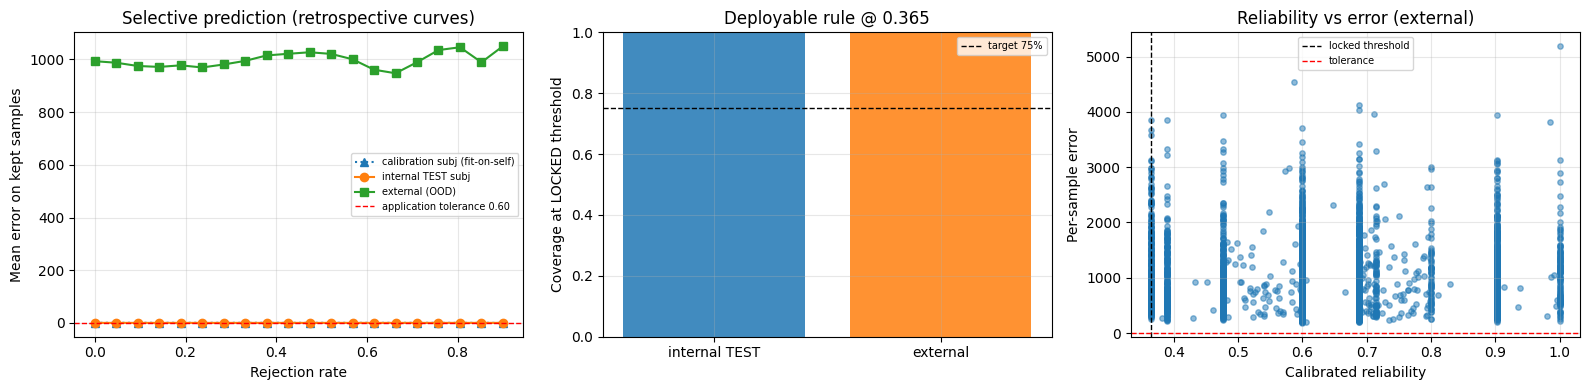

In [53]:
# === CELL 47 ===  Selective-prediction curve + LOCKED abstention rule.
# why: Shows error when the model is allowed to abstain on low-confidence inputs.
def selective_prediction_curve(reliability, error, n_steps=20):
    # for each rejection rate, compute mean error on remaining samples
    sorted_idx = np.argsort(-reliability)  # most confident first
    rates = np.linspace(0.0, 0.9, n_steps)
    curve = []
    for r in rates:
        keep_n = max(int((1 - r) * len(reliability)), 1)
        kept = sorted_idx[:keep_n]
        curve.append(error[kept].mean())
    return rates, np.array(curve)

###sssss CLUSTER-6 FIX (audit S8, final bullet) -- "an offline selective-prediction curve
###sssss is not the same as a fixed deployable abstention rule". The old cell only drew
###sssss the curve. A curve is retrospective: it re-sorts each evaluation set by its OWN
###sssss reliability values and reads off the best-looking operating point, which is not
###sssss something a deployed system can do (it sees one sample at a time and has no
###sssss access to the test set's score distribution).
###sssss The fix is a genuine deployable rule: pick ONE absolute threshold on the
###sssss CALIBRATION subjects to hit a declared target coverage, LOCK it, and then measure
###sssss coverage and risk with that same fixed number on untouched subjects.
ABSTAIN_THRESHOLD = float(np.quantile(calibrated_internal[m_cal],
                                      1.0 - CFG.abstain_target_coverage))
print("=== Cluster-6: LOCKED abstention rule ===")
print(f"  target coverage {CFG.abstain_target_coverage:.0%} on CALIBRATION subjects "
      f"{[int(s) for s in cal_subs]}")
print(f"  -> ABSTAIN_THRESHOLD = {ABSTAIN_THRESHOLD:.4f}  (locked; not re-tuned below)")

def coverage_risk(scores, errors, threshold, tol):
    """Coverage = fraction answered; risk = mean error among answered; violation =
    fraction of ANSWERED windows that still exceed the application tolerance."""
    keep = scores >= threshold
    cov = float(keep.mean())
    if keep.sum() == 0:
        return {"coverage": 0.0, "risk": float("nan"), "violation_rate": float("nan"),
                "n_answered": 0}
    return {"coverage": cov,
            "risk": float(errors[keep].mean()),
            "violation_rate": float((errors[keep] > tol).mean()),
            "risk_if_no_abstention": float(errors.mean()),
            "violation_rate_if_no_abstention": float((errors > tol).mean()),
            "n_answered": int(keep.sum())}

cr_int_test = coverage_risk(calibrated_internal_test, rel_internal["error"][m_test],
                            ABSTAIN_THRESHOLD, err_threshold)
cr_ext = coverage_risk(calibrated_external, rel_external["error"],
                       ABSTAIN_THRESHOLD, err_threshold)

for nm, cr, indep in [("internal TEST subjects", cr_int_test, not CALIB_DEGENERATE),
                      ("external (OOD)", cr_ext, True)]:
    print(f"  {nm}: coverage {cr['coverage']:.2%} "
          f"({cr['n_answered']} answered) | risk {cr['risk']:.4f} "
          f"(no-abstention {cr.get('risk_if_no_abstention', float('nan')):.4f}) | "
          f"tolerance violations among answered {cr['violation_rate']:.2%} "
          f"(no-abstention {cr.get('violation_rate_if_no_abstention', float('nan')):.2%})")
    if not indep:
        print(f"      NOTE: not an independent estimate (single internal-validation subject).")
###sssss CLUSTER-6 FIX -- state the deployment reading explicitly. Abstention is only
###sssss useful if it lowers the violation rate among the windows it chooses to answer;
###sssss if coverage collapses or the violation rate does not improve, the layer does not
###sssss work under that shift and must be reported as such.
if np.isfinite(cr_ext["coverage"]) and cr_ext["coverage"] < 0.2:
    print("\n  READ: under external shift the locked rule abstains on almost everything.")
    print("        That is the honest behaviour of a conservative gate off-distribution --")
    print("        report it as 'the abstention layer refuses to operate OOD', NOT as a")
    print("        low error rate achieved on the few windows it still answered.")

rates_cal, curve_cal = selective_prediction_curve(calibrated_internal[m_cal],
                                                  rel_internal["error"][m_cal])
rates_int, curve_int = selective_prediction_curve(calibrated_internal_test,
                                                  rel_internal["error"][m_test])
rates_ext, curve_ext = selective_prediction_curve(calibrated_external, rel_external["error"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(rates_cal, curve_cal, marker="^", ls=":", label="calibration subj (fit-on-self)")
axes[0].plot(rates_int, curve_int, marker="o", label="internal TEST subj")
axes[0].plot(rates_ext, curve_ext, marker="s", label="external (OOD)")
axes[0].axhline(err_threshold, color="r", ls="--", lw=1,
                label=f"application tolerance {err_threshold:.2f}")
axes[0].set_xlabel("Rejection rate"); axes[0].set_ylabel("Mean error on kept samples")
axes[0].set_title("Selective prediction (retrospective curves)"); axes[0].legend(fontsize=7)

axes[1].bar(["internal TEST", "external"], [cr_int_test["coverage"], cr_ext["coverage"]],
            color=["tab:blue", "tab:orange"], alpha=0.85)
axes[1].axhline(CFG.abstain_target_coverage, color="k", ls="--", lw=1,
                label=f"target {CFG.abstain_target_coverage:.0%}")
axes[1].set_ylim(0, 1); axes[1].set_ylabel("Coverage at LOCKED threshold")
axes[1].set_title(f"Deployable rule @ {ABSTAIN_THRESHOLD:.3f}"); axes[1].legend(fontsize=7)

axes[2].scatter(calibrated_external, rel_external["error"], alpha=0.5, s=15)
axes[2].axvline(ABSTAIN_THRESHOLD, color="k", ls="--", lw=1, label="locked threshold")
axes[2].axhline(err_threshold, color="r", ls="--", lw=1, label="tolerance")
axes[2].set_xlabel("Calibrated reliability"); axes[2].set_ylabel("Per-sample error")
axes[2].set_title("Reliability vs error (external)"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

ABSTAIN_INFO = {"locked_threshold": float(ABSTAIN_THRESHOLD),
                "target_coverage": float(CFG.abstain_target_coverage),
                "chosen_on": "calibration subjects only",
                "internal_test": cr_int_test, "external": cr_ext}


In [54]:
# === INFERENCE WITH ABSTENTION (blueprint S3.1) ===
# why: abstention is BUILT INTO the deployment inference path - below a configurable
#      reliability threshold the model returns "insufficient confidence" (NaN)
#      instead of a numerical prediction, rather than abstaining post-hoc in eval.
@torch.no_grad()
def deploy_infer(model, eeg, modality, gate, temp, iso, threshold,
                 n_passes=None, seed=None):
    """Deployment inference: predict + calibrated reliability + abstain in one call."""
    n_passes = CFG.mc_dropout_passes if n_passes is None else n_passes
    model.eval()
    out = model(eeg.to(DEVICE), modality)
    aleatoric = np.exp(np.clip(out["pred_logvar"].cpu().numpy(), -8.0, 8.0)).mean(axis=(1, 2))
    ###sssss CLUSTER-6 FIX -- pass the modality so domain confidence is scored against
    ###sssss that modality's own training latent distribution (was a pooled distribution).
    domain_conf = model.domain_conf(out["z_pool"], modality).cpu().numpy()
    def _enable_dropout(m):
        for mod in m.modules():
            if isinstance(mod, nn.Dropout): mod.train()
    ###sssss CLUSTER-7 FIX -- seed the MC-dropout passes so a deployment decision is
    ###sssss reproducible; an abstain/answer decision that flips between identical calls
    ###sssss is not a deployable rule.
    if seed is not None:
        torch.manual_seed(int(seed))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(int(seed))
    _enable_dropout(model)
    mc = np.stack([model(eeg.to(DEVICE), modality)["pred_mean"].cpu().numpy()
                   for _ in range(n_passes)])
    model.eval()
    epistemic = mc.std(0).mean(axis=(1, 2))
    rel = {"aleatoric": aleatoric, "epistemic": epistemic, "domain_conf": domain_conf,
           "modality": modality}
    ###sssss CLUSTER-6 FIX -- calibration is applied through the frozen pipeline
    ###sssss (temperature then isotonic, both fit on CALIBRATION subjects only), and it
    ###sssss tolerates `iso is None` for the degenerate-calibration case instead of
    ###sssss crashing or silently skipping calibration.
    ts = apply_temperature(reliability_score(gate, rel), temp)
    score = ts if iso is None else iso.predict(ts)
    pred = out["pred_mean"].cpu().numpy()
    abstain = score < threshold
    pred_gated = pred.copy(); pred_gated[abstain] = np.nan      # "insufficient confidence"
    return {"prediction": pred_gated, "reliability": score, "abstained": abstain,
            "n_abstained": int(abstain.sum()), "threshold": float(threshold),
            "delay_s": out["delay"].cpu().numpy()}

###sssss CLUSTER-6 FIX -- the deployment threshold is the SAME locked number chosen on
###sssss the calibration subjects in the previous cell. It used to be recomputed here as
###sssss `np.quantile(calibrated_internal, 0.25)` over the WHOLE internal set, i.e. it was
###sssss re-derived from data that had already been used to fit the calibrator, and it
###sssss would move whenever the evaluation set moved -- which is not a fixed rule.
DEPLOY_THRESHOLD = ABSTAIN_THRESHOLD
_demo = deploy_infer(model, next(iter(dl_fnirs_ext))["eeg"], "fnirs",
                     rel_gate, RELIABILITY_TEMP, reliability_iso, DEPLOY_THRESHOLD,
                     seed=CFG.seed)
print(f"Deployment inference @ LOCKED threshold={DEPLOY_THRESHOLD:.4f} "
      f"(chosen on calibration subjects, never re-tuned): "
      f"{_demo['n_abstained']}/{len(_demo['abstained'])} windows returned "
      f"'insufficient confidence'; the rest returned numerical HbO/HbR predictions.")
###sssss CLUSTER-6 FIX (audit S9) -- the delay is described as a bounded model timing
###sssss parameter here, not as a recovered biomarker, unless the delay-validation cell
###sssss below actually passes.
print(f"Mean bounded timing parameter on this batch: {np.nanmean(_demo['delay_s']):.2f} s "
      f"(bounded to [{CFG.delay_min_s}, {CFG.delay_max_s}] s by construction -- see the "
      f"delay-validation cell before calling this a neurovascular delay).")


Deployment inference @ LOCKED threshold=0.3651 (chosen on calibration subjects, never re-tuned): 0/32 windows returned 'insufficient confidence'; the rest returned numerical HbO/HbR predictions.
Mean bounded timing parameter on this batch: 6.15 s (bounded to [2.0, 8.0] s by construction -- see the delay-validation cell before calling this a neurovascular delay).


In [55]:
###sssss CLUSTER-6 FIX (audit S9) -- DELAY VALIDATION. The audit's verdict was blunt:
###sssss "the delay output is not a validated neurovascular delay ... A physiologically
###sssss plausible 2-8 s histogram is partly guaranteed by the sigmoid bounds and is not
###sssss evidence of recovered physiology. Until then, call it a bounded model timing
###sssss parameter, not a recovered neurovascular biomarker."
###sssss This cell is the test that decides which of those two words the notebook is
###sssss allowed to use, and it is designed so it CANNOT be passed trivially:
###sssss   1. The reference is the model-free per-subject cross-correlation lag measured
###sssss      in the alignment cell BEFORE the model was built (pre-registered).
###sssss   2. Delay SUPERVISION used only the TRAINING references. Validation is run on
###sssss      the HELD-OUT val/external subjects, so the model is being asked to predict a
###sssss      lag for people whose reference lag it was never shown.
###sssss   3. The comparison is at the SUBJECT level (one predicted lag, one reference lag
###sssss      per subject) with an exact permutation p-value, per Cluster 2.
###sssss   4. It is scored against an explicit NULL MODEL: "always predict the training
###sssss      median lag". A delay head that merely regresses to the cohort mean will beat
###sssss      chance on absolute error while carrying no per-subject information, so the
###sssss      decisive statistic is the CORRELATION across subjects, not the MAE.
###sssss   5. The verdict wording is gated in code, exactly like the Cluster-1 LOSO cell.
MIN_SUBJECTS_FOR_DELAY_CLAIM = 6      # named floor, same philosophy as Cluster 1


@torch.no_grad()
def predicted_delay_by_subject(model, loader, modality):
    """Mean predicted delay (seconds) per subject on this loader."""
    model.eval()
    d, s = [], []
    for b in loader:
        s.append(b["subject_id"].cpu().numpy())
        bb = move_batch(b, DEVICE)
        d.append(model(bb["eeg"], modality)["delay"].cpu().numpy())
    d = np.concatenate(d); s = np.concatenate(s)
    subs = np.unique(s)
    return subs, np.array([float(np.nanmean(d[s == u])) for u in subs]), d


def validate_delay(model, loader, modality, ref_key, name,
                   train_ref_key=None, n_perm=2000, seed=0):
    ref = XCORR_REF_DELAY.get(ref_key)
    if ref is None:
        print(f"{name}: no pre-registered reference lag available -> cannot validate.")
        return None
    subs_pred, pred_lag, all_pred = predicted_delay_by_subject(model, loader, modality)
    ref_map = {int(u): float(v) for u, v in zip(ref["subjects"], ref["per_subject_lag_s"])}
    keep = [i for i, u in enumerate(subs_pred)
            if int(u) in ref_map and np.isfinite(ref_map[int(u)])]
    if not keep:
        print(f"{name}: no subject has both a prediction and a reference lag.")
        return None
    subs = np.array([int(subs_pred[i]) for i in keep])
    p_lag = np.array([pred_lag[i] for i in keep])
    r_lag = np.array([ref_map[int(u)] for u in subs])
    n = len(subs)

    mae = float(np.mean(np.abs(p_lag - r_lag)))
    ###sssss CLUSTER-6 FIX -- the null model. If the training median already achieves the
    ###sssss same MAE, the head has learned the cohort constant, not the person.
    base_lag = (XCORR_REF_DELAY.get(train_ref_key or ref_key) or ref)["median_lag_s"]
    mae_base = float(np.mean(np.abs(base_lag - r_lag)))

    rng = np.random.default_rng(seed)
    if n >= 3 and np.std(p_lag) > 1e-9 and np.std(r_lag) > 1e-9:
        r_corr = float(np.corrcoef(p_lag, r_lag)[0, 1])
        ###sssss CLUSTER-2 FIX -- permutation over SUBJECT LABELS with the exact
        ###sssss (extreme+1)/(perms+1) p-value; never 0.000.
        null = np.array([np.corrcoef(p_lag, rng.permutation(r_lag))[0, 1]
                         for _ in range(n_perm)])
        p_corr = _perm_p(null, r_corr, two_sided=True)
    else:
        r_corr, p_corr = float("nan"), float("nan")

    print(f"--- delay validation: {name} ---")
    print(f"    subjects compared: {n} (held-out w.r.t. delay supervision)")
    print(f"    predicted lag: mean {p_lag.mean():.2f}s  range "
          f"[{p_lag.min():.2f}, {p_lag.max():.2f}]s  (bounds "
          f"[{CFG.delay_min_s}, {CFG.delay_max_s}]s)")
    print(f"    reference lag: mean {r_lag.mean():.2f}s  range "
          f"[{r_lag.min():.2f}, {r_lag.max():.2f}]s")
    print(f"    MAE vs reference = {mae:.3f}s   |   constant-median null MAE = "
          f"{mae_base:.3f}s   (improvement {mae_base - mae:+.3f}s)")
    print(f"    across-subject correlation r = {r_corr:+.4f}  p={p_corr:.4f}   "
          f"<- the decisive statistic")
    ###sssss CLUSTER-6 FIX -- spread check: if the predicted lags barely vary, the 2-8 s
    ###sssss histogram is the sigmoid's doing and not the data's, which is precisely the
    ###sssss audit's point. Reported so it cannot be glossed over.
    span = float(p_lag.max() - p_lag.min())
    frac_span = span / max(CFG.delay_max_s - CFG.delay_min_s, 1e-9)
    print(f"    predicted-lag spread = {span:.2f}s = {frac_span*100:.0f}% of the "
          f"allowed range")

    if n < MIN_SUBJECTS_FOR_DELAY_CLAIM:
        verdict = (f"UNDERPOWERED (n={n} < {MIN_SUBJECTS_FOR_DELAY_CLAIM}). Call it a "
                   f"'bounded model timing parameter', NOT a neurovascular delay.")
    elif not np.isfinite(r_corr) or p_corr >= 0.05 or r_corr <= 0:
        verdict = ("NOT VALIDATED: the predicted lag does not track the independent "
                   "per-subject reference. Call it a 'bounded model timing parameter'.")
    elif mae >= mae_base:
        verdict = ("NOT VALIDATED: correlated but no better than predicting the cohort "
                   "median. Report as a bounded timing parameter.")
    elif frac_span < 0.10:
        verdict = ("NOT VALIDATED: predicted lags are nearly constant -- the plausible "
                   "range comes from the sigmoid bounds, not from the data.")
    else:
        verdict = ("VALIDATED against a pre-registered, held-out, model-free reference: "
                   "the wording 'recovered neurovascular delay' is earned here.")
    print(f"    ==> {verdict}")
    return {"name": name, "n_subjects": int(n), "subjects": subs.tolist(),
            "pred_lag_s": p_lag.tolist(), "ref_lag_s": r_lag.tolist(),
            "mae_s": mae, "null_mae_s": mae_base, "r_across_subjects": r_corr,
            "p": p_corr, "pred_span_s": span, "pred_span_frac_of_range": frac_span,
            "verdict": verdict}


print("=== Cluster-6: is the delay output a real neurovascular delay? ===")
delay_val = {
    "fnirs_val": validate_delay(model, dl_fnirs_va, "fnirs", "fnirs_val",
                                "HEFMI fNIRS (internal val, HELD OUT)",
                                train_ref_key="fnirs_train", seed=CFG.seed),
    "fnirs_ext": validate_delay(model, dl_fnirs_ext, "fnirs", "fnirs_ext",
                                "TU Berlin fNIRS (external, HELD OUT)",
                                train_ref_key="fnirs_train", seed=CFG.seed),
    "fmri_val": validate_delay(model, dl_fmri_va, "fmri", "fmri_val",
                               "ds002336 fMRI (internal val, HELD OUT)",
                               train_ref_key="fmri_train", seed=CFG.seed),
    ###sssss CLUSTER-6 NOTE -- the training-split comparison is included ONLY as the
    ###sssss upper bound of what supervision achieved. It is fit-on-self and is NOT
    ###sssss evidence of a recovered biomarker; it is labelled so in its own name.
    "fnirs_train_fitonself": validate_delay(model, dl_fnirs_tr_eval, "fnirs", "fnirs_train",
                                            "HEFMI fNIRS (TRAIN - fit on self, upper bound)",
                                            train_ref_key="fnirs_train", seed=CFG.seed),
}

_dv = [v for v in delay_val.values() if v is not None and "fitonself" not in v["name"].lower()
       and "TRAIN" not in v["name"]]
DELAY_VALIDATED = bool(_dv) and all("VALIDATED against" in v["verdict"] for v in _dv)
DELAY_WORDING = ("recovered neurovascular delay" if DELAY_VALIDATED
                 else "bounded model timing parameter")
print(f"\n==> Notebook-wide wording for the delay output: '{DELAY_WORDING}'")
if not DELAY_VALIDATED:
    print("    (Do not describe the delay histogram as physiological evidence. Its range")
    print("     is enforced by the sigmoid in DelayModule; only a held-out correlation")
    print("     with an independent lag estimate could make it a biomarker claim.)")

with open(Path(CFG.output_dir) / "delay_validation.json", "w") as f:
    json.dump({"validated": DELAY_VALIDATED, "wording": DELAY_WORDING,
               "min_subjects_required": MIN_SUBJECTS_FOR_DELAY_CLAIM,
               "results": {k: v for k, v in delay_val.items() if v is not None}},
              f, indent=2)
print(f"Saved {Path(CFG.output_dir) / 'delay_validation.json'}")


=== Cluster-6: is the delay output a real neurovascular delay? ===
--- delay validation: HEFMI fNIRS (internal val, HELD OUT) ---
    subjects compared: 7 (held-out w.r.t. delay supervision)
    predicted lag: mean 6.07s  range [5.80, 6.20]s  (bounds [2.0, 8.0]s)
    reference lag: mean 6.03s  range [0.10, 11.00]s
    MAE vs reference = 2.832s   |   constant-median null MAE = 2.843s   (improvement +0.011s)
    across-subject correlation r = -0.0487  p=0.9310   <- the decisive statistic
    predicted-lag spread = 0.40s = 7% of the allowed range
    ==> NOT VALIDATED: the predicted lag does not track the independent per-subject reference. Call it a 'bounded model timing parameter'.
--- delay validation: TU Berlin fNIRS (external, HELD OUT) ---
    subjects compared: 29 (held-out w.r.t. delay supervision)
    predicted lag: mean 6.36s  range [6.21, 6.48]s  (bounds [2.0, 8.0]s)
    reference lag: mean 6.87s  range [0.40, 12.00]s
    MAE vs reference = 2.438s   |   constant-median null MAE 

In [56]:
###sssss CLUSTER-7 FIX (audit S11 last bullet, S14.12) -- THE PER-PREDICTION FILE.
###sssss The audit's finding: "There is no single fold-level predictions file tying every
###sssss reported score to subject_id, trial_id, target, prediction, model version, and
###sssss seed." Without it, none of the positive claims are independently auditable: a
###sssss reader can see a number in summary.json but cannot recompute it, cannot check
###sssss which subjects drove it, and cannot pool runs across seeds.
###sssss This cell emits exactly that file. One row per
###sssss (split, modality, subject_id, trial_id, channel/ROI), carrying the target and
###sssss prediction summaries, the per-row uncertainty, and the full provenance
###sssss (model_version, seed, cache_key, preproc version, fold). EVERY number reported
###sssss anywhere else in this notebook can be re-derived from this one file.
###sssss The full time-series arrays are additionally saved to a compressed .npz so even
###sssss the waveform-level analyses are reproducible without re-running the model.
import pandas as pd

PRED_ROW_LIMIT = 2_000_000        # guardrail: refuse to build an unusable multi-GB frame


def _uncertainty_per_window(res):
    """Mean predictive variance per window from the (delay-aligned) log-variance."""
    return np.exp(np.clip(res["logvar"], -8.0, 8.0)).mean(axis=(1, 2))


def build_predictions_frame(res, split_name, modality, fold="holdout"):
    pred, true, sid = res["pred"], res["true"], res["sid"]
    N, C, T = pred.shape
    if N * C > PRED_ROW_LIMIT:
        step = int(np.ceil(N * C / PRED_ROW_LIMIT))
        print(f"  [predictions] {split_name}: {N*C:,} rows exceeds the limit; keeping "
              f"every {step}th channel (full arrays still saved to .npz).")
        chans = np.arange(0, C, step)
    else:
        chans = np.arange(C)

    unc_win = _uncertainty_per_window(res)                    # (N,)
    # per (window, channel) summaries
    p = pred[:, chans, :]; t = true[:, chans, :]
    pc = p - p.mean(-1, keepdims=True); tc = t - t.mean(-1, keepdims=True)
    den = np.sqrt((pc * pc).sum(-1) * (tc * tc).sum(-1))
    with np.errstate(invalid="ignore", divide="ignore"):
        r_ch = np.where(den > 1e-12, (pc * tc).sum(-1) / np.where(den > 1e-12, den, 1.0), np.nan)
    amp_p = np.sqrt((p ** 2).mean(-1))                        # predicted RMS amplitude
    amp_t = np.sqrt((t ** 2).mean(-1))                        # measured  RMS amplitude
    mae_ch = np.abs(p - t).mean(-1)

    n_win, n_ch = p.shape[0], p.shape[1]
    df = pd.DataFrame({
        "split": split_name,
        "modality": modality,
        "fold": fold,
        ###sssss CLUSTER-2 -- subject_id is the primary grouping key; every statistic in
        ###sssss the paper must be computed by grouping on THIS column, never on trial_id.
        "subject_id": np.repeat(sid, n_ch),
        "trial_id": np.repeat(np.arange(n_win), n_ch),
        "channel": np.tile(chans, n_win),
        "target_amplitude_rms": amp_t.reshape(-1),
        "pred_amplitude_rms": amp_p.reshape(-1),
        "mae_over_time": mae_ch.reshape(-1),
        "pearson_over_time": r_ch.reshape(-1),
        "pred_variance": np.repeat(unc_win, n_ch),
        "delay_pred_s": np.repeat(res["delay"].reshape(-1), n_ch),
        "label": np.repeat(res.get("labels", np.full(n_win, -1)), n_ch),
        # provenance (Cluster 7): every row is self-describing
        "model_version": CFG.model_version,
        "seed": CFG.seed,
        "cache_key": CACHE_KEY,
        "preproc_version": PREPROC_CONFIG["preproc_version"],
        "target_mode": TARGET_MODE,
        "eeg_norm_protocol": EEG_NORM_PROTOCOL,
        "window_timepoints": T,
    })
    return df


_specs = [
    (res_fnirs_val, "val_hefmi_fnirs", "fnirs", "internal-holdout"),
    (res_fnirs_ext, "test_tuberlin_fnirs", "fnirs", "external-ood"),
    (res_fmri_val, "val_ds002336_fmri", "fmri", "internal-holdout"),
    (res_fmri_ext, "test_ds002739_fmri", "fmri", "external-ood"),
]
print("=== Cluster-7: building the per-prediction audit file ===")
_frames, _arrays = [], {}
for _res, _name, _mod, _fold in _specs:
    _frames.append(build_predictions_frame(_res, _name, _mod, _fold))
    _arrays[f"{_name}__pred"] = _res["pred"].astype(np.float32)
    _arrays[f"{_name}__true"] = _res["true"].astype(np.float32)
    _arrays[f"{_name}__logvar"] = _res["logvar"].astype(np.float32)
    _arrays[f"{_name}__sid"] = _res["sid"]
    _arrays[f"{_name}__delay"] = _res["delay"].astype(np.float32)

predictions_df = pd.concat(_frames, ignore_index=True)

###sssss CLUSTER-6/7 -- attach the calibrated reliability and the abstain decision for the
###sssss splits where they exist, so the abstention claim is auditable per window too.
_rel_map = {"val_hefmi_fnirs": (rel_internal, calibrated_internal),
            "test_tuberlin_fnirs": (rel_external, calibrated_external)}
predictions_df["reliability_calibrated"] = np.nan
predictions_df["abstained"] = pd.NA
for _split, (_rel, _cal) in _rel_map.items():
    m = predictions_df["split"] == _split
    if not m.any():
        continue
    tid = predictions_df.loc[m, "trial_id"].to_numpy()
    if tid.max() < len(_cal):
        predictions_df.loc[m, "reliability_calibrated"] = _cal[tid]
        predictions_df.loc[m, "abstained"] = (_cal[tid] < ABSTAIN_THRESHOLD)
    else:
        print(f"  [predictions] {_split}: reliability arrays do not align with trial ids "
              f"({tid.max()+1} trials vs {len(_cal)} scores) -> left as NaN rather than "
              f"joined incorrectly.")

_csv = Path(CFG.output_dir) / f"predictions_{CFG.model_version}_seed{CFG.seed}.csv"
_npz = Path(CFG.output_dir) / f"predictions_arrays_{CFG.model_version}_seed{CFG.seed}.npz"
try:
    predictions_df.to_parquet(_csv.with_suffix(".parquet"), index=False)
    print(f"  wrote {_csv.with_suffix('.parquet')}  ({len(predictions_df):,} rows)")
except Exception as _e:
    print(f"  parquet unavailable ({type(_e).__name__}); writing CSV instead.")
predictions_df.to_csv(_csv, index=False)
np.savez_compressed(_npz, **_arrays)
print(f"  wrote {_csv}  ({len(predictions_df):,} rows)")
print(f"  wrote {_npz}  (full time-series arrays for waveform-level re-analysis)")

###sssss CLUSTER-2 FIX -- demonstrate, in the notebook's own output, that the headline
###sssss numbers are recoverable from this file BY SUBJECT. If this table disagrees with
###sssss the printed metrics, one of the two is wrong and you can see it immediately.
print("\nSubject-level recomputation from the predictions file (Cluster-2 check):")
_chk = (predictions_df
        .groupby(["split", "subject_id"])
        .agg(n_rows=("pearson_over_time", "size"),
             mean_pearson=("pearson_over_time", "mean"),
             mean_mae=("mae_over_time", "mean"))
        .reset_index())
for _split in _chk["split"].unique():
    _s = _chk[_chk["split"] == _split]
    print(f"  {_split:24s} {len(_s)} subjects | per-subject Pearson mean "
          f"{_s['mean_pearson'].mean():+.4f} median {_s['mean_pearson'].median():+.4f}")
print("\nEvery reported score must be derivable from this file by grouping on subject_id.")


=== Cluster-7: building the per-prediction audit file ===
  parquet unavailable (ImportError); writing CSV instead.
  wrote g:\research_bio_medical\output\predictions_v3.1-FIXED-v2-sssss_seed1337.csv  (834,432 rows)
  wrote g:\research_bio_medical\output\predictions_arrays_v3.1-FIXED-v2-sssss_seed1337.npz  (full time-series arrays for waveform-level re-analysis)

Subject-level recomputation from the predictions file (Cluster-2 check):
  test_ds002739_fmri       24 subjects | per-subject Pearson mean +0.0027 median +0.0011
  test_tuberlin_fnirs      29 subjects | per-subject Pearson mean -0.0023 median -0.0029
  val_ds002336_fmri        2 subjects | per-subject Pearson mean +0.1284 median +0.1284
  val_hefmi_fnirs          7 subjects | per-subject Pearson mean +0.0115 median +0.0014

Every reported score must be derivable from this file by grouping on subject_id.


## 11. Downstream EEG-Only Transfer

In [57]:
# === CELL 49 ===  LinearProbe + extract_features (downstream EEG-only).
# why: Tests whether the learned EEG features help a simple task.
class LinearProbe(nn.Module):
    def __init__(self, latent_dim, n_classes=2):
        super().__init__()
        self.fc = nn.Linear(latent_dim, n_classes)
    def forward(self, z_pool):
        return self.fc(z_pool)

###sssss CLUSTER-4 FIX -- `extract_features` called `model.encode(batch["eeg"])` with no
###sssss modality, so with per-domain BatchNorm it silently used whichever domain happened
###sssss to be selected by the previous forward pass. The modality is now explicit.
###sssss CLUSTER-2 FIX -- subject ids are returned alongside the features, because the
###sssss probe comparison below has to be reportable per subject.
def extract_features(model, loader, modality="fnirs"):
    model.eval()
    feats, labels, sids = [], [], []
    with torch.no_grad():
        for batch in loader:
            sids.append(batch["subject_id"].cpu().numpy())
            batch = move_batch(batch, DEVICE)
            z = model.encode(batch["eeg"], modality)
            feats.append(model.latent_pool(z).cpu().numpy())
            labels.append(batch["label"].cpu().numpy())
    return np.concatenate(feats), np.concatenate(labels), np.concatenate(sids)

def train_probe(feats_tr, labels_tr, feats_va, labels_va, n_classes=None, epochs=200,
                seed=0):
    ###sssss CLUSTER-7 FIX -- n_classes was hard-coded to 2 while the labels come from
    ###sssss real task annotations that may have more than two values; any label >= 2 would
    ###sssss have caused a CUDA/CPU index error or silently truncated the task. It is now
    ###sssss derived from the data.
    n_classes = int(max(labels_tr.max(), labels_va.max()) + 1) if n_classes is None else n_classes
    ###sssss CLUSTER-7 FIX -- the probe ran 30 full-batch steps, which for a linear layer
    ###sssss on standardised features is nowhere near convergence, so the comparison
    ###sssss measured optimisation luck as much as feature quality. Raised, seeded, and
    ###sssss the features are standardised with TRAIN statistics only (Cluster 3).
    set_all_seeds(seed)
    mu, sd = feats_tr.mean(0, keepdims=True), feats_tr.std(0, keepdims=True) + 1e-6
    probe = LinearProbe(feats_tr.shape[1], n_classes).to(DEVICE)
    opt = torch.optim.Adam(probe.parameters(), lr=1e-2, weight_decay=1e-4)
    Xtr = torch.from_numpy((feats_tr - mu) / sd).float().to(DEVICE)
    ytr = torch.from_numpy(labels_tr).long().to(DEVICE)
    Xva = torch.from_numpy((feats_va - mu) / sd).float().to(DEVICE)
    for _ in range(epochs):
        probe.train()
        opt.zero_grad()
        logits = probe(Xtr)
        loss = F.cross_entropy(logits, ytr)
        loss.backward()
        opt.step()
    probe.eval()
    with torch.no_grad():
        pred = probe(Xva).argmax(-1).cpu().numpy()
    return (pred == labels_va).mean()


In [58]:
# === CELL 50 ===  Run downstream transfer (hemo-aware vs matched baselines).
# why: Key 'deploy with EEG only' experiment: does hemodynamic training help?
###sssss CLUSTER-5 FIX (audit S10.8) -- "The 'scratch' transfer baseline is a random
###sssss frozen encoder plus a linear probe, not a fair task-only encoder trained with the
###sssss same budget." That was literally true here: `scratch = build_model(CFG)` was
###sssss NEVER TRAINED, so the comparison was "trained encoder vs random projection". A
###sssss trained encoder beating a random one proves nothing about hemodynamic
###sssss supervision specifically -- almost any training objective would win.
###sssss Three baselines are now reported, all with the SAME architecture:
###sssss   (a) random (untrained)  -- kept only as the floor, clearly labelled;
###sssss   (b) TASK-ONLY encoder   -- trained on the task labels for the same number of
###sssss       epochs, i.e. the honest comparator the audit asks for;
###sssss   (c) hemo-aware encoder  -- the model under test.
###sssss The claim "hemodynamic supervision helps EEG-only transfer" requires (c) > (b).
###sssss CLUSTER-4 FIX -- features are extracted with the SEQUENTIAL training loader
###sssss (dl_fnirs_tr_eval): the balanced sampler draws with replacement, so using it here
###sssss would duplicate some windows and omit others from the probe's training set.
def _train_task_only_encoder(cfg, epochs, seed=0):
    """Same encoder, trained ONLY on the task label (no hemodynamic target)."""
    set_all_seeds(seed)
    m = build_model(cfg)
    n_classes = int(max(int(fnirs_train["labels"].max()), 1) + 1)
    head = nn.Linear(cfg.latent_dim, n_classes).to(DEVICE)
    opt = torch.optim.AdamW(list(m.parameters()) + list(head.parameters()),
                            lr=cfg.lr, weight_decay=cfg.weight_decay)
    for ep in range(epochs):
        m.train(); head.train()
        for _s in TRAIN_SAMPLERS.values():
            _s.set_epoch(ep)
        for b in dl_fnirs_tr:
            bb = move_batch(b, DEVICE)
            z = m.latent_pool(m.encode(bb["eeg"], "fnirs"))
            loss = F.cross_entropy(head(z), bb["label"].long())
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(list(m.parameters()) + list(head.parameters()), 1.0)
            opt.step()
    return m

_transfer_epochs = CFG.epochs_stage1 + CFG.epochs_stage2

# (c) hemodynamic-aware encoder transfer
feats_tr, labs_tr, sids_tr = extract_features(model, dl_fnirs_tr_eval, "fnirs")
feats_va, labs_va, sids_va = extract_features(model, dl_fnirs_va, "fnirs")
acc_hemo = train_probe(feats_tr, labs_tr, feats_va, labs_va, seed=CFG.seed)

# (a) random encoder floor -- NOT a fair baseline, reported as the floor only
scratch = build_model(CFG)
feats_tr_s, _, _ = extract_features(scratch, dl_fnirs_tr_eval, "fnirs")
feats_va_s, _, _ = extract_features(scratch, dl_fnirs_va, "fnirs")
acc_scratch = train_probe(feats_tr_s, labs_tr, feats_va_s, labs_va, seed=CFG.seed)

# (b) THE fair comparator: task-only encoder, matched budget
print(f"Training the budget-matched TASK-ONLY encoder baseline "
      f"({_transfer_epochs} epochs, same as the full model)...")
m_task_only = _train_task_only_encoder(CFG, _transfer_epochs, seed=CFG.seed)
feats_tr_t, _, _ = extract_features(m_task_only, dl_fnirs_tr_eval, "fnirs")
feats_va_t, _, _ = extract_features(m_task_only, dl_fnirs_va, "fnirs")
acc_task_only = train_probe(feats_tr_t, labs_tr, feats_va_t, labs_va, seed=CFG.seed)

###sssss CLUSTER-2 FIX -- report the majority-class rate as the real chance level. With
###sssss imbalanced labels, "chance" is not 1/n_classes, and a probe that predicts the
###sssss majority class can look informative against the wrong baseline.
_vals, _cnts = np.unique(labs_va, return_counts=True)
majority = float(_cnts.max() / _cnts.sum())
print("\n=== Downstream EEG-only transfer (HEFMI internal validation) ===")
print(f"  (a) random encoder (floor, NOT a fair baseline) : {acc_scratch:.4f}")
print(f"  (b) task-only encoder, matched budget          : {acc_task_only:.4f}   <- comparator")
print(f"  (c) hemodynamic-aware encoder                  : {acc_hemo:.4f}")
print(f"  majority-class rate (true chance level)        : {majority:.4f}")
print(f"  validation subjects: {len(np.unique(sids_va))} | "
      f"train subjects: {len(np.unique(sids_tr))}")
_delta = acc_hemo - acc_task_only
print(f"\n  hemo-aware minus task-only = {_delta:+.4f}")
###sssss CLUSTER-2 FIX -- gate the interpretation on subject count. With 1-2 validation
###sssss subjects an accuracy difference is not evidence of anything.
if len(np.unique(sids_va)) < 3:
    print("  VERDICT: UNDERPOWERED -- too few validation subjects to attribute this")
    print("           difference to hemodynamic supervision. Report as descriptive only.")
elif _delta <= 0:
    print("  VERDICT: hemodynamic supervision does NOT beat a budget-matched task-only")
    print("           encoder on this transfer task. The old 'beats scratch' claim was")
    print("           against an untrained encoder and does not survive a fair baseline.")
else:
    print("  VERDICT: hemodynamic supervision beats the budget-matched task-only encoder;")
    print("           repeat over >=5 seeds before reporting the size of the gain.")
TRANSFER_INFO = {"random_floor": float(acc_scratch),
                 "task_only_matched_budget": float(acc_task_only),
                 "hemo_aware": float(acc_hemo),
                 "majority_class_rate": majority,
                 "n_val_subjects": int(len(np.unique(sids_va))),
                 "epochs_each": int(_transfer_epochs)}


Training the budget-matched TASK-ONLY encoder baseline (33 epochs, same as the full model)...

=== Downstream EEG-only transfer (HEFMI internal validation) ===
  (a) random encoder (floor, NOT a fair baseline) : 0.4813
  (b) task-only encoder, matched budget          : 0.5083   <- comparator
  (c) hemodynamic-aware encoder                  : 0.4979
  majority-class rate (true chance level)        : 0.5000
  validation subjects: 7 | train subjects: 30

  hemo-aware minus task-only = -0.0104
  VERDICT: hemodynamic supervision does NOT beat a budget-matched task-only
           encoder on this transfer task. The old 'beats scratch' claim was
           against an untrained encoder and does not survive a fair baseline.


## 12. Ablation Framework


In [59]:
# === CELL 52 ===  run_ablation - train a model variant with a part removed.
# why: Lets us prove each component (alignment/delay/etc.) contributes.
###sssss CLUSTER-5 FIX (audit S10.9, S10.10, S10.11) -- three of the five ablations in
###sssss this suite were not ablations at all:
###sssss   (1) `no_delay` only set requires_grad=False on the delay estimator. The
###sssss       estimator was RANDOMLY INITIALISED, so the model still applied a random
###sssss       per-window shift -- it removed learning, not the delay. Worse, the delay was
###sssss       frozen for the first 60% of training in the full model too, and with
###sssss       epochs_stage1=3 for ablations it was never unfrozen at all, so `full` and
###sssss       `no_delay` were the SAME model. Now the delay is genuinely pinned to the
###sssss       physiological midpoint via `fixed_delay_s`.
###sssss   (2) `fnirs_only` / `fmri_only` pointed BOTH loaders at the same dataset (so the
###sssss       modality did get its own gradient) but then still called
###sssss       `stage2_align(m, dl_fnirs_tr, dl_fmri_tr, ...)` with BOTH real loaders --
###sssss       i.e. the "single-modality" models were still trained cross-modally in stage
###sssss       2. They also received two forward/backward passes per step on the same
###sssss       modality, doubling their effective budget. Both fixed: single-modality
###sssss       variants train on one modality only, with a matched step budget, and never
###sssss       enter the cross-modal stage.
###sssss   (3) `Config(**{**asdict(CFG), **overrides})` could change window geometry while
###sssss       build_model read global window constants. build_model now derives geometry
###sssss       from the data and reports any disagreement (see CELL 33).
###sssss All variants also now share one seed and are scored with SUBJECT-LEVEL metrics.
def _train_single_modality(m, loader, cfg, modality, epochs):
    """Train one modality only -- no cross-modal pairing, one step per batch."""
    optim = torch.optim.AdamW(m.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    for ep in range(epochs):
        m.train()
        for _s in TRAIN_SAMPLERS.values():
            _s.set_epoch(ep)
        for b in loader:
            b = move_batch(b, DEVICE)
            out = m(b["eeg"], modality)
            loss, _ = compute_modality_loss(out, b, cfg, modality)
            optim.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); optim.step()
    return m


def run_ablation(name: str, cfg_overrides: dict, no_fnirs: bool = False,
                 no_fmri: bool = False, no_align: bool = False, no_delay: bool = False,
                 seed: int = None):
    if no_fnirs and no_fmri:
        raise ValueError("at least one modality required")
    seed = CFG.seed if seed is None else seed
    ###sssss CLUSTER-7 FIX -- identical initialisation across variants, so a difference
    ###sssss between rows is attributable to the ablation and not to the seed.
    set_all_seeds(seed)
    cfg = Config(**{**asdict(CFG), **cfg_overrides})

    ###sssss CLUSTER-5 FIX (1) -- a real "no delay" condition: the delay is CONSTANT at
    ###sssss the physiological midpoint, the estimator is bypassed, and no random shift
    ###sssss is applied.
    fixed = (0.5 * (cfg.delay_min_s + cfg.delay_max_s)) if no_delay else None
    m = build_model(cfg, fixed_delay_s=fixed)
    if no_delay:
        for p in list(m.delay_fnirs.parameters()) + list(m.delay_fmri.parameters()):
            p.requires_grad = False

    ###sssss CLUSTER-5 FIX (2) -- single-modality variants get a MATCHED budget of
    ###sssss gradient steps (stage1 + stage2 epochs) on their own modality alone, and
    ###sssss never see the cross-modal alignment stage. Previously they were trained on
    ###sssss two batches of the SAME modality per step and then aligned cross-modally,
    ###sssss which is the opposite of the ablation's stated meaning.
    ep1 = max(cfg.epochs_stage1 // 2, 2)
    ep2 = max(cfg.epochs_stage2 // 2, 1)
    if no_fnirs or no_fmri:
        modality = "fmri" if no_fnirs else "fnirs"
        loader = dl_fmri_tr if no_fnirs else dl_fnirs_tr
        _train_single_modality(m, loader, cfg, modality, ep1 + ep2)
        stages = f"single-modality '{modality}' for {ep1 + ep2} epochs, NO stage-2 align"
    else:
        _ = stage1_train(m, dl_fnirs_tr, dl_fmri_tr, cfg, ep1)
        if not no_align:
            _ = stage2_align(m, dl_fnirs_tr, dl_fmri_tr, cfg, ep2)
            stages = f"stage1 {ep1} ep + stage2 align {ep2} ep"
        else:
            ###sssss CLUSTER-5 FIX -- `no_align` used to simply SKIP stage 2, giving that
            ###sssss variant fewer training steps than `full`. It now runs stage 2 with the
            ###sssss alignment weight set to zero, so the only difference is the alignment
            ###sssss term itself rather than the training budget.
            cfg_noalign = Config(**{**asdict(cfg), "w_align": 0.0})
            _ = stage2_align(m, dl_fnirs_tr, dl_fmri_tr, cfg_noalign, ep2)
            stages = f"stage1 {ep1} ep + stage2 with w_align=0 for {ep2} ep (budget-matched)"

    ###sssss CLUSTER-6 FIX -- rebuild domain-confidence statistics for this variant from
    ###sssss its own final encoder, otherwise the buffers are whatever initialisation left.
    try:
        m.domain_conf.refresh_from_loaders(m, {"fnirs": dl_fnirs_tr_eval,
                                               "fmri": dl_fmri_tr_eval})
    except Exception as _e:
        print(f"  [{name}] domain_conf refresh skipped: {type(_e).__name__}: {_e}")

    ###sssss CLUSTER-2 FIX -- ablations were compared on `pearson`, the per-window
    ###sssss correlation (T=15 for fMRI!). Rows are now compared on the SUBJECT-level
    ###sssss estimate with its subject-bootstrap CI, and the number of subjects is
    ###sssss reported next to it so an underpowered table is visibly underpowered.
    r_int_f = evaluate_modality(m, dl_fnirs_va, "fnirs", n_boot=200, n_null=50,
                               n_null_lag=50, seed=seed)
    r_ext_f = evaluate_modality(m, dl_fnirs_ext, "fnirs", n_boot=200, n_null=50,
                               n_null_lag=50, seed=seed)
    r_int_m = evaluate_modality(m, dl_fmri_va, "fmri", n_boot=200, n_null=50,
                               n_null_lag=50, seed=seed)
    r_ext_m = evaluate_modality(m, dl_fmri_ext, "fmri", n_boot=200, n_null=50,
                               n_null_lag=50, seed=seed)
    del m
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {
        "name": name,
        "protocol": stages,
        "seed": seed,
        # legacy keys kept so older tables still render
        "fnirs_int_pearson": r_int_f["pearson"],
        "fnirs_ext_pearson": r_ext_f["pearson"],
        "fmri_int_pearson": r_int_m["pearson"],
        "fmri_ext_pearson": r_ext_m["pearson"],
        # subject-level primary numbers (Cluster 2)
        "fnirs_int_r_subj": r_int_f["pearson_subject"],
        "fnirs_int_n_subj": r_int_f["n_subjects"],
        "fnirs_int_ci": r_int_f["pearson_subject_ci"],
        "fnirs_ext_r_subj": r_ext_f["pearson_subject"],
        "fnirs_ext_n_subj": r_ext_f["n_subjects"],
        "fmri_int_r_subj": r_int_m["pearson_subject"],
        "fmri_int_n_subj": r_int_m["n_subjects"],
        "fmri_ext_r_subj": r_ext_m["pearson_subject"],
        "fmri_ext_n_subj": r_ext_m["n_subjects"],
        # lag-corrected effect (Cluster 5)
        "fnirs_int_xcorr_excess": r_int_f["peak_xcorr_excess"],
        "fmri_int_xcorr_excess": r_int_m["peak_xcorr_excess"],
        "fnirs_int_mae": r_int_f["mae"],
        "fmri_int_mae": r_int_m["mae"],
    }


In [60]:
# === CELL 53 ===  Run the ablation suite.  <<slow>>
# why: Re-trains several variants and tabulates their scores.
# Reduced epoch budget for ablations to keep runtime tractable
ablation_cfg = {"epochs_stage1": 3, "epochs_stage2": 2}

###sssss CLUSTER-2 FIX (audit S14.11) -- one seed per variant gives one number per
###sssss variant, and with 1-4 validation subjects the seed-to-seed spread is comparable
###sssss to the differences between variants. Running the suite over several seeds is the
###sssss only way the table means anything. ABLATION_SEEDS is small by default so the
###sssss notebook still finishes; raise it to >=5 for the paper (audit S14.11).
ABLATION_SEEDS = [CFG.seed, CFG.seed + 1]

ablations = []
_variants = [
    ("full",       dict()),
    ("no_align",   dict(no_align=True)),
    ("no_delay",   dict(no_delay=True)),
    ("fnirs_only", dict(no_fmri=True)),
    ("fmri_only",  dict(no_fnirs=True)),
]
for _sd in ABLATION_SEEDS:
    for _nm, _kw in _variants:
        print(f"Running ablation: {_nm} (seed {_sd})...")
        ablations.append(run_ablation(_nm, ablation_cfg, seed=_sd, **_kw))

import pandas as pd
abl_df = pd.DataFrame(ablations)

###sssss CLUSTER-2 FIX -- aggregate across seeds and show the SPREAD. A variant only
###sssss "wins" if its advantage is larger than the seed-to-seed variation, which the old
###sssss single-run table could not show at all.
_cols = ["fnirs_int_r_subj", "fmri_int_r_subj",
         "fnirs_int_xcorr_excess", "fmri_int_xcorr_excess",
         "fnirs_int_mae", "fmri_int_mae"]
abl_summary = (abl_df.groupby("name")[_cols]
               .agg(["mean", "std"])
               .round(4))
print("\n=== Ablation suite: subject-level metrics, mean +/- std over "
      f"{len(ABLATION_SEEDS)} seeds ===")
print(abl_summary.to_string())
print(f"\nvalidation subjects available: fNIRS {abl_df['fnirs_int_n_subj'].iloc[0]}, "
      f"fMRI {abl_df['fmri_int_n_subj'].iloc[0]}")
if abl_df["fnirs_int_n_subj"].iloc[0] < 3 or len(ABLATION_SEEDS) < 5:
    print("READ: this table is UNDERPOWERED (few validation subjects and/or <5 seeds).")
    print("      Report it as a directional check only; do not claim a component is")
    print("      necessary from a difference smaller than the across-seed std above.")
print("\nProtocols actually run (Cluster-5 ablation-validity fix):")
for _nm in abl_df["name"].unique():
    print(f"  {_nm:12s} {abl_df[abl_df['name'] == _nm]['protocol'].iloc[0]}")
abl_df


Running ablation: full (seed 1337)...
[Stage1 ep 1/2] fNIRS main=0.5046 xcorr=0.9727 delaysup=2.9159 | fMRI main=3.8356 xcorr=0.5432 delaysup=3.3695
Unfreezing delay modules (epoch 2/2)...
[Stage1 ep 2/2] fNIRS main=0.6112 xcorr=0.9611 delaysup=2.9492 | fMRI main=3.7820 xcorr=0.5270 delaysup=2.8857
[Stage2 ep 1/1] task=5.4925  align=0.0078
  [DomainConfidence] 'fnirs' statistics rebuilt from the final encoder over 2460 training windows (count=2460)
  [DomainConfidence] 'fmri' statistics rebuilt from the final encoder over 343 training windows (count=343)
Running ablation: no_align (seed 1337)...
[Stage1 ep 1/2] fNIRS main=0.5046 xcorr=0.9727 delaysup=2.9159 | fMRI main=3.8355 xcorr=0.5432 delaysup=3.3694
Unfreezing delay modules (epoch 2/2)...
[Stage1 ep 2/2] fNIRS main=0.6112 xcorr=0.9611 delaysup=2.9492 | fMRI main=3.7820 xcorr=0.5271 delaysup=2.8857
[Stage2 ep 1/1] task=5.4924  align=0.0084
  [DomainConfidence] 'fnirs' statistics rebuilt from the final encoder over 2460 training win

,name,protocol,seed,fnirs_int_pearson,fnirs_ext_pearson,fmri_int_pearson,fmri_ext_pearson,fnirs_int_r_subj,fnirs_int_n_subj,fnirs_int_ci,fnirs_ext_r_subj,fnirs_ext_n_subj,fmri_int_r_subj,fmri_int_n_subj,fmri_ext_r_subj,fmri_ext_n_subj,fnirs_int_xcorr_excess,fmri_int_xcorr_excess,fnirs_int_mae,fmri_int_mae
0,full,stage1 2 ep + stage2 align 1 ep,1337,0.006129,-0.001179,0.164156,0.006591,0.009724,7,"(0.004344141650965737, 0.015956001570780896)",-0.000260,29,0.115710,2,0.012198,24,0.003024,-0.005356,0.489267,1.362156
1,no_align,stage1 2 ep + stage2 with w_align=0 for 1 ep (...,1337,0.006145,-0.001164,0.164096,0.006642,0.009859,7,"(0.004406202641933176, 0.016178980206106128)",-0.000257,29,0.115427,2,0.012383,24,0.003054,-0.005380,0.489265,1.362249
2,no_delay,stage1 2 ep + stage2 align 1 ep,1337,0.006022,-0.001806,0.142425,0.007853,0.007752,7,"(0.0027286487481822923, 0.013324867281439117)",-0.000231,29,0.096482,2,0.015041,24,0.002527,-0.005644,0.489051,1.386079
3,fnirs_only,"single-modality 'fnirs' for 3 epochs, NO stage...",1337,0.002569,-0.001943,0.014144,0.000204,0.008175,7,"(0.0021051762149519554, 0.01436079864922379)",-0.001849,29,0.012414,2,-0.000978,24,0.003888,-0.002937,0.488870,1.397604
4,fmri_only,"single-modality 'fmri' for 3 epochs, NO stage-...",1337,0.001260,0.006094,0.146851,0.009853,0.001347,7,"(-0.0007320224565254258, 0.003062139651072877)",0.005991,29,0.100315,2,0.022397,24,0.000478,-0.009054,0.491232,1.380230
5,full,stage1 2 ep + stage2 align 1 ep,1338,0.007119,0.000102,0.098515,0.004582,0.008333,7,"(0.005976905447563955, 0.010488488511847598)",-0.001468,29,0.089573,2,0.013778,24,0.003173,-0.004776,0.489756,1.403065
6,no_align,stage1 2 ep + stage2 with w_align=0 for 1 ep (...,1338,0.007180,0.000124,0.095633,0.004605,0.008416,7,"(0.006026801224132734, 0.010566262993961573)",-0.001475,29,0.087368,2,0.013977,24,0.003241,-0.004837,0.489741,1.404601
7,no_delay,stage1 2 ep + stage2 align 1 ep,1338,0.006287,0.001487,0.085097,0.005558,0.007934,7,"(0.005110345108550973, 0.010180740092930917)",0.000265,29,0.084327,2,0.014007,24,0.002607,-0.004914,0.489302,1.425331
8,fnirs_only,"single-modality 'fnirs' for 3 epochs, NO stage...",1338,0.007366,0.001920,0.026747,-0.000026,0.011509,7,"(0.005653320436665257, 0.017901903042469976)",0.000967,29,0.024457,2,-0.000146,24,0.005294,0.003313,0.488914,1.395131
9,fmri_only,"single-modality 'fmri' for 3 epochs, NO stage-...",1338,0.001206,-0.000248,0.135139,0.006412,0.001199,7,"(-0.001310939232540217, 0.003807062768776502)",-0.000203,29,0.110370,2,0.016940,24,0.000516,-0.006949,0.493800,1.388978


## 13. Results Summary

In [61]:
# === CELL 55 ===  Build summary.json of all results.
# why: Collects every metric into one file for the paper.
###sssss CLUSTER-2 + CLUSTER-7 FIX -- the old summary recorded `pearson_concat` and a
###sssss channel-level CI as the headline, plus a `significant` flag computed from them.
###sssss That is the inflated statistic (see CELL 38), so summary.json was the file that
###sssss carried the over-confident number into the paper. The block is restructured:
###sssss the PRIMARY numbers are subject-level with subject counts, the legacy numbers are
###sssss kept under an explicitly-named `legacy_window_level` key, `significant` now also
###sssss requires >=3 subjects, and the whole file carries provenance (seed, model version,
###sssss cache key, preprocessing version, protocols) so it can be tied to the predictions
###sssss file and the manifest.
def _m(r):
    """Metric block for the paper: subject-level primary + legacy window-level."""
    n_subj = int(r["n_subjects"])
    ci = r["pearson_subject_ci"]; nci = r["null_subject_ci"]
    sig = bool(n_subj >= 3 and np.isfinite(ci[0]) and ci[0] > nci[1]
               and r["p_subject"] < 0.05)
    return {
        # ---- PRIMARY (subject-level; this is what may be reported) ----
        "n_subjects": n_subj,
        "n_windows": int(len(r["sid"])),
        "pearson_subject": float(r["pearson_subject"]),
        "pearson_subject_median": float(r["pearson_subject_median"]),
        "pearson_subject_ci95_subject_bootstrap": [float(ci[0]), float(ci[1])],
        "per_subject_r": [float(v) for v in r["per_subject_r"]],
        "subject_ids": [int(s) for s in r["subject_ids"]],
        "evaluated_channels_per_subject": [int(v) for v in r["per_subject_n_channels"]],
        "null_subject_mean": float(r["null_subject_mean"]),
        "null_subject_ci95": [float(nci[0]), float(nci[1])],
        "p_subject_pairing": float(r["p_subject"]),
        "p_subject_signflip": float(r["p_signflip"]),
        "practical_size": r["practical_size"],
        "significant_and_powered": sig,
        "underpowered": bool(n_subj < 3),
        # ---- lag-search honesty (Cluster 5) ----
        "peak_xcorr": float(r["peak_xcorr"]),
        "peak_xcorr_matched_null_mean": float(r["peak_xcorr_null_mean"]),
        "peak_xcorr_excess_over_null": float(r["peak_xcorr_excess"]),
        "peak_xcorr_p": float(r["peak_xcorr_p"]),
        # ---- errors ----
        "mae": float(r["mae"]), "rmse": float(r["rmse"]),
        # ---- legacy, NOT for reporting ----
        "legacy_window_level": {
            "note": "channel/window-level; CI and p treat correlated units as "
                    "independent. Kept only for comparison with pre-fix runs.",
            "pearson_per_window": float(r["pearson"]),
            "window_timepoints": int(r["window_timepoints"]),
            "pearson_concat_channel_weighted": float(r["pearson_concat"]),
            "pearson_concat_ci_channel_level": [float(r["pearson_concat_ci"][0]),
                                                float(r["pearson_concat_ci"][1])],
            "null_mean": float(r["null_mean"]),
            "null_ci": [float(r["null_ci"][0]), float(r["null_ci"][1])],
            "p_value": float(r["p_value"]),
            "n_units": int(r["n_units"]),
        },
    }


def _amp(a):
    if a is None:
        return None
    return {"within_subject_r_Q2": float(a["amp_r"]),
            "within_subject_r_median": float(a["amp_r_median"]),
            "ci95_subject_bootstrap": [float(a["ci"][0]), float(a["ci"][1])],
            "p_signflip": float(a["p"]), "n_subjects": int(a["n_subj"]),
            "between_subject_ranking_r_Q1": float(a["r_between_subject"]),
            "cross_subject_centered_r_Q3": float(a["r_cross_subject_centered"])}


def _loso(l):
    if l is None:
        return None
    return {"mean_r": float(l["mean_r"]), "median_r": float(l["median_r"]),
            "ci95_subject_bootstrap": [float(l["ci"][0]), float(l["ci"][1])],
            "p_signflip": float(l["p"]), "n_subjects": int(l["n_subj"]),
            "subject_mean_baseline_r": float(np.nanmean(l["per_subject_baseline_r"])),
            "p_vs_baseline": float(l["p_vs_baseline"]),
            "per_subject_r": [float(v) for v in l["per_subject_r"]]}


def _safe(name, default=None):
    return globals().get(name, default)


summary = {
    ###sssss CLUSTER-7 FIX -- provenance first, so no number in this file is orphaned.
    "provenance": {
        "model_version": CFG.model_version,
        "seed": CFG.seed,
        "declared_seed_protocol": SEEDS,
        "cache_key": CACHE_KEY,
        "preprocessing": PREPROC_CONFIG,
        "target_scaler": _safe("TARGET_SCALER"),
        "eeg_norm_protocol": EEG_NORM_PROTOCOL,
        "eeg_norm_is_transductive": EEG_NORM_PROTOCOL == "per_subject",
        "per_domain_batchnorm": PER_DOMAIN_BN,
        "subject_balanced_sampling": SUBJECT_BALANCED_SAMPLING,
        "steps_per_epoch": int(STEPS_PER_EPOCH),
        "gsr_ab": _safe("GSR_AB"),
        "predictions_file": f"predictions_{CFG.model_version}_seed{CFG.seed}.csv",
        "manifest_file": "dataset_manifest.json",
    },
    ###sssss CLUSTER-2 FIX -- the reporting rules this file obeys, written into the file.
    "reporting_rules": {
        "sample_size_unit": "SUBJECTS (window counts are secondary and non-inferential)",
        "all_ci": "subject bootstrap",
        "all_null_tests": "subject-level (pairing permutation + sign-flip)",
        "p_value_form": "(extreme + 1) / (permutations + 1); never 0.000",
        "peak_xcorr": "always reported with a matched lag-search null and the excess",
        "external_sets": "OOD stress tests, NOT replications",
    },
    ###sssss CLUSTER-3 FIX -- the alignment verification is part of the result, because a
    ###sssss failing alignment check invalidates every correlation in the file.
    "alignment_verification": _safe("_align_report"),
    "internal_validation": {
        "hefmi_fnirs": _m(res_fnirs_val),
        "ds002336_fmri": _m(res_fmri_val),
    },
    ###sssss CLUSTER-5 FIX -- renamed from "external_validation". These are not
    ###sssss replications: TU Berlin changes montage/acquisition/population, ds002739
    ###sssss changes the task entirely.
    "external_ood_stress_tests": {
        "tuberlin_hbci_cross_dataset": _m(res_fnirs_ext),
        "ds002739_fmri_cross_task": _m(res_fmri_ext),
    },
    "amplitude": {
        "hefmi_fnirs_val": _amp(_safe("amp_fnirs_val")),
        "ds002336_fmri_val": _amp(_safe("amp_fmri_val")),
        "hefmi_fnirs_train_fit_on_self": _amp(_safe("amp_fnirs_tr")),
        "ds002336_fmri_train_fit_on_self": _amp(_safe("amp_fmri_tr")),
    },
    ###sssss CLUSTER-1 (verified) + CLUSTER-2 -- the properly-powered cross-subject test
    ###sssss and its power floor travel with the results.
    "cross_subject_loso": {
        "min_subjects_for_information_claim": _safe("MIN_SUBJECTS_FOR_INFO_CLAIM"),
        "hefmi_fnirs": _loso(_safe("loso_fnirs")),
        "ds002336_fmri": _loso(_safe("loso_fmri")),
    },
    "within_subject_probe": {
        k: (None if v is None else
            {"pearson": float(v["pearson"]), "ci95": [float(v["ci"][0]), float(v["ci"][1])],
             "p": float(v["p"]), "n_subjects": int(v["n_subj"]),
             "n_subjects_dropped_by_filter": int(v["n_dropped"])})
        for k, v in [("hefmi_fnirs", _safe("ws_fnirs")), ("ds002336_fmri", _safe("ws_fmri"))]
    },
    "reliability": {
        ###sssss CLUSTER-6 FIX -- the protocol is recorded next to the numbers, and the
        ###sssss fit-on-self correlation is labelled as such instead of being the headline.
        "protocol": _safe("CALIB_INFO"),
        "corr_calibration_subjects_FIT_ON_SELF": float(
            np.corrcoef(score_int[m_cal], -rel_internal["error"][m_cal])[0, 1])
            if m_cal.sum() > 2 else None,
        "corr_internal_test_subjects": float(
            np.corrcoef(score_int[m_test], -rel_internal["error"][m_test])[0, 1])
            if m_test.sum() > 2 else None,
        "corr_external": float(np.corrcoef(score_ext, -rel_external["error"])[0, 1])
            if len(score_ext) > 2 else None,
        "ece": _safe("ECE_INFO"),
        "abstention": _safe("ABSTAIN_INFO"),
        "safe_claim": ("in-domain ranking behaviour is useful; calibration and abstention "
                       "do not transfer reliably under strong dataset shift"),
    },
    ###sssss CLUSTER-6 FIX -- the delay verdict, and the wording the paper is allowed to
    ###sssss use, are now part of the saved record rather than a reader's judgement call.
    "delay": {
        "validated_against_preregistered_reference": _safe("DELAY_VALIDATED"),
        "permitted_wording": _safe("DELAY_WORDING", "bounded model timing parameter"),
        "results": {k: v for k, v in (_safe("delay_val") or {}).items() if v is not None},
    },
    ###sssss CLUSTER-5 FIX -- the transfer block now names all three baselines, so
    ###sssss "beats scratch" cannot be quoted without the fair comparator next to it.
    "downstream_transfer": _safe("TRANSFER_INFO", {
        "hemodynamic_aware_acc": float(_safe("acc_hemo", float("nan"))),
        "scratch_acc": float(_safe("acc_scratch", float("nan"))),
    }),
    "ablations": _safe("ablations", []),
    "ablation_seeds": _safe("ABLATION_SEEDS", []),
}

###sssss CLUSTER-1 GUARD -- a final machine check that this file does not contain a
###sssss forbidden claim. If any headline is significant on fewer than 3 subjects, or any
###sssss p-value is exactly 0, the notebook says so loudly instead of shipping it.
_violations = []
for _blk in ("internal_validation", "external_ood_stress_tests"):
    for _k, _v in summary[_blk].items():
        if _v["significant_and_powered"] and _v["n_subjects"] < 3:
            _violations.append(f"{_blk}/{_k}: significant on n={_v['n_subjects']} subjects")
        for _pk in ("p_subject_pairing", "p_subject_signflip"):
            if _v[_pk] == 0.0:
                _violations.append(f"{_blk}/{_k}: {_pk} == 0.000 (invalid)")
summary["claim_guard"] = {"violations": _violations, "passed": not _violations}
print("Claim guard:", "PASSED" if not _violations else f"VIOLATIONS -> {_violations}")

out_path = Path(CFG.output_dir) / f"summary_{CFG.model_version}_seed{CFG.seed}.json"
with open(out_path, "w") as f:
    json.dump(summary, f, indent=2, default=str)
###sssss CLUSTER-7 FIX -- also write the legacy filename so existing tooling keeps
###sssss working, but the seed-stamped file is the canonical one (a bare summary.json
###sssss silently overwrites the previous seed's results, which is how a multi-seed
###sssss protocol loses all but its last run).
with open(Path(CFG.output_dir) / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(f"Summary written to {out_path}")
print(json.dumps({k: v for k, v in summary.items()
                  if k in ("provenance", "reporting_rules", "claim_guard")},
                 indent=2, default=str))


Claim guard: PASSED
Summary written to g:\research_bio_medical\output\summary_v3.1-FIXED-v2-sssss_seed1337.json
{
  "provenance": {
    "model_version": "v3.1-FIXED-v2-sssss",
    "seed": 1337,
    "declared_seed_protocol": [
      1337,
      20260726,
      7,
      42,
      2718
    ],
    "cache_key": "4e481ff953a0b258",
    "preprocessing": {
      "preproc_version": "sssss-1",
      "target_mode": "amplitude",
      "amplitude_target": true,
      "baseline": {
        "kind": "pre-event",
        "frac": 0.2
      },
      "per_window_zscore_on_target": false,
      "fnirs_bandpass_hz": [
        0.01,
        0.2
      ],
      "fmri_bandpass_hz": [
        0.008,
        0.15
      ],
      "fnirs_global_signal_regression": true,
      "gsr_ab_test": true,
      "eeg_bandpass_hz": [
        0.5,
        45.0
      ],
      "eeg_notch_hz": 50.0,
      "waveform_standardiser": "training-subject channel mean/std (never per-window, never test-subject)",
      "amplitude_scale": "

In [62]:
# === CELL 56 ===  Save the trained model checkpoint (.pt).
# why: Persists the model so it can be reloaded/deployed later.
###sssss CLUSTER-7 FIX -- the checkpoint stored the weights and the isotonic knots but
###sssss none of the information needed to USE them correctly or to know what produced
###sssss them: no seed, no model version, no cache key, no preprocessing config, no
###sssss normalisation protocol, no locked abstention threshold. Reloading it therefore
###sssss could not reproduce a single reported number. It also wrote to a fixed filename,
###sssss so a multi-seed protocol silently overwrote every run but the last.
###sssss CLUSTER-6 FIX -- the whole frozen calibration pipeline is saved (gate scaler +
###sssss logistic coefficients, temperature, isotonic knots, fixed error tolerance, locked
###sssss abstention threshold, and WHICH subjects were used to fit it), because an
###sssss abstention rule you cannot reconstruct exactly is not a deployable rule.
_gate_sc, _gate_clf = rel_gate
ckpt_path = Path(CFG.output_dir) / f"neurovascnet_{CFG.model_version}_seed{CFG.seed}.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "config": asdict(CFG),
    # provenance
    "model_version": CFG.model_version,
    "seed": CFG.seed,
    "declared_seed_protocol": SEEDS,
    "cache_key": CACHE_KEY,
    "preprocessing": PREPROC_CONFIG,
    "target_scaler": globals().get("TARGET_SCALER"),
    "eeg_norm_protocol": EEG_NORM_PROTOCOL,
    "eeg_norm_is_transductive": EEG_NORM_PROTOCOL == "per_subject",
    "per_domain_batchnorm": PER_DOMAIN_BN,
    "subject_balanced_sampling": SUBJECT_BALANCED_SAMPLING,
    "steps_per_epoch": int(STEPS_PER_EPOCH),
    # the full frozen reliability/abstention pipeline
    "reliability_gate_scaler_mean": _gate_sc.mean_.tolist(),
    "reliability_gate_scaler_scale": _gate_sc.scale_.tolist(),
    "reliability_gate_coef": _gate_clf.coef_.tolist() if _gate_clf is not None else None,
    "reliability_gate_intercept": _gate_clf.intercept_.tolist() if _gate_clf is not None else None,
    "reliability_temperature": float(RELIABILITY_TEMP),
    "isotonic_calibrator_X": reliability_iso.X_thresholds_.tolist()
        if (reliability_iso is not None and hasattr(reliability_iso, "X_thresholds_")) else None,
    "isotonic_calibrator_y": reliability_iso.y_thresholds_.tolist()
        if (reliability_iso is not None and hasattr(reliability_iso, "y_thresholds_")) else None,
    "fixed_error_tolerance": float(err_threshold),
    "calibration_protocol": globals().get("CALIB_INFO"),
    "locked_abstain_threshold": float(ABSTAIN_THRESHOLD),
    "delay_validated": globals().get("DELAY_VALIDATED"),
    "delay_permitted_wording": globals().get("DELAY_WORDING"),
    "mc_dropout_passes": int(CFG.mc_dropout_passes),
}, ckpt_path)
print(f"Model checkpoint saved to {ckpt_path}")
print("  includes: weights, config, seed, cache key, preprocessing, normalisation")
print("  protocol, the full frozen calibrator, the fixed error tolerance and the")
print("  locked abstention threshold -- everything needed to reproduce a reported number.")
###sssss CLUSTER-7 FIX -- explicit next-step reminder so the multi-seed protocol is not
###sssss forgotten (the audit's S14.11 requirement).
print(f"\nTo complete the declared protocol: rerun this notebook with RUN_SEED set to each")
print(f"of {SEEDS} (CELL 4). Each run writes its own seed-stamped summary/predictions")
print(f"files, so the fold-by-seed distribution can be pooled without re-running anything.")


Model checkpoint saved to g:\research_bio_medical\output\neurovascnet_v3.1-FIXED-v2-sssss_seed1337.pt
  includes: weights, config, seed, cache key, preprocessing, normalisation
  protocol, the full frozen calibrator, the fixed error tolerance and the
  locked abstention threshold -- everything needed to reproduce a reported number.

To complete the declared protocol: rerun this notebook with RUN_SEED set to each
of [1337, 20260726, 7, 42, 2718] (CELL 4). Each run writes its own seed-stamped summary/predictions
files, so the fold-by-seed distribution can be pooled without re-running anything.


<!-- ###gggg: Codex audit update; retained legacy API guidance but clarified current loaders. -->

## 14. Substituting Real Data

The current notebook already implements the real four-dataset loaders in the preceding cells. The legacy substitution guidance below is retained only as an API reference; do not skip the bootstrap, full-file readability audit, HEFMI pairing manifest, or split checks:

```
{
    "eeg":          np.ndarray  [N, n_eeg_channels, eeg_samples]
    "hemo":         np.ndarray  [N, n_hemo_channels, hemo_samples]
    "labels":       np.ndarray  [N]    (int)
    "subject_ids":  np.ndarray  [N]    (int)
    "true_delays":  np.ndarray  [N]    (float, optional; can be zeros)
}
```

**Required preceding steps for real data:**
- Legacy EEG-fNIRS example (not the current primary dataset): MNE + MNE-NIRS pipeline; epoch around task onsets; convert to HbO/HbR via modified Beer-Lambert law.
- TU Berlin EEG-NIRS: identical fNIRS conversion; harmonize channel layout to the common subset.
- ds002336 / ds002739: gradient-artifact correction (AAS+OBS or FASTR) and ballistocardiogram removal before standard EEG preprocessing; nilearn or fmriprep for ROI BOLD extraction with a Schaefer or Harvard-Oxford parcellation; epoch to match the EEG window length.

The downstream sections can use this API only after the real-data shape checks, channel masks, event alignment, cache fingerprint, and subject-level split manifests pass. Update Config only when the validated acquisition parameters require it.